<a href="https://colab.research.google.com/github/aziafrin/MRC/blob/main/biofilm_all_steps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Biofilm vs lineage, covariates and AMR (steps 1 and 2)

**Outcome:** log10(OD ÷ plate ODC), 307 isolates. Runs in about 5 to 8 minutes on Colab.

**Before running:** create a folder in *My Drive* (default name `biofilm_analysis`) and put these three files in it:
- `biofilm_clean_table_v2.csv`
- `gene_presence_absence_matrix.csv`
- `core_genome_snps.csv` (377 MB, so Drive is easier than uploading)

Then choose **Runtime → Run all**. Results are saved to `results_steps1_2/` in the same folder.

## 1. Setup and settings

In [ ]:
# ---- CONFIG ---------------------------------------------------------
USE_DRIVE = False                    # True: read files from Google Drive; False: files are in /content/ (uploaded manually)
DRIVE_FOLDER = "biofilm_analysis"   # folder inside "My Drive" that holds the three input files
EXCLUDE_NON_AMR = False             # True: drop genes the Salmonella paper treated as non-resistance (Mrx, BRP(MBL), ...)
import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = f"/content/drive/MyDrive/{DRIVE_FOLDER}/"
else:
    BASE = "/content/"
for f in ["biofilm_clean_table_v2.csv", "gene_presence_absence_matrix.csv", "core_genome_snps.csv"]:
    print(f, "OK" if os.path.exists(BASE + f) else "MISSING  <-- put this file in " + BASE)

biofilm_clean_table_v2.csv OK
gene_presence_absence_matrix.csv OK
core_genome_snps.csv OK


In [ ]:
import numpy as np, pandas as pd, warnings, os
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
UP = BASE; OUT = BASE + "results_steps1_2/"; CLEAN = BASE + "biofilm_clean_table_v2.csv"; os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(1); N_PERM = 999; N_BOOT = 500; MIN_N = 5

c = pd.read_csv(CLEAN); c["y"] = np.log10(c.OD_ratio); c["genome"] = c.genome.astype(str)
c["TrialPlate"] = c.Trial.astype(str) + "_p" + c.Plate.astype(int).astype(str)
c["Source2"] = c.Source.replace({"Throat Swab": np.nan})          # n = 1, excluded from Source tests
c["PopPUNK"] = c.PopPUNK.astype("Int64").astype(str)
subsets = {"All (n=%d)" % len(c): c, "Moderate+Strong (n=%d)" % c.cat_final.isin(["Moderate", "Strong"]).sum():
           c[c.cat_final.isin(["Moderate", "Strong"])]}

def icc_codes(y, codes):
    y = np.asarray(y, float); N = len(y); k = codes.max() + 1
    cnt = np.bincount(codes, minlength=k).astype(float); sm = np.bincount(codes, weights=y, minlength=k)
    ok = cnt > 0; cnt, sm = cnt[ok], sm[ok]; k = len(cnt)
    if k < 2 or k >= N: return np.nan
    gmean = y.mean(); mean_g = sm / cnt; ssb = (cnt * (mean_g - gmean) ** 2).sum()
    ssw = ((y - np.repeat(mean_g, cnt.astype(int))[np.argsort(np.argsort(codes, kind="stable"), kind="stable")]) ** 2).sum() if False else None
    return None

## 2. Step 1: lineage and covariates vs biofilm
ICC (variance share), permutation p-values, bootstrap CIs and Kruskal-Wallis for trial, plate, source, ST and PopPUNK, for all isolates and for Moderate+Strong.

In [ ]:
def icc1(y, g):
    y = np.asarray(y, float); _, codes = np.unique(np.asarray(g, dtype=object).astype(str), return_inverse=True)
    N = len(y); k = codes.max() + 1
    if k < 2 or k >= N: return np.nan
    cnt = np.bincount(codes, minlength=k).astype(float); sm = np.bincount(codes, weights=y, minlength=k)
    mean_g = sm / cnt; gmean = y.mean(); ssb = (cnt * (mean_g - gmean) ** 2).sum(); ssw = ((y - mean_g[codes]) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (N - k); n0 = (N - (cnt ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)

def icc_test(d, col):
    d = d[["y", col]].dropna(); yv = d.y.values; g = d[col].astype(str).values; _, codes = np.unique(g, return_inverse=True)
    obs = icc1(yv, g); perm = np.array([icc1(rng.permutation(yv), g) for _ in range(N_PERM)])
    p = (1 + np.sum(perm >= obs)) / (N_PERM + 1); k = codes.max() + 1
    members = [np.where(codes == j)[0] for j in range(k)]; bs = []
    for _ in range(N_BOOT):
        ks = rng.choice(k, k); idx = np.concatenate([members[i] for i in ks])
        gg = np.concatenate([[j] * len(members[i]) for j, i in enumerate(ks)]); bs.append(icc1(yv[idx], gg))
    lo, hi = np.nanpercentile(bs, [2.5, 97.5]); return obs, lo, hi, p, k, len(d)

def kw(d, col, min_n=MIN_N):
    d = d[["y", col]].dropna(); n = d[col].value_counts(); d = d[d[col].isin(n[n >= min_n].index)]
    if d[col].nunique() < 2: return None
    H, p = stats.kruskal(*[g.y.values for _, g in d.groupby(col)]); N = len(d)
    return H, p, H / ((N ** 2 - 1) / (N + 1)), d[col].nunique(), N

In [ ]:
rows = []
for name, d in subsets.items():
    for col, label in [("Trial", "Trial (7)"), ("TrialPlate", "Plate within trial"), ("Source2", "Source"),
                       ("ST_base", "ST"), ("PopPUNK", "PopPUNK cluster")]:
        icc, lo, hi, p, k, n = icc_test(d, col); r = kw(d, col)
        rows.append(dict(dataset=name, factor=label, n_isolates=n, n_groups=k, ICC=icc, ICC_CI_low=lo, ICC_CI_high=hi, ICC_perm_p=p,
                         KW_H=r[0] if r else np.nan, KW_p=r[1] if r else np.nan, KW_epsilon2=r[2] if r else np.nan,
                         KW_groups_n_ge5=r[3] if r else 0))
lin = pd.DataFrame(rows); lin.to_csv(OUT + "step1_lineage_covariate_results.csv", index=False)
print(lin.round(4).to_string(index=False))

# Source medians and year
print(c.groupby("Source").y.agg(["count", "median"]).assign(median_ratio=lambda x: 10 ** x["median"]).round(2))
yr = c.dropna(subset=["Year"]); print("Year vs y Spearman:", stats.spearmanr(yr.Year, yr.y), " n=", len(yr))
# REML mixed model check (ST random intercept)
m = smf.mixedlm("y ~ 1", c.dropna(subset=["ST_base"]), groups="ST_base").fit(reml=True)
print("REML ICC (ST):", float(m.cov_re.iloc[0, 0] / (m.cov_re.iloc[0, 0] + m.scale)))

                dataset             factor  n_isolates  n_groups     ICC  ICC_CI_low  ICC_CI_high  ICC_perm_p    KW_H   KW_p  KW_epsilon2  KW_groups_n_ge5
            All (n=307)          Trial (7)         307         7  0.0807      0.0063       0.1625       0.001 25.4523 0.0003       0.0832                7
            All (n=307) Plate within trial         307        17  0.1753      0.0658       0.2446       0.001 65.2521 0.0000       0.2132               17
            All (n=307)             Source         306         7  0.0288     -0.0684       0.0431       0.080 12.4207 0.0532       0.0407                7
            All (n=307)                 ST         301       119 -0.0024     -0.1525       0.1368       0.493 12.0296 0.4433       0.0970               13
            All (n=307)    PopPUNK cluster         307       221  0.0363     -0.2463       0.2717       0.393  4.2491 0.1195       0.2023                3
Moderate+Strong (n=121)          Trial (7)         121         7 -0.00

## 3. Biofilm vs SNP distance (Mantel test)
Reads the SNP matrix (about 1 to 2 minutes), samples 50,000 variable SNPs, builds pairwise SNP distances.

In [ ]:
# ---- SNP-distance Mantel (biofilm vs core SNPs) ----------------------
hdr = pd.read_csv(UP + "core_genome_snps.csv", nrows=0).columns.tolist(); use = [hdr[0]] + list(c.genome)
# Use nullable 'Int8' to handle potential NA values gracefully during reading
snp = pd.read_csv(UP + "core_genome_snps.csv", usecols=use, dtype={k: "Int8" for k in c.genome}, index_col=0)
snp = snp[c.genome.values]
# Fill any missing SNP values with -1 (gap/missing) and convert to np.int8 for memory efficiency
snp = snp.fillna(-1)
Vv = snp.values.astype(np.int8); var = np.where((Vv != Vv[:, [0]]).any(axis=1))[0]
S = Vv[rng.choice(var, min(50000, len(var)), replace=False)].T.astype(np.int8)               # isolates x SNPs
M = np.zeros((len(c), len(c)), dtype=np.float32)
for a_ in np.unique(S): X = (S == a_).astype(np.float32); M += X @ X.T
D_snp = S.shape[1] - M; iu = np.triu_indices(len(c), 1); del snp, Vv
yv = c.y.values; D_bio = np.abs(yv[:, None] - yv[None, :])
def mantel(A, B):
    ra = stats.rankdata(A[iu]); RB = np.zeros_like(B); RB[iu] = stats.rankdata(B[iu]); RB = RB + RB.T
    ra = (ra - ra.mean()) / ra.std(); rb0 = RB[iu]; obs = np.corrcoef(ra, rb0)[0, 1]; cnt = 0
    for _ in range(N_PERM):
        p = rng.permutation(len(A)); rb = RB[np.ix_(p, p)][iu]; cnt += np.corrcoef(ra, rb)[0, 1] >= obs
    return obs, (1 + cnt) / (N_PERM + 1)
r, p = mantel(D_snp, D_bio); print("Mantel biofilm~SNP distance: r=%.3f p=%.3f" % (r, p))
pd.DataFrame([dict(test="Mantel biofilm vs SNP distance (Spearman, n=307)", r=r, p=p)]).to_csv(OUT + "step1_mantel.csv", index=False)

Mantel biofilm~SNP distance: r=-0.005 p=0.590


## 4. Step 2: AMR genes vs biofilm
AMR gene count and each AMR gene (5 to 95% frequency), with an ST random effect and FDR correction.

In [ ]:
# ---- Step 2: AMR genes vs biofilm -------------------------------------
g = pd.read_csv(UP + "gene_presence_absence_matrix.csv", low_memory=False)
amr = g[g["Known AMR Gene"].notna()].copy(); amr["amr"] = amr["Known AMR Gene"].astype(str)
NON_AMR = {"brp(mbl)", "gols", "mdsa", "mdsb", "mdsc", "mdtk", "mrx", "qacedelta1", "sdia", "qacl"}
if EXCLUDE_NON_AMR: amr = amr[~amr.amr.str.lower().isin(NON_AMR)]
cols = {x.replace("_assembly", ""): x for x in g.columns[5:]}; A = amr.set_index("amr")[[cols[i] for i in c.genome]].T
A.index = c.genome.values; A = A.T.groupby(level=0).max().T.astype(int)
A.to_csv(OUT + "amr_presence_matrix_307.csv")
c["amr_count"] = A.sum(axis=1).values; c["amr_any"] = (c.amr_count > 0).astype(int)
subsets = {k: c[c.index.isin(v.index)] for k, v in subsets.items()}
res_rows = []
for name, d in subsets.items():
    dd = d.copy(); rho, p = stats.spearmanr(dd.amr_count, dd.y)
    mm = smf.mixedlm("y ~ amr_count", dd.dropna(subset=["ST_base"]), groups="ST_base").fit(reml=True)
    res_rows.append(dict(dataset=name, test="AMR gene count (Spearman)", estimate=rho, p=p,
                         note="n=%d, median count=%.0f" % (len(dd), dd.amr_count.median())))
    res_rows.append(dict(dataset=name, test="AMR gene count (mixed model, ST random effect; slope per gene)", estimate=mm.params["amr_count"],
                         p=mm.pvalues["amr_count"], note="CI %.3f to %.3f" % tuple(mm.conf_int().loc["amr_count"])))
amr_cnt = pd.DataFrame(res_rows); print(amr_cnt.round(4).to_string(index=False)); amr_cnt.to_csv(OUT + "step2_amr_count_results.csv", index=False)

gene_rows = []
for name, d in subsets.items():
    Ad = A.loc[d.genome]; fr = Ad.mean()
    for gname in fr[(fr >= 0.05) & (fr <= 0.95)].index:
        dd = d.assign(x=Ad[gname].values).dropna(subset=["ST_base"])
        try:
            mm = smf.mixedlm("y ~ x", dd, groups="ST_base").fit(reml=True)
            b, se, p = mm.params["x"], mm.bse["x"], mm.pvalues["x"]
        except Exception:
            b = se = p = np.nan
        gene_rows.append(dict(dataset=name, gene=gname, n_present=int(Ad[gname].sum()), freq=fr[gname], effect_log10=b, se=se, p=p))
gt = pd.DataFrame(gene_rows)
gt["q"] = gt.groupby("dataset").p.transform(lambda s: pd.Series(multipletests(s.fillna(1), method="fdr_bh")[1], index=s.index))
gt = gt.sort_values(["dataset", "p"]); gt.to_csv(OUT + "step2_amr_gene_results.csv", index=False)
print(gt.groupby("dataset").apply(lambda x: pd.Series(dict(n_tested=len(x), min_p=x.p.min(), n_q05=(x.q < 0.05).sum()))))
print(gt.groupby("dataset").head(5).round(4).to_string(index=False))

                dataset                                                           test  estimate      p                  note
            All (n=307)                                      AMR gene count (Spearman)   -0.0201 0.7264 n=307, median count=3
            All (n=307) AMR gene count (mixed model, ST random effect; slope per gene)   -0.0043 0.2830    CI -0.012 to 0.004
Moderate+Strong (n=121)                                      AMR gene count (Spearman)    0.0338 0.7129 n=121, median count=2
Moderate+Strong (n=121) AMR gene count (mixed model, ST random effect; slope per gene)   -0.0000 0.9970    CI -0.009 to 0.009
                         n_tested     min_p  n_q05
dataset                                           
All (n=307)                  15.0  0.068533    0.0
Moderate+Strong (n=121)      11.0  0.044372    0.0
                dataset      gene  n_present   freq  effect_log10     se      p      q
            All (n=307)     OXA-1         44 0.1433       -0.0661 0.0363 0.0685

## 5. Figures

In [ ]:
# ---- Figures ---------------------------------------------------------
def bx(a, data, labels, **kw):
    a.boxplot(data, showfliers=False); a.set_xticks(range(1, len(data) + 1)); a.set_xticklabels(labels, **kw)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.8))
order = c.groupby("Source").y.median().sort_values().index
bx(ax[0], [c[c.Source == s].y for s in order], [f"{s}\n(n={(c.Source==s).sum()})" for s in order], fontsize=7, rotation=45)
ax[0].set_title("By source"); ax[0].set_ylabel("log10 (OD / plate ODC)")
t = c.groupby("Trial").y.median().index
bx(ax[1], [c[c.Trial == s].y for s in t], [s.replace("Trial ", "T") for s in t]); ax[1].set_title("By trial")
big = c.ST_base.value_counts(); big = big[big >= MIN_N].index
ordst = c[c.ST_base.isin(big)].groupby("ST_base").y.median().sort_values().index
bx(ax[2], [c[c.ST_base == s].y for s in ordst], [f"{s}\n(n={(c.ST_base==s).sum()})" for s in ordst], fontsize=7, rotation=90)
ax[2].set_title("By ST (n>=5)")
for a in ax: a.axhline(0, ls="--", c="grey", lw=.8)
fig.tight_layout(); fig.savefig(OUT + "fig_biofilm_by_source_trial_ST.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
cm = {"Non": "#9aa5b1", "Weak": "#6baed6", "Moderate": "#fd8d3c", "Strong": "#c0392b"}
for k, col in cm.items(): s = c[c.cat_final == k]; ax[0].scatter(s.amr_count + rng.normal(0, .12, len(s)), s.y, s=14, c=col, alpha=.7, label=k)
rho, p = stats.spearmanr(c.amr_count, c.y); ax[0].set_title("AMR genes vs biofilm (Spearman rho=%.2f, p=%.2g)" % (rho, p), fontsize=10)
ax[0].set_xlabel("Number of AMR genes carried"); ax[0].set_ylabel("log10 (OD / plate ODC)"); ax[0].legend(fontsize=8)
sub = gt[gt.dataset == list(subsets)[0]].dropna(subset=["effect_log10"]).sort_values("p").head(15).iloc[::-1]
ax[1].errorbar(sub.effect_log10, range(len(sub)), xerr=1.96 * sub.se, fmt="o", c="#0b3c49"); ax[1].axvline(0, ls="--", c="grey")
ax[1].set_yticks(range(len(sub))); ax[1].set_yticklabels([f"{a} (n={n})" for a, n in zip(sub.gene, sub.n_present)], fontsize=8)
ax[1].set_title("15 lowest-p AMR genes (none significant if q>0.05)", fontsize=10); ax[1].set_xlabel("Effect on log10 OD ratio (95% CI), ST-adjusted")
fig.tight_layout(); fig.savefig(OUT + "fig_amr_vs_biofilm.png", dpi=200); plt.show()
c.drop(columns=["Serial No."], errors="ignore").to_csv(OUT + "analysis_table_with_amr_count.csv", index=False)

## 6. Download results

In [ ]:
import shutil
shutil.make_archive("/content/results_steps1_2", "zip", OUT)
try:
    from google.colab import files
    files.download("/content/results_steps1_2.zip")
except Exception as e:
    print("Results are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Steps 3 and 4: prophages, genes and SNPs vs biofilm (lineage- and plate-aware)**
**Outcome**: y = log10(OD / plate ODC), 307 isolates. Model: a linear mixed model with three random effects: plate, ST (lineage) and genomic relatedness (SNP-based kinship). Variance components are fitted once (REML) and every prophage, gene and SNP is then tested by generalised least squares (the EMMAX/P3D approach used in bacterial and human GWAS).

Put these files in a Drive folder biofilm_analysis: biofilm_clean_table_v2.csv, Prophageanalysis.xlsx, gene_presence_absence_matrix.csv, core_genome_snps.csv, Info_core_snps.csv. Then Runtime → Run all (about 6 to 10 minutes). Results go to results_steps3_4/.

## 1. Settings

In [ ]:
# ============================================================
# Configuration – Upload files to /content/ (no Drive needed)
# ============================================================

USE_DRIVE = False                    # Files will be uploaded to /content/
DRIVE_FOLDER = "biofilm_analysis"    # not used when USE_DRIVE = False
MIN_FREQ = 0.05                      # genes/SNPs must be present in 5–95% of isolates
MIN_PHAGE_N = 10                     # phage types need ≥ 10 isolates with and without the phage
N_SNP_GRM = 50000                    # SNPs sampled to build the relatedness matrix
FDR = 0.05

import os

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = f"/content/drive/MyDrive/{DRIVE_FOLDER}/"
else:
    BASE = "/content/"               # ← files uploaded here

OUT = BASE + "results_steps3_4/"
os.makedirs(OUT, exist_ok=True)

FILES = dict(
    clean = "biofilm_clean_table_v2.csv",
    proph = "Prophageanalysis.xlsx",
    gene  = "gene_presence_absence_matrix.csv",
    snp   = "core_genome_snps.csv",
    info  = "Info_core_snps.csv"
)

print("Checking files in:", BASE)
for k, f in FILES.items():
    path = BASE + f
    status = "OK" if os.path.exists(path) else "MISSING  <-- upload it to /content/"
    print(f"{f:40s} {status}")

Checking files in: /content/
biofilm_clean_table_v2.csv               OK
Prophageanalysis.xlsx                    OK
gene_presence_absence_matrix.csv         OK
core_genome_snps.csv                     OK
Info_core_snps.csv                       OK


## 2. Load data and define lineage groups

In [ ]:
import numpy as np, pandas as pd, warnings
from scipy import stats, linalg, optimize
from statsmodels.stats.multitest import multipletests
import matplotlib; import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); rng = np.random.default_rng(1)

c = pd.read_csv(BASE + FILES["clean"]); c["genome"] = c.genome.astype(str).str.strip()
c["y"] = np.log10(c.OD_ratio); n = len(c)
c["plate_id"] = c.Trial.astype(str) + "_p" + c.Plate.astype(int).astype(str)
c["st_grp"] = c.ST_base.where(c.ST_base.notna(), "noST_" + c.genome)      # isolates without ST become their own group
print(n, "isolates |", c.plate_id.nunique(), "plates |", c.st_grp.nunique(), "ST groups |", int(c.ST_base.isna().sum()), "without ST")
def same(col):
    a = c[col].astype(str).to_numpy(); return (a[:, None] == a[None, :]).astype(float)
P_plate, P_st = same("plate_id"), same("st_grp")

307 isolates | 17 plates | 125 ST groups | 6 without ST


## 3. Prophage features per isolate
Isolates that do not appear in the prophage workbook are treated as having **no intact prophage** (the workbook only lists genomes with hits). Please confirm this with whoever ran the prophage tool.

In [ ]:
pw = pd.read_excel(BASE + FILES["proph"], sheet_name="intact_prophages"); pw["genome"] = pw.Sample.astype(str).str.strip()
pw = pw[pw.genome.isin(c.genome)].copy(); pw["phage"] = pw.phage.str.replace("PHAGE_", "", regex=False)
print(c.genome.isin(pw.genome).sum(), "of", n, "isolates have >= 1 intact prophage;", (~c.genome.isin(pw.genome)).sum(), "assumed to have none")
by = lambda mask: pw[mask].groupby("genome").size().reindex(c.genome).fillna(0).values
feat = pd.DataFrame({"n_prophages": by(pw.phage.notna()),
                     "n_chromosomal": by(pw["Mobility Designation"] == "Chromosome"),
                     "n_plasmid": by(pw["Mobility Designation"] == "Plasmid"),
                     "n_phage_types": pw.groupby("genome").phage.nunique().reindex(c.genome).fillna(0).values,
                     "prophage_with_AMR_gene": (pw.groupby("genome")["KnownAMR Genes"].sum().reindex(c.genome).fillna(0).values > 0).astype(float)})
types = pd.crosstab(pw.genome, pw.phage).clip(upper=1).reindex(c.genome).fillna(0)
types = types.loc[:, (types.sum() >= MIN_PHAGE_N) & ((n - types.sum()) >= MIN_PHAGE_N)]
print(feat.describe().loc[["mean", "min", "max"]].round(2)); print(types.shape[1], "phage types tested")

301 of 307 isolates have >= 1 intact prophage; 6 assumed to have none
      n_prophages  n_chromosomal  n_plasmid  n_phage_types  \
mean         3.83            3.4       0.43           3.04   
min          0.00            0.0       0.00           0.00   
max         18.00           14.0       9.00          10.00   

      prophage_with_AMR_gene  
mean                    0.14  
min                     0.00  
max                     1.00  
23 phage types tested


## 4. SNP matrix, relatedness matrix and SNP patterns
Reads the 377 MB SNP file (1 to 2 minutes). SNPs are coded reference (0) vs any alternative allele (1).

In [ ]:
hdr = pd.read_csv(BASE + FILES["snp"], nrows=0).columns.tolist()
snp = pd.read_csv(BASE + FILES["snp"], usecols=[hdr[0]] + list(c.genome), dtype={k: np.int8 for k in c.genome}, index_col=0)
snp_ids = snp.index.values; B = (snp[c.genome.values].values != 0); del snp
f = B.mean(1); keep = (f >= MIN_FREQ) & (f <= 1 - MIN_FREQ); B, snp_ids = B[keep], snp_ids[keep]
print(keep.sum(), "SNPs at 5 to 95% frequency")
# relatedness matrix (GRM) from a random SNP subset
sub = B[rng.choice(len(B), min(N_SNP_GRM, len(B)), replace=False)].astype(np.float32)
Z = (sub - sub.mean(1, keepdims=True)) / sub.std(1, keepdims=True); K = (Z.T @ Z) / Z.shape[0]; K = K.astype(float); del sub, Z
K = K / np.mean(np.diag(K)); print("GRM built", K.shape)

83080 SNPs at 5 to 95% frequency
GRM built (307, 307)


## 5. Variance components (REML): how much biofilm variance is plate, lineage and genetics?

In [ ]:
def reml_fit(y, kernels, names, starts=6):
    ys = (y - y.mean()) / y.std(); one = np.ones(len(y)); I = np.eye(len(y))
    kern = kernels + [I]
    def nll(logv):
        V = sum(np.exp(l) * Kk for l, Kk in zip(logv, kern)) + 1e-8 * I
        try: Lc = linalg.cho_factor(V, lower=True)
        except Exception: return 1e10
        Vi1 = linalg.cho_solve(Lc, one); Viy = linalg.cho_solve(Lc, ys); A = one @ Vi1
        Py = Viy - Vi1 * (one @ Viy) / A
        return 0.5 * (2 * np.log(np.diag(Lc[0])).sum() + np.log(A) + ys @ Py)
    best = None
    for s in range(starts):
        x0 = np.log(np.full(len(kern), 0.25)) + (rng.normal(0, 1, len(kern)) if s else 0)
        r = optimize.minimize(nll, x0, method="L-BFGS-B", bounds=[(-12, 2)] * len(kern))
        if best is None or r.fun < best.fun: best = r
    v = np.exp(best.x) * y.var(ddof=0); return dict(zip(names + ["residual"], v))
y = c.y.values
vc = reml_fit(y, [P_plate, P_st, K], ["plate", "ST (lineage)", "genomic relatedness (SNPs)"])
tot = sum(vc.values()); vc_tab = pd.DataFrame({"variance": vc, "share": {k: v / tot for k, v in vc.items()}})
print(vc_tab.round(4)); vc_tab.to_csv(OUT + "variance_components.csv")
V0 = P_plate * vc["plate"] + P_st * vc["ST (lineage)"] + K * vc["genomic relatedness (SNPs)"] + np.eye(n) * vc["residual"]
lam, Q = np.linalg.eigh(V0); W = (Q * lam ** -0.5) @ Q.T                      # V^(-1/2)
yw, onew = W @ y, W @ np.ones(n); h = onew / np.linalg.norm(onew); yr = yw - h * (h @ yw)
def scan(X):
    """GLS test of each column of X (isolates x features) against y, adjusting for plate, ST and relatedness"""
    X = np.asarray(X, float); Xw = W @ X; Xr = Xw - np.outer(h, h @ Xw); sxx = (Xr ** 2).sum(0)
    beta = (Xr.T @ yr) / np.where(sxx > 0, sxx, np.nan); rss = (yr @ yr) - beta ** 2 * sxx; df = n - 2
    se = np.sqrt(rss / df / sxx); t = beta / se; return pd.DataFrame({"effect": beta, "se": se, "t": t, "p": 2 * stats.t.sf(np.abs(t), df)})
def lam_gc(p): return np.median(stats.chi2.isf(p[np.isfinite(p)], 1)) / 0.4549

                            variance   share
plate                         0.0087  0.1791
ST (lineage)                  0.0000  0.0000
genomic relatedness (SNPs)    0.0000  0.0000
residual                      0.0399  0.8209


## 6. Step 3: prophages vs biofilm

In [ ]:
F = pd.concat([feat, types.reset_index(drop=True)], axis=1); F.columns = list(feat.columns) + list(types.columns)
r3 = scan(F.values); r3.insert(0, "feature", F.columns); r3["freq_or_mean"] = F.mean().values
r3["spearman_rho"] = [stats.spearmanr(F[col], c.y)[0] for col in F.columns]
r3["q"] = multipletests(r3.p.fillna(1), method="fdr_bh")[1]; r3 = r3.sort_values("p"); r3.to_csv(OUT + "step3_prophage_results.csv", index=False)
print(f"{len(r3)} prophage features tested; q<{FDR}: {(r3.q < FDR).sum()}; lowest p = {r3.p.min():.4f}")
print(r3.head(12)[["feature", "freq_or_mean", "effect", "se", "p", "q"]].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 5.2))
t = r3.head(15).iloc[::-1]; ax[0].errorbar(t.effect, range(len(t)), xerr=1.96 * t.se, fmt="o", c="#0b3c49"); ax[0].axvline(0, ls="--", c="grey")
ax[0].set_yticks(range(len(t))); ax[0].set_yticklabels([f"{a[:34]}" for a in t.feature], fontsize=7)
ax[0].set_xlabel("Effect on log10 OD ratio (95% CI)"); ax[0].set_title("15 lowest-p prophage features")
order = np.argsort(y); tp = [x for x in r3.feature if x in types.columns][:20]
ax[1].imshow(types[tp].values[order].T, aspect="auto", cmap="Greys", interpolation="nearest")
ax[1].set_yticks(range(len(tp))); ax[1].set_yticklabels([a[:34] for a in tp], fontsize=6); ax[1].set_xlabel("Isolates, ordered from low to high biofilm"); ax[1].set_title("Top phage types by p-value")
cts = F["n_prophages"].clip(upper=8).astype(int); ax[2].boxplot([y[cts == k] for k in sorted(cts.unique())], showfliers=False)
ax[2].set_xticks(range(1, cts.nunique() + 1)); ax[2].set_xticklabels([("8+" if k == 8 else k) for k in sorted(cts.unique())])
rho, p = stats.spearmanr(F["n_prophages"], y); ax[2].set_xlabel("Intact prophages per isolate"); ax[2].set_ylabel("log10 OD ratio"); ax[2].set_title(f"Prophage count vs biofilm (rho={rho:.2f}, p={p:.2g})")
fig.tight_layout(); fig.savefig(OUT + "fig_step3_prophages.png", dpi=200); plt.show()

28 prophage features tested; q<0.05: 0; lowest p = 0.0063
                            feature  freq_or_mean  effect     se      p      q
           Klebsi_3LV2017_NC_047817        0.0684 -0.1280 0.0465 0.0063 0.1761
             prophage_with_AMR_gene        0.1368  0.0688 0.0347 0.0485 0.6787
          Escher_500465_1_NC_049342        0.0586 -0.0812 0.0501 0.1062 0.9040
 Klebsi_ST512_KPC3phi13.2_NC_049452        0.0456  0.0730 0.0564 0.1962 0.9040
             Escher_HK639_NC_016158        0.0782  0.0488 0.0437 0.2650 0.9040
       Salmon_118970_sal3_NC_031940        0.1857 -0.0332 0.0301 0.2709 0.9040
             Escher_RCS47_NC_042128        0.1042 -0.0424 0.0385 0.2720 0.9040
           Klebsi_4LV2017_NC_047818        0.0619 -0.0488 0.0481 0.3112 0.9040
  Klebsi_ST16_OXA48phi5.4_NC_049450        0.2215  0.0275 0.0280 0.3276 0.9040
Klebsi_ST437_OXA245phi4.1_NC_049448        0.0456 -0.0525 0.0567 0.3550 0.9040
              Salmon_SSU5_NC_018843        0.0912  0.0359 0.0402 0.3723 0

## 7. Step 4: gene presence/absence vs biofilm

In [ ]:
g = pd.read_csv(BASE + FILES["gene"], low_memory=False); cols = {x.replace("_assembly", ""): x for x in g.columns[5:]}
G = g[[cols[i] for i in c.genome]].values.astype(np.int8); fg = G.mean(1); kg = (fg >= MIN_FREQ) & (fg <= 1 - MIN_FREQ)
Gk, meta = G[kg], g.loc[kg, ["Gene", "Non-unique Gene name", "Annotation", "Known AMR Gene"]].reset_index(drop=True)
pk = np.ascontiguousarray(np.packbits(Gk.astype(np.uint8), axis=1)); v = pk.view(np.dtype((np.void, pk.shape[1]))).ravel()
_, first, inv, cn = np.unique(v, return_index=True, return_inverse=True, return_counts=True)
Gu, meta, ncol = Gk[first], meta.iloc[first].reset_index(drop=True), cn
print(f"{kg.sum()} genes at 5 to 95% frequency -> {len(Gu)} distinct patterns")
rg = scan(Gu.T); rg = pd.concat([meta, rg], axis=1); rg["freq"] = Gu.mean(1); rg["n_genes_same_pattern"] = ncol
rg["q"] = multipletests(rg.p.fillna(1), method="fdr_bh")[1]; rg = rg.sort_values("p"); rg.to_csv(OUT + "step4_gene_results.csv", index=False)
print(f"genes: tested {len(rg)}, q<{FDR}: {(rg.q < FDR).sum()}, lowest p = {rg.p.min():.2e} (q = {rg.q.min():.3f}), inflation lambda = {lam_gc(rg.p.values):.2f}")
print(rg.head(10)[["Gene", "Non-unique Gene name", "Annotation", "freq", "effect", "p", "q"]].round(4).to_string(index=False))

3765 genes at 5 to 95% frequency -> 2356 distinct patterns
genes: tested 2356, q<0.05: 0, lowest p = 2.58e-03 (q = 0.999), inflation lambda = 0.67
          Gene Non-unique Gene name                                                                                                                                                                                     Annotation   freq  effect      p      q
    group_6545                ;dnaC                                                                                                                             AAA family ATPase;ATP-binding protein;DNA replication protein DnaC 0.1173  0.1091 0.0026 0.9989
   group_16661                  NaN                                                                                                                                                                                          Holin 0.0619  0.1376 0.0040 0.9989
    group_9595                copG;                                                  

## 8. Step 4: SNPs vs biofilm

In [ ]:
pk = np.ascontiguousarray(np.packbits(B.astype(np.uint8), axis=1)); v = pk.view(np.dtype((np.void, pk.shape[1]))).ravel()
_, first, cn = np.unique(v, return_index=True, return_counts=True)
Bu, ids_u, ncs = B[first], snp_ids[first], cn; print(f"{len(B)} SNPs -> {len(Bu)} distinct patterns")
parts = [scan(Bu[i:i + 20000].T) for i in range(0, len(Bu), 20000)]; rs = pd.concat(parts, ignore_index=True)
rs.insert(0, "snp", ids_u); rs["freq"] = Bu.mean(1); rs["n_snps_same_pattern"] = ncs
info = pd.read_csv(BASE + FILES["info"], usecols=["ID", "POS", "REF", "ALT"]).rename(columns={"ID": "snp"}); rs = rs.merge(info, on="snp", how="left")
rs["q"] = multipletests(rs.p.fillna(1), method="fdr_bh")[1]; rs = rs.sort_values("p"); rs.to_csv(OUT + "step4_snp_results.csv", index=False)
print(f"SNPs: tested {len(rs)}, q<{FDR}: {(rs.q < FDR).sum()}, lowest p = {rs.p.min():.2e} (q = {rs.q.min():.3f}), inflation lambda = {lam_gc(rs.p.values):.2f}")
print(rs.head(10)[["snp", "POS", "freq", "effect", "p", "q"]].round(4).to_string(index=False))

83080 SNPs -> 65499 distinct patterns
SNPs: tested 65499, q<0.05: 0, lowest p = 2.03e-04 (q = 1.000), inflation lambda = 0.83
    snp     POS   freq  effect      p      q
c279246 3266793 0.0749 -0.1638 0.0002 0.9999
c325895 3817746 0.3062 -0.0916 0.0004 0.9999
c170754 1994100 0.0619 -0.1717 0.0004 0.9999
c317613 3730747 0.1140 -0.1295 0.0005 0.9999
c160649 1881267 0.1173 -0.1216 0.0007 0.9999
c327155 3836493 0.1173  0.1243 0.0008 0.9999
c264228 3083634 0.1173  0.1229 0.0008 0.9999
c070662  838086 0.8013 -0.1009 0.0008 0.9999
c213862 2503568 0.1661  0.1023 0.0009 0.9999
c319621 3755805 0.2801 -0.0875 0.0011 0.9999


## 9. Figures: QQ plots, volcano, Manhattan and detection limit

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.8))
for a, d, nm in [(ax[0], rg, "Genes"), (ax[1], rs, "SNPs")]:
    p = np.sort(d.p.dropna().values); e = -np.log10((np.arange(1, len(p) + 1) - .5) / len(p))
    a.scatter(e, -np.log10(p), s=4, c="#0b3c49"); a.plot([0, e.max()], [0, e.max()], c="red", lw=1)
    a.set_title(f"{nm} QQ (lambda = {lam_gc(d.p.values):.2f})"); a.set_xlabel("Expected -log10 p"); a.set_ylabel("Observed -log10 p")
ax[2].scatter(rg.effect, -np.log10(rg.p), s=6, c=np.where(rg.q < FDR, "#c0392b", "#9aa5b1"), alpha=.7)
for _, r in rg.head(8).iterrows():
    lab = r["Non-unique Gene name"] if isinstance(r["Non-unique Gene name"], str) else r["Gene"]; ax[2].annotate(lab, (r.effect, -np.log10(r.p)), fontsize=7)
ax[2].set_xlabel("Effect on log10 OD ratio"); ax[2].set_ylabel("-log10 p"); ax[2].set_title("Gene volcano")
ok = rs.dropna(subset=["POS"]); ax[3].scatter(ok.POS / 1e6, -np.log10(ok.p), s=2, c=np.where(ok.q < FDR, "#c0392b", "#9aa5b1"), alpha=.6)
ax[3].set_xlabel("Core-alignment position (Mb)"); ax[3].set_ylabel("-log10 p"); ax[3].set_title("SNP Manhattan")
fig.tight_layout(); fig.savefig(OUT + "fig_step4_qq_volcano_manhattan.png", dpi=200); plt.show()

# detection limit: smallest effect detectable at Bonferroni level, from the observed standard errors
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, d, nm in [(ax[0], rg, "genes"), (ax[1], rs, "SNPs")]:
    tc = stats.t.isf(0.05 / len(d) / 2, n - 2); a.scatter(d.freq, d.effect.abs(), s=4, c="#9aa5b1", alpha=.6)
    bins = np.linspace(MIN_FREQ, 1 - MIN_FREQ, 19); mid = (bins[1:] + bins[:-1]) / 2
    se_b = [d.se[(d.freq >= lo) & (d.freq < hi)].median() for lo, hi in zip(bins[:-1], bins[1:])]
    a.plot(mid, tc * np.array(se_b), c="red", lw=2, label="Smallest effect detectable (Bonferroni 0.05)")
    a.set_xlabel("Frequency among isolates"); a.set_ylabel("|effect| on log10 OD ratio"); a.set_title(f"Detection limit, {nm}"); a.legend(fontsize=8)
    print(f"{nm}: at ~50% frequency the smallest detectable effect is about {tc * np.nanmin(se_b):.2f} log10 units (x{10 ** (tc * np.nanmin(se_b)):.2f} in OD ratio)")
fig.tight_layout(); fig.savefig(OUT + "fig_step4_detection_limit.png", dpi=200); plt.show()

genes: at ~50% frequency the smallest detectable effect is about 0.10 log10 units (x1.27 in OD ratio)
SNPs: at ~50% frequency the smallest detectable effect is about 0.12 log10 units (x1.32 in OD ratio)


## 10. Download results

In [ ]:
import shutil
shutil.make_archive("/content/results_steps3_4", "zip", OUT)
try:
    from google.colab import files; files.download("/content/results_steps3_4.zip")
except Exception: print("Results are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Step 5: targeted biofilm-related loci vs biofilm

A **pre-specified** set of biofilm-related functional categories (fimbriae, capsule, cellulose/curli, c-di-GMP signalling, siderophores, type VI secretion, conjugation, LPS/O-antigen, quorum sensing) is tested instead of all 23,711 genes, so the multiple-testing burden is small. The categories were chosen from the *Klebsiella* biofilm literature and checked only for how common each is in the pan-genome; **no p-values were used to choose them**. You can edit the category list in section 3 before running.

**Outcome:** y = log10(OD / plate ODC), 307 isolates. **Model:** linear mixed model with plate and ST (lineage) random effects (the SNP-relatedness component was 0 in step 4, so it is left out here to keep this notebook fast). Genes are tested one by one, and also as **category burdens** (number of genes of a category an isolate carries) and **virulence-locus markers**.

**Files in Drive folder `biofilm_analysis`:** `biofilm_clean_table_v2.csv`, `gene_presence_absence_matrix.csv`. Runtime → Run all (about 1 to 2 minutes).

## 1. Settings

In [ ]:
# ============================================================
# Configuration – Upload files to /content/ (no Drive needed)
# ============================================================

USE_DRIVE = False                    # Changed to False – upload files to /content/
DRIVE_FOLDER = "biofilm_analysis"    # not used when USE_DRIVE = False
MIN_EACH = 10                        # a single gene pattern needs ≥ 10 isolates with AND without it to be tested
FDR = 0.05

import os

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = f"/content/drive/MyDrive/{DRIVE_FOLDER}/"
else:
    BASE = "/content/"               # ← files uploaded here

OUT = BASE + "results_step5/"
os.makedirs(OUT, exist_ok=True)

print("Checking files in:", BASE)
for f in ["biofilm_clean_table_v2.csv", "gene_presence_absence_matrix.csv"]:
    path = BASE + f
    status = "OK" if os.path.exists(path) else "MISSING  <-- upload it to /content/"
    print(f"{f:40s} {status}")

Checking files in: /content/
biofilm_clean_table_v2.csv               OK
gene_presence_absence_matrix.csv         OK


## 2. Load data and fit the null model (plate + ST random effects)

In [ ]:
import numpy as np, pandas as pd, re, warnings
from scipy import stats, linalg, optimize
from statsmodels.stats.multitest import multipletests
import matplotlib; import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); rng = np.random.default_rng(1)
c = pd.read_csv(BASE + "biofilm_clean_table_v2.csv"); c["genome"] = c.genome.astype(str).str.strip(); n = len(c)
y = np.log10(c.OD_ratio.values)
plate = (c.Trial.astype(str) + "_p" + c.Plate.astype(int).astype(str)).to_numpy(); st = c.ST_base.where(c.ST_base.notna(), "noST_" + c.genome).astype(str).to_numpy()
same = lambda a: (a[:, None] == a[None, :]).astype(float); P_plate, P_st = same(plate), same(st)

def reml_fit(y, kernels, names, starts=6):
    ys = (y - y.mean()) / y.std(); one = np.ones(len(y)); I = np.eye(len(y)); kern = kernels + [I]
    def nll(logv):
        V = sum(np.exp(l) * Kk for l, Kk in zip(logv, kern)) + 1e-8 * I
        try: Lc = linalg.cho_factor(V, lower=True)
        except Exception: return 1e10
        Vi1 = linalg.cho_solve(Lc, one); Viy = linalg.cho_solve(Lc, ys); A = one @ Vi1; Py = Viy - Vi1 * (one @ Viy) / A
        return 0.5 * (2 * np.log(np.diag(Lc[0])).sum() + np.log(A) + ys @ Py)
    best = None
    for s in range(starts):
        x0 = np.log(np.full(len(kern), 0.25)) + (rng.normal(0, 1, len(kern)) if s else 0)
        r = optimize.minimize(nll, x0, method="L-BFGS-B", bounds=[(-12, 2)] * len(kern))
        if best is None or r.fun < best.fun: best = r
    return dict(zip(names + ["residual"], np.exp(best.x) * y.var(ddof=0)))
vc = reml_fit(y, [P_plate, P_st], ["plate", "ST (lineage)"]); tot = sum(vc.values())
print({k: round(v / tot, 3) for k, v in vc.items()})
V0 = P_plate * vc["plate"] + P_st * vc["ST (lineage)"] + np.eye(n) * vc["residual"]
lam, Q = np.linalg.eigh(V0); W = (Q * lam ** -0.5) @ Q.T
yw, onew = W @ y, W @ np.ones(n); h = onew / np.linalg.norm(onew); yr = yw - h * (h @ yw)
def scan(X):
    X = np.asarray(X, float); Xw = W @ X; Xr = Xw - np.outer(h, h @ Xw); sxx = (Xr ** 2).sum(0)
    beta = (Xr.T @ yr) / np.where(sxx > 0, sxx, np.nan); rss = (yr @ yr) - beta ** 2 * sxx; df = n - 2
    se = np.sqrt(rss / df / sxx); t = beta / se; return pd.DataFrame({"effect": beta, "se": se, "p": 2 * stats.t.sf(np.abs(t), df)})

{'plate': np.float64(0.179), 'ST (lineage)': np.float64(0.0), 'residual': np.float64(0.821)}


## 3. Pre-specified candidate categories (edit here if you want)
Each pan-genome gene is assigned to the **first** matching category. `tokens` are exact gene-name matches (regular expressions); `annot` are phrases searched in the annotation.

In [ ]:
CATS = {   # name: (gene-name regex, annotation regex)
 "Type 1 fimbriae":            (r"fim[acdfghik]", r"type[ -]?(1|i) fimbri"),
 "Type 3 fimbriae (mrk)":      (r"mrk[a-j]", r"type 3 fimbri"),
 "Conjugation (tra/trb)":      (r"tra[a-z]|trb[a-z]", r"conjug"),
 "Other fimbriae / pili":      (r"ecp[a-e]|lpf[a-e]|pap[a-k]|stb[a-e]|ste[a-e]|sfm[a-h]|yad[a-z]|yfc[a-z]|ybg[a-z]|tcf[a-d]|csu[a-e]|pil[a-z]|tad[a-z]", r"fimbri|pilus|pilin|chaperone.usher"),
 "Capsule / CPS":              (r"cps[a-z]|wz[abcixy]|galf|ugd|wca[a-z]|manb|manc|gum[a-z]", r"capsul|colanic|exopolysaccharide|polysaccharide (export|biosynthesis|polymerase)"),
 "Hypermucoidy (rmp)":         (r"rmp[a-d]2?", r"mucoid phenotype"),
 "Cellulose / curli / PGA":    (r"bcs[a-z]|csg[a-g]|pga[a-d]", r"cellulose|curli|poly-beta-1,6"),
 "c-di-GMP signalling":        (r"yjc[a-z]|pilz|ycg[a-z]|dgc[a-z]", r"diguanylate|c-di-gmp|eal domain|ggdef"),
 "Yersiniabactin":             (r"ybt[a-z]|irp[12]|fyua", r"yersiniabactin"),
 "Aerobactin":                 (r"iuc[a-d]|iut[a-z]?", r"aerobactin"),
 "Salmochelin":                (r"iro[b-e]|iron", r"salmochelin"),
 "Colibactin":                 (r"clb[a-z]", r"colibactin"),
 "Type VI secretion":          (r"hcp|vgrg|tss[a-z]|impa|vas[a-z]|icmf|impl", r"type vi secretion|vgrg"),
 "LPS / O-antigen":            (r"wb[a-z]{1,2}|rfb[a-z0-9]*|rfa[a-z]|wzm|wzt", r"lipopolysaccharide|o-antigen"),
 "Quorum sensing":             (r"luxs|lsr[a-g]|qse[bc]|sdia", r"autoinducer"),
}
MARKERS = {"yersiniabactin (fyuA/irp)": ["fyua", "irp1", "irp2"], "aerobactin (iucA/iutA)": ["iuca", "iuta"], "salmochelin (iroB/iroN)": ["irob", "iron"],
           "colibactin (clbA/clbB)": ["clba", "clbb"], "rmpA": ["rmpa"], "rmpA2": ["rmpa2"]}
g = pd.read_csv(BASE + "gene_presence_absence_matrix.csv", low_memory=False); cols = {x.replace("_assembly", ""): x for x in g.columns[5:]}
G = g[[cols[i] for i in c.genome]].to_numpy().astype(np.int8); g["freq"] = G.mean(1)
tok = [set(t.lower() for t in re.split(r";|___", str(a) + ";" + str(b)) if t) for a, b in zip(g["Gene"], g["Non-unique Gene name"].fillna(""))]
ann = g["Annotation"].fillna("").astype(str).str.lower().to_numpy()
cat = np.full(len(g), "", dtype=object)
for name, (rn, ra) in CATS.items():
    hit = np.array([any(re.fullmatch(rn, t) for t in ts) or bool(re.search(ra, a)) for ts, a in zip(tok, ann)])
    cat[(cat == "") & hit] = name
g["category"] = cat
summ = g[g.category != ""].groupby("category").agg(genes=("Gene", "size"), core_ge97=("freq", lambda s: (s >= 0.97).sum()),
                                                     rare_lt3=("freq", lambda s: (s < 0.03).sum()), variable=("freq", lambda s: ((s >= 0.03) & (s < 0.97)).sum()))
print(summ.to_string()); summ.to_csv(OUT + "step5_category_summary.csv")

                         genes  core_ge97  rare_lt3  variable
category                                                     
Aerobactin                   7          1         1         5
Capsule / CPS              137         17        91        29
Cellulose / curli / PGA     42         11        10        21
Colibactin                  17          0         0        17
Conjugation (tra/trb)      476          1       315       160
Hypermucoidy (rmp)           3          0         0         3
LPS / O-antigen            101         17        47        37
Other fimbriae / pili      189         48        88        53
Quorum sensing              13         11         2         0
Salmochelin                  7          2         1         4
Type 1 fimbriae             99         32        23        44
Type 3 fimbriae (mrk)       12          3         2         7
Type VI secretion           97         10        19        68
Yersiniabactin              13          0         1        12
c-di-GMP

## 4. Burden of each category and virulence-locus markers

In [ ]:
ok = (g.freq >= 0.01) & (g.freq <= 0.99)
burd = pd.DataFrame({nm: G[((g.category == nm) & ok).to_numpy()].sum(0) for nm in CATS}); burd = burd.loc[:, burd.std() > 0]
rb = scan(burd.values); rb.insert(0, "category", burd.columns); rb["mean_genes_carried"] = burd.mean().values
rb["spearman_rho"] = [stats.spearmanr(burd[k], y)[0] for k in burd.columns]; rb["q"] = multipletests(rb.p.fillna(1), method="fdr_bh")[1]
rb = rb.sort_values("p"); rb.to_csv(OUT + "step5_category_burden_results.csv", index=False)
print("Category burden (effect = change in log10 OD ratio per extra gene)"); print(rb.round(4).to_string(index=False))

mk = {}
for nm, toks in MARKERS.items():
    rows = [i for i, ts in enumerate(tok) if any(t in ts for t in toks)]
    if rows: mk[nm] = (G[rows].max(0) > 0).astype(float)
mk = pd.DataFrame(mk); mk = mk.loc[:, (mk.sum() >= 5) & (n - mk.sum() >= 5)]
rm = scan(mk.values); rm.insert(0, "marker", mk.columns); rm["n_carriers"] = mk.sum().values; rm["q"] = multipletests(rm.p.fillna(1), method="fdr_bh")[1]
rm.to_csv(OUT + "step5_virulence_marker_results.csv", index=False); print("\nVirulence-locus markers"); print(rm.round(4).to_string(index=False))

Category burden (effect = change in log10 OD ratio per extra gene)
               category  effect     se      p  mean_genes_carried  spearman_rho      q
  Type 3 fimbriae (mrk) -0.0121 0.0071 0.0898              3.5993       -0.1025 0.9355
      Type VI secretion  0.0016 0.0016 0.3368             25.0847        0.0397 0.9355
             Colibactin -0.0028 0.0029 0.3453              1.1075        0.0387 0.9355
  Other fimbriae / pili -0.0015 0.0029 0.6000             12.5407       -0.0280 0.9355
     Hypermucoidy (rmp) -0.0079 0.0193 0.6838              0.2410        0.0269 0.9355
  Conjugation (tra/trb)  0.0002 0.0006 0.7393             24.7687       -0.0242 0.9355
             Aerobactin -0.0018 0.0065 0.7822              0.8013        0.0111 0.9355
        Type 1 fimbriae  0.0008 0.0029 0.7858             31.3550        0.0656 0.9355
         Yersiniabactin -0.0006 0.0023 0.7990              4.1010       -0.0381 0.9355
        LPS / O-antigen -0.0011 0.0046 0.8159             11.50

## 5. Single-gene tests within the candidate categories

In [ ]:
sel = (g.category != "") & ok.to_numpy(); Gs = G[sel.to_numpy() if hasattr(sel, "to_numpy") else sel]; ms = g[sel].reset_index(drop=True)
pk = np.ascontiguousarray(np.packbits(Gs.astype(np.uint8), axis=1)); v = pk.view(np.dtype((np.void, pk.shape[1]))).ravel()
_, first, cn = np.unique(v, return_index=True, return_counts=True); first = np.sort(first)
Gu, ms = Gs[first], ms.iloc[first].reset_index(drop=True); nsame = pd.Series(cn[np.argsort(np.argsort(first))]).values if False else None
ns = Gu.sum(1); use = (ns >= MIN_EACH) & (n - ns >= MIN_EACH); Gu, ms = Gu[use], ms[use].reset_index(drop=True)
rg = scan(Gu.T); rg = pd.concat([ms[["Gene", "Non-unique Gene name", "Annotation", "category"]], rg], axis=1); rg["freq"] = Gu.mean(1)
rg["q_all_targeted"] = multipletests(rg.p.fillna(1), method="fdr_bh")[1]
rg["q_within_category"] = rg.groupby("category").p.transform(lambda s: pd.Series(multipletests(s.fillna(1), method="fdr_bh")[1], index=s.index))
rg = rg.sort_values("p"); rg.to_csv(OUT + "step5_targeted_gene_results.csv", index=False)
print(f"{len(rg)} distinct candidate-gene patterns tested; q<{FDR} across all: {(rg.q_all_targeted < FDR).sum()}; lowest p = {rg.p.min():.4f} (q = {rg.q_all_targeted.min():.3f})")
print(rg.head(12)[["Gene", "category", "freq", "effect", "se", "p", "q_all_targeted"]].round(4).to_string(index=False))

299 distinct candidate-gene patterns tested; q<0.05 across all: 0; lowest p = 0.0131 (q = 0.999)
       Gene              category   freq  effect     se      p  q_all_targeted
 group_5940 Other fimbriae / pili 0.0489 -0.1334 0.0534 0.0131          0.9991
       traV Conjugation (tra/trb) 0.0619  0.1182 0.0487 0.0159          0.9991
 group_7255       LPS / O-antigen 0.0521  0.1154 0.0522 0.0277          0.9991
mobQ___mobA Conjugation (tra/trb) 0.0749  0.0936 0.0443 0.0354          0.9991
        wzb         Capsule / CPS 0.0554 -0.1016 0.0510 0.0470          0.9991
 group_8575 Conjugation (tra/trb) 0.0717  0.0889 0.0453 0.0505          0.9991
       tssB     Type VI secretion 0.0945  0.0743 0.0398 0.0628          0.9991
 group_3287 Conjugation (tra/trb) 0.1857 -0.0561 0.0306 0.0674          0.9991
       trbE Conjugation (tra/trb) 0.1596 -0.0587 0.0327 0.0740          0.9991
 group_2524 Conjugation (tra/trb) 0.0423  0.1042 0.0586 0.0762          0.9991
 group_7293 Conjugation (tra/trb) 

## 6. Figures

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5.6))
t = rb.iloc[::-1]; ax[0].errorbar(t.effect, range(len(t)), xerr=1.96 * t.se, fmt="o", c="#0b3c49"); ax[0].axvline(0, ls="--", c="grey")
ax[0].set_yticks(range(len(t))); ax[0].set_yticklabels(t.category, fontsize=8); ax[0].set_xlabel("Effect per extra gene on log10 OD ratio (95% CI)"); ax[0].set_title("Category burden")
t = rm.iloc[::-1]; ax[1].errorbar(t.effect, range(len(t)), xerr=1.96 * t.se, fmt="o", c="#c0392b"); ax[1].axvline(0, ls="--", c="grey")
ax[1].set_yticks(range(len(t))); ax[1].set_yticklabels([f"{a} (n={k})" for a, k in zip(t.marker, t.n_carriers)], fontsize=8)
ax[1].set_xlabel("Effect of carrying the locus on log10 OD ratio (95% CI)"); ax[1].set_title("Virulence-locus markers")
cols_ = dict(zip(CATS, plt.cm.tab20(np.linspace(0, 1, len(CATS)))))
for nm, d in rg.groupby("category"): ax[2].scatter(d.effect, -np.log10(d.p), s=14, color=cols_[nm], label=nm, alpha=.8)
ax[2].set_xlabel("Effect on log10 OD ratio"); ax[2].set_ylabel("-log10 p"); ax[2].set_title("Targeted single-gene tests"); ax[2].legend(fontsize=6, ncol=2)
fig.tight_layout(); fig.savefig(OUT + "fig_step5_targeted_loci.png", dpi=200); plt.show()
summ[["core_ge97", "variable", "rare_lt3"]].plot(kind="barh", stacked=True, figsize=(9, 5.5), color=["#9aa5b1", "#0b3c49", "#fd8d3c"])
plt.xlabel("Number of pan-genome genes"); plt.title("Candidate genes per category: core (untestable), variable (tested), rare (untestable)")
plt.tight_layout(); plt.savefig(OUT + "fig_step5_category_coverage.png", dpi=200); plt.show()
import shutil; shutil.make_archive("/content/results_step5", "zip", OUT)
try:
    from google.colab import files; files.download("/content/results_step5.zip")
except Exception: print("Results are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>



# STEP 6 – Can genomics predict biofilm?
# Ridge + Random Forest, ST-grouped repeated CV, ST-only baseline,
# permutation test, predicted-vs-observed + SHAP
#
---



In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from scipy import stats
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Ensure BASE is defined
try:
    _ = BASE
except NameError:
    BASE = "/content/"

# Ensure OUT is defined
try:
    _ = OUT
except NameError:
    OUT = BASE + "results_step5/"

# ---------- rebuild biofilm table c if missing ----------
try:
    _ = c
except NameError:
    c = pd.read_csv(BASE + "biofilm_clean_table_v2.csv")
    c["genome"] = c.genome.astype(str).str.strip()

# Ensure required columns in c are computed
if "y" not in c.columns:
    c["y"] = np.log10(c.OD_ratio)
if "st_grp" not in c.columns:
    c["st_grp"] = c.ST_base.where(c.ST_base.notna(), "noST_" + c.genome)

# ---------- rebuild AMR matrix A if missing ----------
try:
    _ = A
except NameError:
    g_amr = pd.read_csv(BASE + "gene_presence_absence_matrix.csv", low_memory=False)
    amr = g_amr[g_amr["Known AMR Gene"].notna()].copy()
    amr["amr"] = amr["Known AMR Gene"].astype(str)
    cols = {x.replace("_assembly", ""): x for x in g_amr.columns[5:]}
    A = amr.set_index("amr")[[cols[i] for i in c.genome]].T
    A.index = c.genome.values
    A = A.T.groupby(level=0).max().T.astype(int)

# Re-calculate amr_count if it is missing from c's columns
if "amr_count" not in c.columns:
    c["amr_count"] = A.sum(axis=1).values

# ---------- prepare feature matrix ----------
feat_cols = []
X_amr = A.copy()                       # presence/absence of AMR genes (isolates % genes)
X_amr.columns = ["AMR_" + str(g) for g in X_amr.columns]
feat_cols += list(X_amr.columns)

# optional continuous features (already in c)
extra = c[["amr_count"]].copy()
extra.columns = ["amr_count"]
X = pd.concat([X_amr, extra], axis=1).loc[c.genome].fillna(0).astype(float)

y = c.y.values
groups = c.st_grp.values               # ST-based groups for GroupKFold
n = len(y)

print("Feature matrix:", X.shape)
print("Unique ST groups:", len(np.unique(groups)))

Feature matrix: (307, 57)
Unique ST groups: 125


In [ ]:
# ---------- helper: ST-grouped repeated CV ----------
def grouped_cv_score(model, X, y, groups, n_splits=5, n_repeats=20, scale=True):
    """Returns mean R² and RMSE across repeats of GroupKFold."""
    r2s, rmses = [], []
    gkf = GroupKFold(n_splits=n_splits)
    for rep in range(n_repeats):
        # slight shuffle of groups is not needed; GroupKFold is deterministic
        fold_r2, fold_rmse = [], []
        for train_idx, test_idx in gkf.split(X, y, groups):
            Xtr, Xte = X[train_idx], X[test_idx]
            ytr, yte = y[train_idx], y[test_idx]
            if scale:
                sc = StandardScaler()
                Xtr = sc.fit_transform(Xtr)
                Xte = sc.transform(Xte)
            model.fit(Xtr, ytr)
            pred = model.predict(Xte)
            fold_r2.append(r2_score(yte, pred))
            fold_rmse.append(np.sqrt(mean_squared_error(yte, pred)))
        r2s.append(np.mean(fold_r2))
        rmses.append(np.mean(fold_rmse))
    return np.mean(r2s), np.std(r2s), np.mean(rmses), np.std(rmses)

In [ ]:
# ---------- models ----------
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OneHotEncoder

# Ensure random number generator is defined
try:
    _ = rng
except NameError:
    rng = np.random.default_rng(1)

ridge = Ridge(alpha=1.0)
rf    = RandomForestRegressor(n_estimators=300, max_depth=8,
                              min_samples_leaf=5, random_state=1, n_jobs=-1)

print("\n--- ST-grouped 5-fold CV (20 repeats) ---")
r2_r, sd_r, rmse_r, sd_rmse_r = grouped_cv_score(ridge, X.values, y, groups)
r2_f, sd_f, rmse_f, sd_rmse_f = grouped_cv_score(rf,    X.values, y, groups, scale=False)

print(f"Ridge          R² = {r2_r:.3f} ± {sd_r:.3f}   RMSE = {rmse_r:.3f} ± {sd_rmse_r:.3f}")
print(f"Random Forest  R² = {r2_f:.3f} ± {sd_f:.3f}   RMSE = {rmse_f:.3f} ± {sd_rmse_f:.3f}")

# ---------- ST-only baseline (one-hot of ST) ----------
enc = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
X_st = enc.fit_transform(c[["st_grp"]])
r2_st, sd_st, rmse_st, sd_rmse_st = grouped_cv_score(
    Ridge(alpha=1.0), X_st, y, groups, scale=False)
print(f"ST-only baseline R² = {r2_st:.3f} ± {sd_st:.3f}   RMSE = {rmse_st:.3f} ± {sd_rmse_st:.3f}")

# ---------- permutation test (Ridge) ----------
N_PERM = 200
obs_r2 = r2_r
perm_r2 = []
for i in range(N_PERM):
    y_perm = rng.permutation(y)
    r2p, _, _, _ = grouped_cv_score(Ridge(alpha=1.0), X.values, y_perm, groups, n_repeats=5)
    perm_r2.append(r2p)
perm_r2 = np.array(perm_r2)
p_perm = (1 + np.sum(perm_r2 >= obs_r2)) / (N_PERM + 1)
print(f"\nPermutation p (Ridge R²): {p_perm:.4f}")


--- ST-grouped 5-fold CV (20 repeats) ---
Ridge          R² = -0.496 ± 0.000   RMSE = 0.258 ± 0.000
Random Forest  R² = -0.088 ± 0.000   RMSE = 0.224 ± 0.000
ST-only baseline R² = -0.047 ± 0.000   RMSE = 0.220 ± 0.000

Permutation p (Ridge R²): 0.6965


  0%|          | 0/80 [00:00<?, ?it/s]

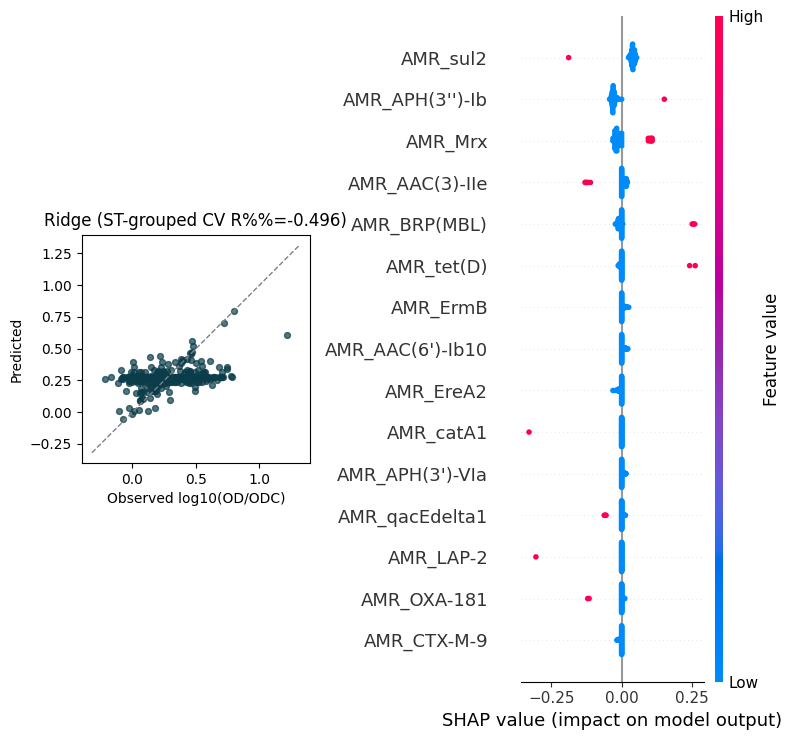

SHAP summary saved.
          model  R2_mean  R2_sd  RMSE_mean  RMSE_sd  perm_p
0         Ridge  -0.4956    0.0     0.2581      0.0  0.6965
1  RandomForest  -0.0875    0.0     0.2240      0.0     NaN
2       ST-only  -0.0466    0.0     0.2200      0.0     NaN


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# Ensure proper output directory for Step 6 exists
OUT = BASE + "results_step6/"
os.makedirs(OUT, exist_ok=True)

# ---------- final model on all data for prediction & SHAP ----------
sc = StandardScaler()
X_scaled = sc.fit_transform(X.values)
ridge.fit(X_scaled, y)
pred = ridge.predict(X_scaled)

# Predicted vs observed
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(y, pred, s=18, alpha=0.7, c="#0b3c49")
lims = [min(y.min(), pred.min())-0.1, max(y.max(), pred.max())+0.1]
ax[0].plot(lims, lims, "--", c="grey", lw=1)
ax[0].set_xlabel("Observed log10(OD/ODC)")
ax[0].set_ylabel("Predicted")
ax[0].set_title(f"Ridge (ST-grouped CV R%%={r2_r:.3f})")
ax[0].set_aspect("equal", adjustable="box")

# SHAP (KernelExplainer is slow; use a sample)
try:
    import shap
    # background sample
    bg = shap.sample(X_scaled, 50)
    explainer = shap.KernelExplainer(ridge.predict, bg)
    shap_vals = explainer.shap_values(X_scaled[:80], nsamples=100)  # 80 isolates for speed
    shap.summary_plot(shap_vals, X.iloc[:80], show=False, max_display=15)
    plt.tight_layout()
    plt.savefig(OUT + "fig_step6_shap_summary.png", dpi=200, bbox_inches="tight")
    plt.show()
    print("SHAP summary saved.")
except ImportError:
    print("Install shap (pip install shap) for SHAP plots.")
    # simple coefficient plot as fallback
    coef = pd.Series(ridge.coef_, index=X.columns).abs().sort_values(ascending=False).head(15)
    ax[1].barh(coef.index[::-1], coef.values[::-1], color="#c0392b")
    ax[1].set_xlabel("|Ridge coefficient|")
    ax[1].set_title("Top 15 features (absolute coef)")
    fig.tight_layout()
    fig.savefig(OUT + "fig_step6_pred_vs_obs.png", dpi=200)
    plt.show()

# save metrics
metrics = pd.DataFrame([
    dict(model="Ridge", R2_mean=r2_r, R2_sd=sd_r, RMSE_mean=rmse_r, RMSE_sd=sd_rmse_r, perm_p=p_perm),
    dict(model="RandomForest", R2_mean=r2_f, R2_sd=sd_f, RMSE_mean=rmse_f, RMSE_sd=sd_rmse_f, perm_p=np.nan),
    dict(model="ST-only", R2_mean=r2_st, R2_sd=sd_st, RMSE_mean=rmse_st, RMSE_sd=sd_rmse_st, perm_p=np.nan),
])
metrics.to_csv(OUT + "step6_prediction_metrics.csv", index=False)
print(metrics.round(4))

# STEP 7 – Robustness & power simulation
# Spike-in known effects, sensitivity across subsets & lineage definitions

In [ ]:
def spike_power(X, y, groups, effect_size=0.15, n_spike=5, n_sim=100, n_splits=5):
    """
    Randomly choose n_spike features, add a known effect of size `effect_size`
    (in log10 OD units) to the carriers, then measure recovery rate
    (fraction of simulations in which the spiked feature is among the top 10
    by absolute coefficient).
    """
    n_feat = X.shape[1]
    recovery = []
    for sim in range(n_sim):
        y_sim = y.copy()
        spiked = rng.choice(n_feat, size=n_spike, replace=False)
        for f in spiked:
            carriers = X[:, f] > 0.5
            y_sim[carriers] += effect_size
        # fit Ridge on whole data (fast power estimate)
        sc = StandardScaler()
        Xs = sc.fit_transform(X)
        model = Ridge(alpha=1.0).fit(Xs, y_sim)
        top = np.argsort(np.abs(model.coef_))[::-1][:10]
        recovery.append(len(set(spiked) & set(top)) / n_spike)
    return np.mean(recovery)

Effect 0.05 → power 0.17
Effect 0.10 → power 0.22
Effect 0.15 → power 0.28
Effect 0.20 → power 0.32
Effect 0.25 → power 0.40
Effect 0.30 → power 0.47


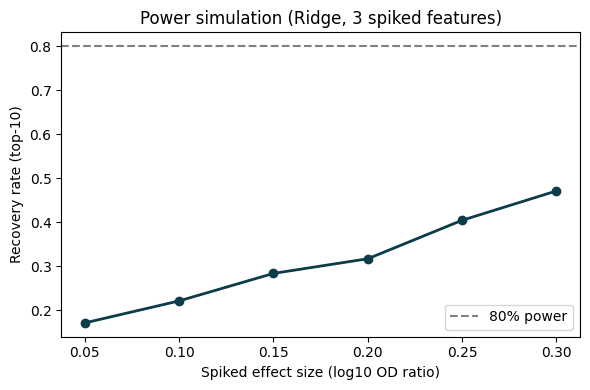

In [ ]:
# ---------- power curve (vary effect size) ----------
effect_sizes = np.linspace(0.05, 0.30, 6)
power_curve = []
for es in effect_sizes:
    pwr = spike_power(X.values, y, groups, effect_size=es, n_spike=3, n_sim=80)
    power_curve.append(dict(effect_size=es, power=pwr))
    print(f"Effect {es:.2f} → power {pwr:.2f}")
power_df = pd.DataFrame(power_curve)
power_df.to_csv(OUT + "step7_power_curve.csv", index=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(power_df.effect_size, power_df.power, "o-", c="#0b3c49", lw=2)
ax.axhline(0.8, ls="--", c="grey", label="80% power")
ax.set_xlabel("Spiked effect size (log10 OD ratio)")
ax.set_ylabel("Recovery rate (top-10)")
ax.set_title("Power simulation (Ridge, 3 spiked features)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT + "fig_step7_power_curve.png", dpi=200)
plt.show()

In [ ]:
# ---------- sensitivity across subsets & lineage definitions ----------
def run_sensitivity(name, mask, group_col="st_grp"):
    """Quick Ridge CV on a subset."""
    Xm = X.loc[mask].values
    ym = y[mask]
    gm = c.loc[mask, group_col].values
    if len(np.unique(gm)) < 5:
        return dict(subset=name, n=mask.sum(), R2=np.nan, note="too few groups")
    r2, sd, _, _ = grouped_cv_score(Ridge(alpha=1.0), Xm, ym, gm, n_repeats=10)
    return dict(subset=name, n=int(mask.sum()), R2_mean=r2, R2_sd=sd)

sens = []
# 1. All isolates
sens.append(run_sensitivity("All", np.ones(n, dtype=bool)))
# 2. Moderate + Strong only
ms = c.cat_final.isin(["Moderate", "Strong"]).values
sens.append(run_sensitivity("Moderate+Strong", ms))
# 3. Alternative lineage: PopPUNK
if "PopPUNK" in c.columns:
    sens.append(run_sensitivity("PopPUNK groups", np.ones(n, dtype=bool), group_col="PopPUNK"))
# 4. Drop rare STs (keep only ST with ≥5 isolates)
st_counts = c.st_grp.value_counts()
common_st = c.st_grp.isin(st_counts[st_counts >= 5].index).values
sens.append(run_sensitivity("Common ST (≥5)", common_st))

sens_df = pd.DataFrame(sens)
sens_df.to_csv(OUT + "step7_sensitivity_summary.csv", index=False)
print("\nSensitivity summary:")
print(sens_df.round(3))

print("\nAll step-6/7 results written to", OUT)


Sensitivity summary:
            subset    n  R2_mean  R2_sd
0              All  307   -0.496    0.0
1  Moderate+Strong  121   -1.362    0.0
2   PopPUNK groups  307   -0.469    0.0
3   Common ST (≥5)  125   -0.861    0.0

All step-6/7 results written to /content/results_step6/


# Steps 6 and 7, plus the Salmonella-paper method adapted to biofilm

**Step 6:** host-cell phenotypes (CellDeath, IFN, NFkB, Survival) vs biofilm.
**Step 7:** can genomic features *predict* biofilm? (a) variance explained by each feature type, (b) out-of-sample prediction with a mixed-model BLUP, (c) random forest + SHAP.
**Part C:** the Dottorini/Baker *Salmonella* pipeline adapted to a continuous outcome: a joint ridge-penalised mixed model, lineage-grouped cross-validation repeated many times, feature selection by effect size and **stability across folds**, and (new) a **permutation null** that shows how many features would pass these rules by chance.

**Outcome:** y = log10(OD / plate ODC), 307 isolates. Plate is a random effect everywhere; cross-validation folds are grouped by ST so a test isolate never has a training isolate of the same ST.

**Files in Drive folder `biofilm_analysis`:** `biofilm_clean_table_v2.csv`, `MRC_metadata_526samples__1_.xlsx`, `Prophageanalysis.xlsx`, `gene_presence_absence_matrix.csv`, `core_genome_snps.csv`. Runtime → Run all (about 15 to 25 minutes with the default settings).

## 1. Settings

In [ ]:
# ============================================================
# Configuration – local files only (no Google Drive required)
# ============================================================

USE_DRIVE = False               # Always use local /content/ (no Drive mount)
DRIVE_FOLDER = "biofilm_analysis"   # ignored when USE_DRIVE = False
USE_SNP = True                  # build a SNP relatedness kernel (adds ~2 min); False skips it
N_REPEATS_CV = 3                # repeats of 5-fold ST-grouped CV in step 7b/7c
N_PERM_BLUP = 50                # within-plate permutations for the BLUP models (raise to 200+ for the final run)
RF_TREES, N_PERM_RF = 200, 10   # random forest size and permutations (raise N_PERM_RF to 50+ for the final run)
N_TRIALS_C, N_PERM_C = 20, 50   # part C: CV trials (paper used 50) and permutations for the null
EFFECT_MIN = 0.03               # part C: minimum |effect| in log10 OD-ratio units (analogue of the paper's OR >= 2)
STABILITY_MIN = 0.80            # part C: same sign in >= 80% of folds (as in the paper)
MIN_FREQ = 0.05
MIN_PHAGE_N = 10
N_SNP_GRM = 50000
BIN_RATIO = 2.0                 # OD/ODC >= 2 counts as "high" for the optional AUC

import os

# Always use local storage
BASE = "/content/"
OUT = BASE + "results_steps6_7/"
os.makedirs(OUT, exist_ok=True)

FILES = dict(
    clean = "biofilm_clean_table_v2.csv",
    mrc   = "MRC_metadata_526samples (1).xlsx",
    proph = "Prophageanalysis.xlsx",
    gene  = "gene_presence_absence_matrix.csv",
    snp   = "core_genome_snps.csv"
)

print("Checking files in:", BASE)
for k, f in FILES.items():
    path = BASE + f
    status = "OK" if os.path.exists(path) else "MISSING  <-- upload it to /content/"
    print(f"{f:45s} {status}")

# Optional: install shap if missing
try:
    import shap
except ImportError:
    get_ipython().system("pip -q install shap")
    import shap

Checking files in: /content/
biofilm_clean_table_v2.csv                    OK
MRC_metadata_526samples (1).xlsx              OK
Prophageanalysis.xlsx                         OK
gene_presence_absence_matrix.csv              OK
core_genome_snps.csv                          OK


## 2. Load data, helper functions and the null mixed model (plate + ST)

In [ ]:
import numpy as np, pandas as pd, warnings, time
from scipy import stats, linalg, optimize
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestRegressor
from statsmodels.stats.multitest import multipletests
import matplotlib; import matplotlib.pyplot as plt
warnings.filterwarnings("ignore"); rng = np.random.default_rng(1)
c = pd.read_csv(BASE + FILES["clean"]); c["genome"] = c.genome.astype(str).str.strip(); n = len(c); y = np.log10(c.OD_ratio.values)
plate = (c.Trial.astype(str) + "_p" + c.Plate.astype(int).astype(str)).to_numpy(); st = c.ST_base.where(c.ST_base.notna(), "noST_" + c.genome).astype(str).to_numpy()
ybin = (c.OD_ratio.values >= BIN_RATIO).astype(int)
same = lambda a: (a[:, None] == a[None, :]).astype(float); P_plate, P_st = same(plate), same(st)

def reml_fit(y, kernels, names, x0=None, starts=4):
    ys = (y - y.mean()) / y.std(); one = np.ones(len(y)); I = np.eye(len(y)); kern = kernels + [I]
    def nll(logv):
        V = sum(np.exp(l) * Kk for l, Kk in zip(logv, kern)) + 1e-8 * I
        try: Lc = linalg.cho_factor(V, lower=True)
        except Exception: return 1e10
        Vi1 = linalg.cho_solve(Lc, one); Viy = linalg.cho_solve(Lc, ys); A = one @ Vi1; Py = Viy - Vi1 * (one @ Viy) / A
        return 0.5 * (2 * np.log(np.diag(Lc[0])).sum() + np.log(A) + ys @ Py)
    best = None
    for s in range(1 if x0 is not None else starts):
        xs = np.log(np.maximum(np.asarray(x0) / y.var(ddof=0), 1e-6)) if x0 is not None else np.log(np.full(len(kern), 0.25)) + (rng.normal(0, 1, len(kern)) if s else 0)
        r = optimize.minimize(nll, xs, method="L-BFGS-B", bounds=[(-12, 2)] * len(kern))
        if best is None or r.fun < best.fun: best = r
    return dict(zip(names + ["residual"], np.exp(best.x) * y.var(ddof=0)))

def whitener(V):
    lam, Q = np.linalg.eigh(V); return (Q * np.maximum(lam, 1e-10) ** -0.5) @ Q.T

def gls_scan(yv, X, V):
    """GLS test of each column of X against yv given covariance V (intercept included)"""
    m = len(yv); W = whitener(V); yw = W @ yv; ow = W @ np.ones(m); h = ow / np.linalg.norm(ow); yr = yw - h * (h @ yw)
    Xw = W @ X; Xr = Xw - np.outer(h, h @ Xw); sxx = (Xr ** 2).sum(0)
    beta = (Xr.T @ yr) / np.where(sxx > 0, sxx, np.nan); rss = (yr @ yr) - beta ** 2 * sxx; se = np.sqrt(rss / (m - 2) / sxx)
    return pd.DataFrame({"effect": beta, "se": se, "p": 2 * stats.t.sf(np.abs(beta / se), m - 2)})

vc0 = reml_fit(y, [P_plate, P_st], ["plate", "ST (lineage)"]); print({k: round(v / sum(vc0.values()), 3) for k, v in vc0.items()})
V0 = P_plate * vc0["plate"] + P_st * vc0["ST (lineage)"] + np.eye(n) * vc0["residual"]

{'plate': np.float64(0.179), 'ST (lineage)': np.float64(0.0), 'residual': np.float64(0.821)}


## 3. Step 6: host-cell phenotypes vs biofilm
Tested with the same mixed model (plate + ST), on the isolates that have each phenotype. IFN has only 36 isolates, so treat it as exploratory. Ordinal phenotypes (Low/Medium/High) are scored 0/1/2 for a trend test and also compared with Kruskal-Wallis.

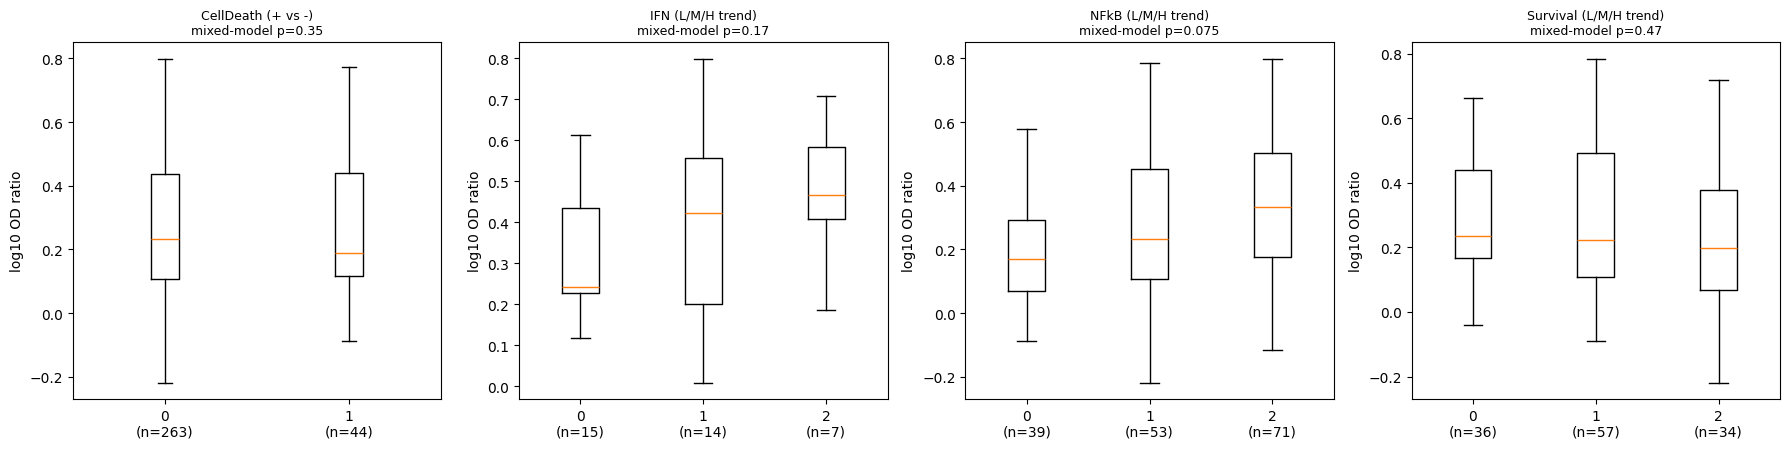

             phenotype   n  effect_per_step     se  p_mixed_model  spearman_rho  p_spearman  p_KW_or_MWU         levels      q
    CellDeath (+ vs -) 307           0.0311 0.0334         0.3531       -0.0101      0.8605       0.8609     0:263/1:44 0.4708
     IFN (L/M/H trend)  36           0.0605 0.0435         0.1730        0.2384      0.1614       0.3511  0:15/1:14/2:7 0.3459
    NFkB (L/M/H trend) 163           0.0451 0.0251         0.0750        0.2620      0.0007       0.0033 0:39/1:53/2:71 0.2998
Survival (L/M/H trend) 127          -0.0207 0.0288         0.4727       -0.1208      0.1762       0.3015 0:36/1:57/2:34 0.4727


In [ ]:
M = pd.read_excel(BASE + FILES["mrc"]); M["genome"] = M.isolate.astype(str).str.strip()
d = c[["genome"]].merge(M[["genome", "CellDeath", "IFN", "NFkB", "Survival"]], on="genome", how="left")
om = {"Low": 0, "Medium": 1, "High": 2}
phen = {"CellDeath (+ vs -)": (d.CellDeath.map({"-": 0, "+": 1})), "IFN (L/M/H trend)": d.IFN.map(om), "NFkB (L/M/H trend)": d.NFkB.map(om), "Survival (L/M/H trend)": d.Survival.map(om)}
rows = []; fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
for a, (nm, x) in zip(ax, phen.items()):
    ok = x.notna().values; xv = x.values[ok].astype(float); yv = y[ok]; V = V0[np.ix_(ok, ok)]
    r = gls_scan(yv, xv[:, None], V).iloc[0]; rho, prho = stats.spearmanr(xv, yv)
    groups = [yv[xv == k] for k in np.unique(xv)]; kwp = stats.kruskal(*groups)[1] if len(groups) > 2 else stats.mannwhitneyu(*groups)[1]
    rows.append(dict(phenotype=nm, n=int(ok.sum()), effect_per_step=r.effect, se=r.se, p_mixed_model=r.p, spearman_rho=rho, p_spearman=prho, p_KW_or_MWU=kwp,
                     levels="/".join(f"{int(k)}:{(xv==k).sum()}" for k in np.unique(xv))))
    a.boxplot(groups, showfliers=False); a.set_xticks(range(1, len(groups) + 1)); a.set_xticklabels([f"{int(k)}\n(n={len(g)})" for k, g in zip(np.unique(xv), groups)])
    a.set_title(f"{nm}\nmixed-model p={r.p:.2g}", fontsize=9); a.set_ylabel("log10 OD ratio")
r6 = pd.DataFrame(rows); r6["q"] = multipletests(r6.p_mixed_model, method="fdr_bh")[1]; r6.to_csv(OUT + "step6_host_phenotype_results.csv", index=False)
fig.tight_layout(); fig.savefig(OUT + "fig_step6_host_phenotypes.png", dpi=200); plt.show(); print(r6.round(4).to_string(index=False))

## 4. Feature matrices and kernels (prophages, AMR genes, accessory genes, SNPs)

In [ ]:
def dedupe_rows(M):
    pk = np.ascontiguousarray(np.packbits(M.astype(np.uint8), axis=1)); v = pk.view(np.dtype((np.void, pk.shape[1]))).ravel()
    _, first = np.unique(v, return_index=True); return np.sort(first)
# prophage types
pw = pd.read_excel(BASE + FILES["proph"], sheet_name="intact_prophages"); pw["genome"] = pw.Sample.astype(str).str.strip(); pw = pw[pw.genome.isin(c.genome)]
pw["phage"] = "phage:" + pw.phage.str.replace("PHAGE_", "", regex=False)
PH = pd.crosstab(pw.genome, pw.phage).clip(upper=1).reindex(c.genome).fillna(0); PH = PH.loc[:, (PH.sum() >= MIN_PHAGE_N) & ((n - PH.sum()) >= MIN_PHAGE_N)]
# genes
g = pd.read_csv(BASE + FILES["gene"], low_memory=False); cols = {x.replace("_assembly", ""): x for x in g.columns[5:]}
G = g[[cols[i] for i in c.genome]].to_numpy().astype(np.int8); fg = G.mean(1); kg = (fg >= MIN_FREQ) & (fg <= 1 - MIN_FREQ)
Gk, gm = G[kg], g.loc[kg].reset_index(drop=True); first = dedupe_rows(Gk); Gu, gm = Gk[first], gm.iloc[first].reset_index(drop=True)
gname = np.where(gm["Non-unique Gene name"].notna(), gm["Non-unique Gene name"].astype(str).str.strip(";"), gm["Gene"].astype(str))
gnames = np.array([f"{a} [{b}]" if a != b else a for a, b in zip(gname, gm["Gene"].astype(str))])
is_amr = gm["Known AMR Gene"].notna().values
print(f"{PH.shape[1]} phage types | {len(Gu)} distinct accessory-gene patterns ({is_amr.sum()} are AMR genes)")
FEATS = {"prophages": (PH.values.astype(float), list(PH.columns)), "AMR genes": (Gu[is_amr].T.astype(float), list(gnames[is_amr])),
         "accessory genes": (Gu.T.astype(float), list(gnames))}
def kernel(X):
    Z = (X - X.mean(0)) / np.where(X.std(0) > 0, X.std(0), 1); Kx = Z @ Z.T / Z.shape[1]; return Kx / np.mean(np.diag(Kx))
KER = {k: kernel(v[0]) for k, v in FEATS.items()}
if USE_SNP:
    t0 = time.time(); hdr = pd.read_csv(BASE + FILES["snp"], nrows=0).columns.tolist()
    # Load as float32 to support missing values (NaN) gracefully
    snp = pd.read_csv(BASE + FILES["snp"], usecols=[hdr[0]] + list(c.genome), dtype={k: np.float32 for k in c.genome}, index_col=0)
    # Fill missing values with 0 and convert to boolean mask
    B = (snp[c.genome.values].fillna(0).values != 0); del snp; fb = B.mean(1); B = B[(fb >= MIN_FREQ) & (fb <= 1 - MIN_FREQ)]
    sub = B[rng.choice(len(B), min(N_SNP_GRM, len(B)), replace=False)].astype(np.float32); Z = (sub - sub.mean(1, keepdims=True)) / sub.std(1, keepdims=True)
    Ks = (Z.T @ Z).astype(float) / Z.shape[0]; KER["core SNPs"] = Ks / np.mean(np.diag(Ks)); del B, sub, Z; print(f"SNP kernel built in {time.time() - t0:.0f}s")

23 phage types | 2356 distinct accessory-gene patterns (13 are AMR genes)
SNP kernel built in 1s


## 5. Step 7a: how much biofilm variance does each feature type explain?
Each kernel is added to the plate and ST random effects and its share of the total variance is estimated by REML (this is the analogue of the ICCs in the Salmonella paper). A share near 0 means the feature type carries no usable information about biofilm.

                       model  plate  ST  feature_kernel  residual
      plate + ST + prophages  0.179 0.0             0.0     0.821
      plate + ST + AMR genes  0.179 0.0             0.0     0.821
plate + ST + accessory genes  0.179 0.0             0.0     0.821
      plate + ST + core SNPs  0.179 0.0             0.0     0.821
        all kernels together  0.179 0.0             0.0     0.821


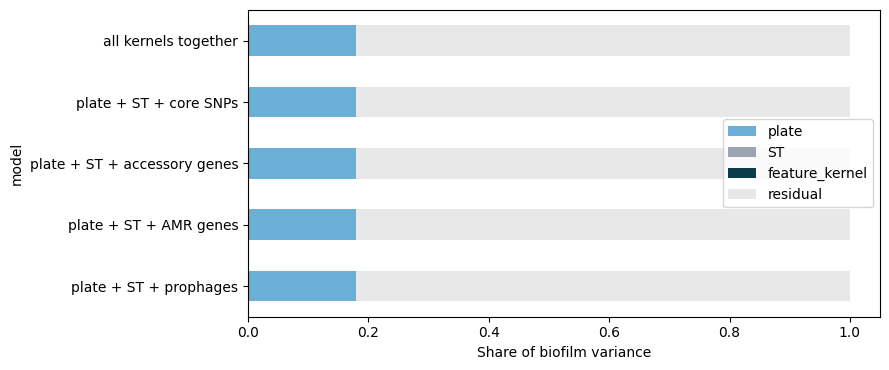

In [ ]:
rows = []
for k, Kk in KER.items():
    v = reml_fit(y, [P_plate, P_st, Kk], ["plate", "ST (lineage)", k]); tot = sum(v.values())
    rows.append(dict(model=f"plate + ST + {k}", plate=v["plate"] / tot, ST=v["ST (lineage)"] / tot, feature_kernel=v[k] / tot, residual=v["residual"] / tot))
vj = reml_fit(y, [P_plate, P_st] + list(KER.values()), ["plate", "ST (lineage)"] + list(KER)); tot = sum(vj.values())
rows.append(dict(model="all kernels together", plate=vj["plate"] / tot, ST=vj["ST (lineage)"] / tot, feature_kernel=sum(vj[k] for k in KER) / tot, residual=vj["residual"] / tot))
r7a = pd.DataFrame(rows); r7a.to_csv(OUT + "step7a_variance_shares.csv", index=False); print(r7a.round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.8)); r7a.set_index("model")[["plate", "ST", "feature_kernel", "residual"]].plot(kind="barh", stacked=True, ax=ax, color=["#6baed6", "#9aa5b1", "#0b3c49", "#e8e8e8"])
ax.set_xlabel("Share of biofilm variance"); fig.tight_layout(); fig.savefig(OUT + "fig_step7a_variance_shares.png", dpi=200); plt.show()

## 6. Step 7b: out-of-sample prediction (mixed-model BLUP, ST-grouped CV)
The baseline model knows only the plate. Each genomic model adds one feature kernel. Variance components are re-estimated inside every training fold. R² and Spearman are computed on held-out isolates; **ΔR² vs baseline** is the real measure of what the genomics adds. The p-value comes from shuffling biofilm values *within plates* (variance components are held at the full-data estimates for the shuffles to keep it fast).

CV done in 31s
                             R2  spearman  AUC_high_vs_low  delta_R2_vs_baseline  perm_p_delta_R2
baseline (plate only)    0.1246    0.3569           0.7005                   0.0              NaN
plate + prophages        0.1246    0.3569           0.7009                   0.0           0.3922
plate + AMR genes        0.1246    0.3565           0.7005                  -0.0           0.7255
plate + accessory genes  0.1246    0.3551           0.6999                  -0.0           0.8431
plate + core SNPs        0.1246    0.3574           0.7011                  -0.0           0.5098
plate + all genomic      0.1246    0.3566           0.7009                  -0.0           0.6863


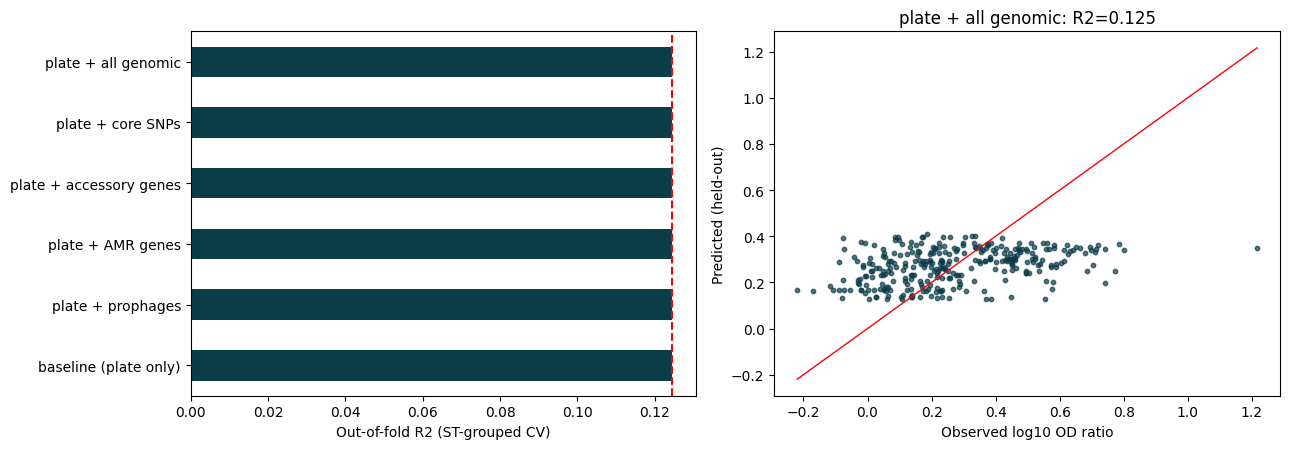

In [ ]:
def make_folds(groups, k=5, seed=0):
    r = np.random.default_rng(seed); ug = np.unique(groups); r.shuffle(ug); sz = {u: (groups == u).sum() for u in ug}
    fold_of = {}; load = np.zeros(k)
    for u in sorted(ug, key=lambda u: -sz[u] + r.random() * 0.1): f = int(np.argmin(load)); fold_of[u] = f; load[f] += sz[u]
    return np.array([fold_of[g_] for g_ in groups])
def blup(tr, te, yv, comps, kerns):
    Vtr = sum(comps[i] * kerns[i][np.ix_(tr, tr)] for i in range(len(kerns))) + comps[-1] * np.eye(len(tr))
    Vte = sum(comps[i] * kerns[i][np.ix_(te, tr)] for i in range(len(kerns))); Vi1 = np.linalg.solve(Vtr, np.ones(len(tr)))
    mu = (Vi1 @ yv[tr]) / Vi1.sum(); return mu + Vte @ np.linalg.solve(Vtr, yv[tr] - mu)
def r2(yt, yp): return 1 - ((yt - yp) ** 2).sum() / ((yt - yt.mean()) ** 2).sum()
MODELS = {"baseline (plate only)": []} | {f"plate + {k}": [k] for k in KER} | {"plate + all genomic": list(KER)}
def cv_run(yv, refit=True, repeats=1, fixed=None, seed0=0):
    out = {m: [] for m in MODELS}
    for rep in range(repeats):
        fold = make_folds(st, 5, seed0 + rep); pred = {m: np.zeros(n) for m in MODELS}
        for f in range(5):
            te = np.where(fold == f)[0]; tr = np.where(fold != f)[0]
            for m, ks in MODELS.items():
                kerns = [P_plate] + [KER[k] for k in ks]
                if refit:
                    x0 = [fixed[m][i] for i in range(len(kerns) + 1)]; comps = list(reml_fit(yv[tr], [kk[np.ix_(tr, tr)] for kk in kerns], ["p"] + ks, x0=x0).values())
                else: comps = fixed[m]
                pred[m][te] = blup(tr, te, yv, comps, kerns)
        for m in MODELS: out[m].append(pred[m])
    return out
fixed = {}
for m, ks in MODELS.items():
    kerns = [P_plate] + [KER[k] for k in ks]; fixed[m] = list(reml_fit(y, kerns, ["p"] + ks).values())
t0 = time.time(); oof = cv_run(y, True, N_REPEATS_CV, fixed); print(f"CV done in {time.time() - t0:.0f}s")
def summarize(oof, yv, yb):
    rows = {}
    for m in MODELS:
        rows[m] = dict(R2=np.mean([r2(yv, p) for p in oof[m]]), spearman=np.mean([stats.spearmanr(yv, p)[0] for p in oof[m]]),
                       AUC_high_vs_low=np.mean([roc_auc_score(yb, p) for p in oof[m]]))
    return pd.DataFrame(rows).T
res = summarize(oof, y, ybin); res["delta_R2_vs_baseline"] = res.R2 - res.loc["baseline (plate only)", "R2"]
# permutation null (shuffle within plates)
def perm_within_plate():
    yp = y.copy()
    for pl in np.unique(plate): ix = np.where(plate == pl)[0]; yp[ix] = y[rng.permutation(ix)]
    return yp
null = {m: [] for m in MODELS}
for b in range(N_PERM_BLUP):
    yp = perm_within_plate(); o = cv_run(yp, False, 1, fixed, seed0=100 + b); s = summarize(o, yp, ybin)
    for m in MODELS: null[m].append(s.loc[m, "R2"] - s.loc["baseline (plate only)", "R2"])
res["perm_p_delta_R2"] = [(1 + np.sum(np.array(null[m]) >= res.loc[m, "delta_R2_vs_baseline"])) / (N_PERM_BLUP + 1) if m != "baseline (plate only)" else np.nan for m in MODELS]
res.to_csv(OUT + "step7b_prediction_results.csv"); print(res.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6)); res.R2.plot(kind="barh", ax=ax[0], color="#0b3c49"); ax[0].set_xlabel("Out-of-fold R2 (ST-grouped CV)"); ax[0].axvline(res.loc["baseline (plate only)", "R2"], ls="--", c="red")
best = "plate + all genomic"; ax[1].scatter(y, np.mean(oof[best], 0), s=10, c="#0b3c49", alpha=.7); ax[1].plot([y.min(), y.max()], [y.min(), y.max()], c="red", lw=1)
ax[1].set_xlabel("Observed log10 OD ratio"); ax[1].set_ylabel("Predicted (held-out)"); ax[1].set_title(f"{best}: R2={res.loc[best, 'R2']:.3f}")
fig.tight_layout(); fig.savefig(OUT + "fig_step7b_prediction.png", dpi=200); plt.show()

## 7. Step 7c: random forest + SHAP
A random forest on prophage types + accessory genes (the same features, in their original form). The target is biofilm minus the training plate mean, so the forest only has to learn the genomic part. Same ST-grouped folds, same baseline, and a within-plate permutation test.

RF CV done in 12s
                                      model     R2  delta_R2_vs_baseline  spearman  AUC_high_vs_low  perm_p  n_perm
random forest (prophages + accessory genes) 0.0727               -0.0421    0.3345           0.6947     1.0      10
                       feature  mean_abs_shap
         tnp;insB [group_9010]        0.00124
              tnp [group_7426]        0.00083
              tnp [group_9380]        0.00081
            dppC [group_17650]        0.00068
              tnp [group_1958]        0.00066
                    group_2090        0.00063
phage:Klebsi_3LV2017_NC_047817        0.00059
                   group_12962        0.00059
             fimD [group_3532]        0.00058
               tnp [group_270]        0.00057
             alpA [group_7848]        0.00056
             araD [group_6779]        0.00055
             oadG [group_9775]        0.00054
                    group_5395        0.00054
              tnp [group_4514]        0.00054


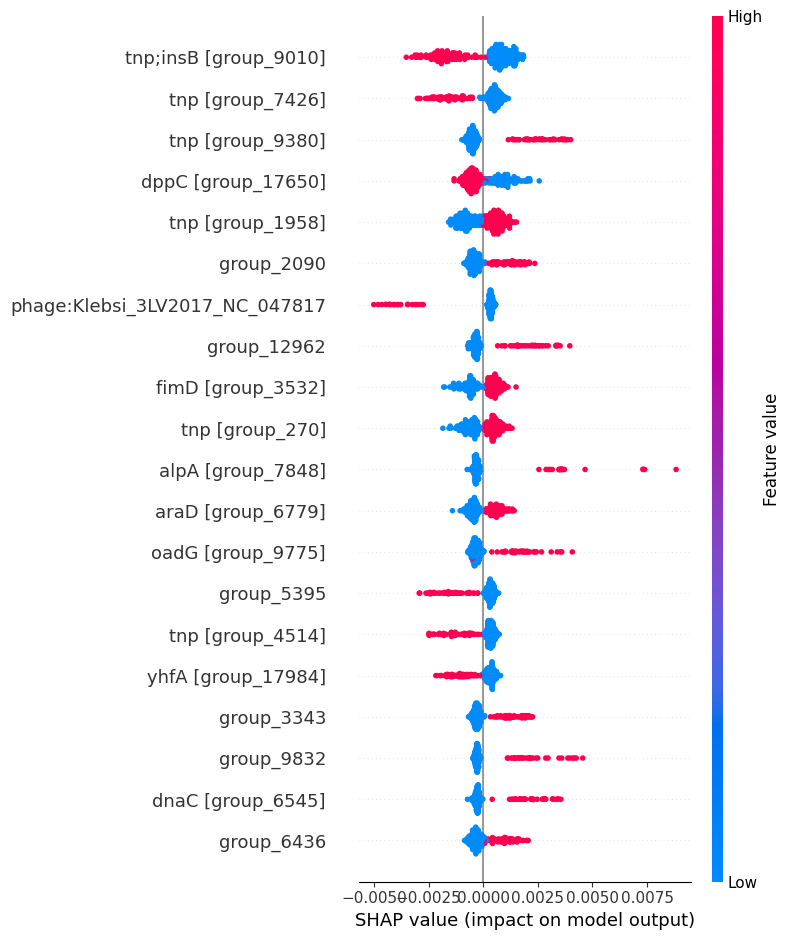

In [ ]:
XA = np.hstack([FEATS["prophages"][0], FEATS["accessory genes"][0]]); XA_names = FEATS["prophages"][1] + FEATS["accessory genes"][1]
def rf_cv(yv, repeats=1, seed0=0, trees=RF_TREES):
    preds, base = [], []
    for rep in range(repeats):
        fold = make_folds(st, 5, seed0 + rep); p = np.zeros(n); b = np.zeros(n)
        for f in range(5):
            te = np.where(fold == f)[0]; tr = np.where(fold != f)[0]
            pm = pd.Series(yv[tr]).groupby(plate[tr]).mean(); gm_ = yv[tr].mean(); off_tr = pd.Series(plate[tr]).map(pm).values; off_te = pd.Series(plate[te]).map(pm).fillna(gm_).values
            rf = RandomForestRegressor(trees, max_features="sqrt", min_samples_leaf=3, n_jobs=-1, random_state=int(seed0 + rep)).fit(XA[tr], yv[tr] - off_tr)
            p[te] = off_te + rf.predict(XA[te]); b[te] = off_te
        preds.append(p); base.append(b)
    return np.mean([r2(yv, p) - r2(yv, b) for p, b in zip(preds, base)]), np.mean([r2(yv, p) for p in preds]), np.mean([stats.spearmanr(yv, p)[0] for p in preds]), \
           np.mean([roc_auc_score(ybin, p) for p in preds]), preds
t0 = time.time(); d_obs, r2_rf, rho_rf, auc_rf, rf_preds = rf_cv(y, N_REPEATS_CV); print(f"RF CV done in {time.time() - t0:.0f}s")
nullrf = [rf_cv(perm_within_plate(), 1, 500 + b)[0] for b in range(N_PERM_RF)]
p_rf = (1 + np.sum(np.array(nullrf) >= d_obs)) / (N_PERM_RF + 1)
r7c = pd.DataFrame([dict(model="random forest (prophages + accessory genes)", R2=r2_rf, delta_R2_vs_baseline=d_obs, spearman=rho_rf, AUC_high_vs_low=auc_rf, perm_p=p_rf, n_perm=N_PERM_RF)])
r7c.to_csv(OUT + "step7c_random_forest_results.csv", index=False); print(r7c.round(4).to_string(index=False))
# SHAP on a forest fitted to all data
off = pd.Series(plate).map(pd.Series(y).groupby(plate).mean()).values
rf_all = RandomForestRegressor(RF_TREES * 2, max_features="sqrt", min_samples_leaf=3, n_jobs=-1, random_state=1).fit(XA, y - off)
sv = shap.TreeExplainer(rf_all).shap_values(XA); imp = pd.DataFrame({"feature": XA_names, "mean_abs_shap": np.abs(sv).mean(0)}).sort_values("mean_abs_shap", ascending=False)
imp.to_csv(OUT + "step7c_shap_importance.csv", index=False); print(imp.head(15).round(5).to_string(index=False))
top = imp.head(20).feature.tolist(); idx = [XA_names.index(t) for t in top]
plt.figure(); shap.summary_plot(sv[:, idx], XA[:, idx], feature_names=[t[:35] for t in top], show=False, max_display=20); plt.tight_layout()
plt.savefig(OUT + "fig_step7c_shap_summary.png", dpi=200, bbox_inches="tight"); plt.show()

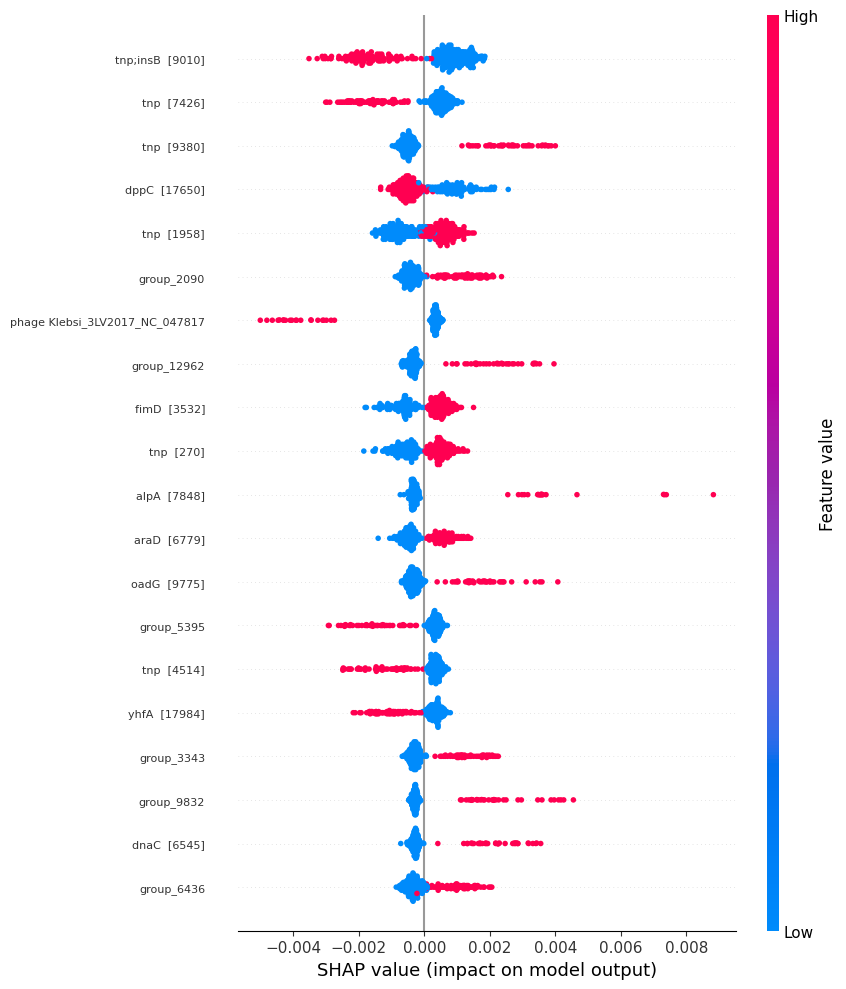

In [ ]:
# 1. Make the figure taller and a bit wider
plt.figure(figsize=(11, 10))          # height is the important part

# 2. Truncate names a bit more aggressively and clean them
clean_names = []
for t in top:
    name = t.replace("phage:", "phage ").replace("[group_", " [")
    clean_names.append(name[:32] + "…" if len(name) > 32 else name)

# 3. Plot
shap.summary_plot(
    sv[:, idx],
    XA[:, idx],
    feature_names=clean_names,
    show=False,
    max_display=20,
    plot_size=None          # we already set figsize
)

# 4. Extra spacing + smaller font
plt.yticks(fontsize=8)
plt.tight_layout()
plt.subplots_adjust(left=0.42)   # give more room for the long y-labels

plt.savefig(OUT + "fig_step7c_shap_summary.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Part C: the Salmonella-paper pipeline adapted to biofilm
**What is kept from the paper:** one joint model with all features and a Gaussian (ridge) prior on their effects; random effects for the sampling structure (here **plate** and **ST**, instead of province, year, host and PopPUNK cluster); lineage-grouped k-fold cross-validation repeated many times; a model-level performance gate; and feature selection by **effect size** and **stability** (same direction in at least 80% of folds).
**What is changed:** the outcome is continuous (log10 OD ratio), so effects are in log10 units instead of odds ratios and the gate is the out-of-fold R² gain over the plate-only baseline (the analogue of AUC > 0.7). Confidence intervals taken from the spread of cross-validation fits are **not used** (the fits share most training data, which makes them too narrow). Instead, the same pipeline is run on **within-plate permutations** of biofilm to count how many features would pass the rules by chance.

pipeline: 9s | R2 gain over plate-only baseline = -0.1077 (model gate NOT passed) | features passing stability + effect rules: 0
                           feature  mean_effect_log10  stability  passes_rules  model_gate_passed
   phage:Escher_500465_1_NC_049342            -0.0037        1.0         False              False
      phage:Escher_RCS47_NC_042128            -0.0031        1.0         False              False
    phage:Klebsi_3LV2017_NC_047817            -0.0007        1.0         False              False
phage:Salmon_118970_sal3_NC_031940            -0.0004        1.0         False              False
                              rsbW             0.0021        1.0         False              False
                              ihfA            -0.0008        1.0         False              False
                       group_17662             0.0011        1.0         False              False
                 ftsK [group_4430]            -0.0010        1.0         False         

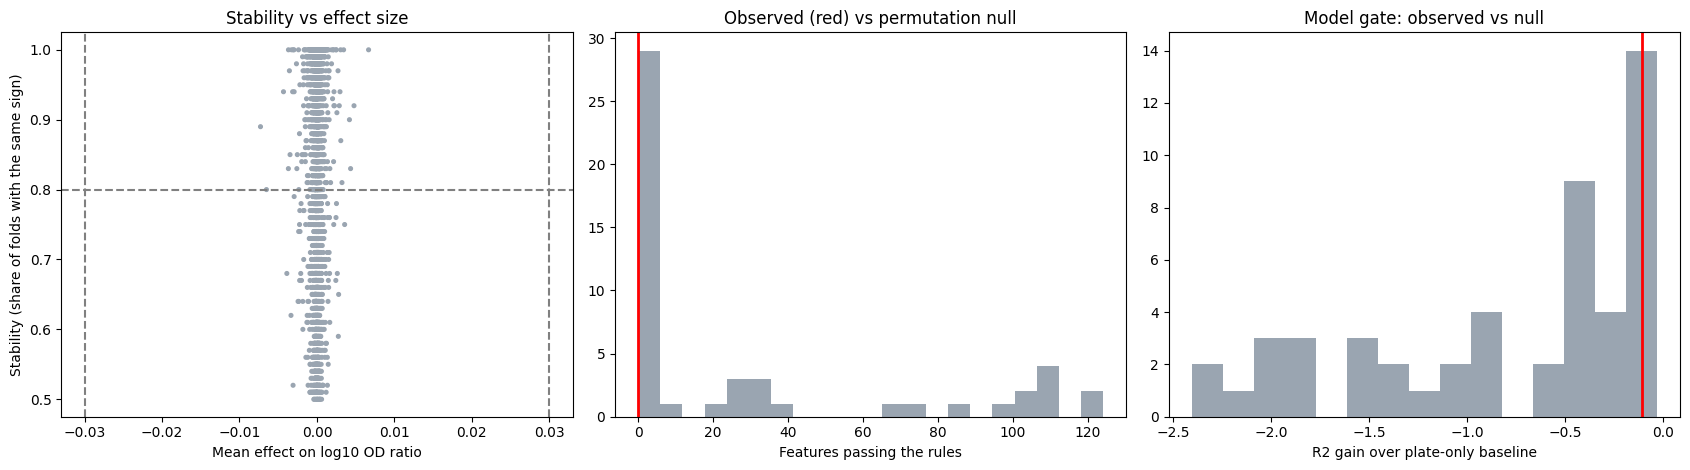

In [ ]:
XC = XA; XC_names = XA_names; sdv = XC.std(0); XC_keep = sdv > 0
def ridge_gls(Xs, yv, V, grid=np.logspace(0, 8, 33)):
    W = whitener(V); yw = W @ yv; ow = W @ np.ones(len(yv)); h = ow / np.linalg.norm(ow); yr = yw - h * (h @ yw)
    Xw = W @ Xs; Xr = Xw - np.outer(h, h @ Xw); s, U = np.linalg.eigh(Xr @ Xr.T); s = np.maximum(s, 0); Uy = U.T @ yr; best = (np.inf, None)
    for lam_ in grid:
        sh = s / (s + lam_); hat = (U ** 2) @ sh; res_ = yr - U @ (sh * Uy); gcv = np.mean((res_ / (1 - hat)) ** 2)
        if gcv < best[0]: best = (gcv, lam_)
    lam_ = best[1]; beta = Xr.T @ (U @ (Uy / (s + lam_))); mu = (ow @ (yw - Xw @ beta)) / (ow @ ow); return mu, beta
def fit_predict_ridge(tr, te, yv, Xs_all, Vfull):
    mu, beta = ridge_gls(Xs_all[tr], yv[tr], Vfull[np.ix_(tr, tr)])
    Vtr = Vfull[np.ix_(tr, tr)]; Vte = (Vfull - np.eye(n) * vc0["residual"])[np.ix_(te, tr)]
    resid = yv[tr] - mu - Xs_all[tr] @ beta; return mu + Xs_all[te] @ beta + Vte @ np.linalg.solve(Vtr, resid), beta
Xs_all = (XC - XC.mean(0)) / np.where(sdv > 0, sdv, 1)
def pipeline(yv, trials, seed0):
    betas = []; r2m, r2b = [], []
    for t in range(trials):
        fold = make_folds(st, 5, seed0 + t); pm = np.zeros(n); pb = np.zeros(n)
        for f in range(5):
            te = np.where(fold == f)[0]; tr = np.where(fold != f)[0]; p_, beta = fit_predict_ridge(tr, te, yv, Xs_all, V0)
            pm[te] = p_; betas.append(beta / np.where(sdv > 0, sdv, np.inf))                      # effect per presence, in log10 units
            Vtr = P_plate[np.ix_(tr, tr)] * vc0["plate"] + np.eye(len(tr)) * vc0["residual"]; Vte = P_plate[np.ix_(te, tr)] * vc0["plate"]
            Vi1 = np.linalg.solve(Vtr, np.ones(len(tr))); mu = (Vi1 @ yv[tr]) / Vi1.sum(); pb[te] = mu + Vte @ np.linalg.solve(Vtr, yv[tr] - mu)
        r2m.append(r2(yv, pm)); r2b.append(r2(yv, pb))
    Bm = np.array(betas); stab = np.maximum((Bm > 0).mean(0), (Bm < 0).mean(0)); mean_b = Bm.mean(0)
    return mean_b, stab, np.mean(r2m) - np.mean(r2b), np.mean(r2m)
def n_pass(mean_b, stab): return int(((stab >= STABILITY_MIN) & (np.abs(mean_b) >= EFFECT_MIN)).sum())
t0 = time.time(); mb, stb, gain, r2full = pipeline(y, N_TRIALS_C, 0); obs_pass = n_pass(mb, stb); gate = gain > 0
print(f"pipeline: {time.time() - t0:.0f}s | R2 gain over plate-only baseline = {gain:.4f} (model gate {'passed' if gate else 'NOT passed'}) | features passing stability + effect rules: {obs_pass}")
tab = pd.DataFrame({"feature": XC_names, "mean_effect_log10": mb, "stability": stb}); tab["passes_rules"] = (tab.stability >= STABILITY_MIN) & (tab.mean_effect_log10.abs() >= EFFECT_MIN)
tab["model_gate_passed"] = gate; tab = tab.sort_values(["passes_rules", "stability"], ascending=False); tab.to_csv(OUT + "partC_feature_stability.csv", index=False); print(tab.head(15).round(4).to_string(index=False))
null_pass, null_gain = [], []
for b in range(N_PERM_C):                              # same number of trials as the real run, so stability is comparable
    m_, s_, g_, _ = pipeline(perm_within_plate(), N_TRIALS_C, 1000 + 7 * b); null_pass.append(n_pass(m_, s_)); null_gain.append(g_)
p_sel = (1 + np.sum(np.array(null_pass) >= obs_pass)) / (N_PERM_C + 1); p_gain = (1 + np.sum(np.array(null_gain) >= gain)) / (N_PERM_C + 1)
print(f"observed: {obs_pass} features pass the stability + effect rules; under within-plate permutation the median is {np.median(null_pass):.0f} (95th percentile {np.percentile(null_pass, 95):.0f}); p = {p_sel:.3f}")
print(f"R2 gain over baseline: observed {gain:.4f}; permutation p = {p_gain:.3f}")
pd.DataFrame([dict(R2_full_model=r2full, R2_gain_over_plate_baseline=gain, model_gate_passed=gate, perm_p_gain=p_gain, features_passing_rules=obs_pass, null_median=np.median(null_pass), null_p95=np.percentile(null_pass, 95), perm_p_selection=p_sel, trials=N_TRIALS_C, permutations=N_PERM_C)]).to_csv(OUT + "partC_summary.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].scatter(tab.mean_effect_log10, tab.stability, s=7, c=np.where(tab.passes_rules, "#c0392b", "#9aa5b1")); ax[0].axhline(STABILITY_MIN, ls="--", c="grey"); ax[0].axvline(EFFECT_MIN, ls="--", c="grey"); ax[0].axvline(-EFFECT_MIN, ls="--", c="grey")
ax[0].set_xlabel("Mean effect on log10 OD ratio"); ax[0].set_ylabel("Stability (share of folds with the same sign)"); ax[0].set_title("Stability vs effect size")
ax[1].hist(null_pass, bins=min(30, max(5, len(set(null_pass + [obs_pass])))), color="#9aa5b1"); ax[1].axvline(obs_pass, c="red", lw=2); ax[1].set_xlabel("Features passing the rules"); ax[1].set_title("Observed (red) vs permutation null")
ax[2].hist(null_gain, bins=15, color="#9aa5b1"); ax[2].axvline(gain, c="red", lw=2); ax[2].set_xlabel("R2 gain over plate-only baseline"); ax[2].set_title("Model gate: observed vs null")
fig.tight_layout(); fig.savefig(OUT + "fig_partC_stability_and_null.png", dpi=200); plt.show()

In [ ]:
"""
Two-panel network figure in the style of Fig. 2 of the Salmonella AMR forecasting paper
(Nature Communications 2026, 17:10744).

  a  trait nodes  <->  group "hub" nodes (silver circles, sized by number of members).
     Edge colour + thickness = number of individual items behind the link (1..12+ colour bar).
     Trait node colour = trend class (increasing / stationary / both).
  b  trait nodes  <->  antibiotic-class hubs (silver circles, sized by number of connected traits).
     Edge colour = trend class (increasing / stationary / both).

The plotting functions are generic: give them an edge table and a node-trend table.
`demo_tables()` builds both tables from YOUR biofilm results (AMR genes, STs, effect direction),
so the script runs end to end. To use other data, replace demo_tables() with your own tables:

  edges_a : DataFrame[trait, hub, n_items]            panel a
  trend_a : dict trait -> "increasing" | "stationary" | "both"
  edges_b : DataFrame[trait, hub, trend]               panel b  (trend as above)

Usage:  python fig2_network.py --root /path/to/unzipped_results --out fig_network.png
Needs:  numpy, pandas, matplotlib, networkx
"""
import argparse, re, os
import numpy as np, pandas as pd, networkx as nx
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

# ---------------- style (matched to the paper's look) ----------------
BIN_COLORS = ["#c5cdf7", "#f6d365", "#5fe3c0", "#f7a1b1", "#8fe388", "#c8e06c",   # 1-6
              "#ffb77a", "#fba8e8", "#74dce0", "#ffb089", "#a2d8a6", "#ffb3c1"]   # 7-12
NODE_TREND = {"increasing": "#b7e4e4", "stationary": "#00c800", "both": "#d020e0"}
EDGE_TREND = {"increasing": "#c5d9f0", "stationary": "#7ac943", "both": "#c050e0", "decreasing": "#f2b8a2"}
HUB_FACE, HUB_EDGE, TRAIT_B = "#bfc5cc", "#7d838b", "#f4a460"
MAXBIN = len(BIN_COLORS)


def _layout(G, hubs, seed=3, iters=300):
    """Force-directed layout with hubs initialised on a ring so they stay apart."""
    ang = np.linspace(0, 2 * np.pi, len(hubs), endpoint=False)
    init = {h: (np.cos(a), np.sin(a)) for h, a in zip(hubs, ang)}
    rng = np.random.default_rng(seed)
    for n in G.nodes:
        if n not in init: init[n] = tuple(rng.normal(0, .4, 2))
    return nx.spring_layout(G, pos=init, k=0.55, iterations=iters, seed=seed, weight="w")


def _layout_hubs(G, hubs, radius=1.0, seed=1):
    """Hubs fixed on a ring; each trait sits near the mean of its hubs. Traits that share the same hub(s)
    are fanned out on a small circle around that point so that nothing overlaps."""
    ang = np.linspace(0, 2 * np.pi, len(hubs), endpoint=False); pos = {h: np.array([np.cos(a), np.sin(a)]) * radius for h, a in zip(hubs, ang)}
    groups = {}
    for n in G.nodes:
        if n in pos: continue
        groups.setdefault(tuple(sorted(G.neighbors(n))), []).append(n)
    for hs, members in groups.items():
        c = np.mean([pos[h] for h in hs], axis=0); c = c * (1.0 if len(hs) > 1 else 1.0)
        r = 0.10 + 0.045 * len(members)
        for i, n in enumerate(members):
            a = 2 * np.pi * i / len(members) + (hash(hs) % 7)
            out = c / (np.linalg.norm(c) + 1e-9) * (0.0 if len(hs) > 1 else 0.28)   # single-hub traits sit outside their hub
            pos[n] = c + out + r * np.array([np.cos(a), np.sin(a)])
    return pos


def _labels(ax, pos, nodes, fs, dy=-0.035, **kw):
    for n in nodes:
        x, y = pos[n]; ax.text(x, y + dy, n, fontsize=fs, ha="center", va="top", style="italic", **kw)


def plot_panel_a(ax, edges, trend, labels=None, legend_title="Indicators Trend", bar_label="Number of items"):
    labels = labels or {"increasing": "Increasing", "stationary": "Stationary", "both": "Increasing/Stationary"}
    G = nx.Graph()
    for r in edges.itertuples():
        G.add_edge(r.trait, r.hub, w=r.n_items, n=int(r.n_items))
    hubs = sorted(edges.hub.unique()); traits = [n for n in G.nodes if n not in hubs]
    pos = _layout(G, hubs)
    # edges: colour = number of items (cap at 12), thickness grows with the count
    for u, v, d in sorted(G.edges(data=True), key=lambda e: e[2]["n"]):
        k = min(d["n"], MAXBIN)
        ax.plot(*zip(pos[u], pos[v]), color=BIN_COLORS[k - 1], lw=0.5 + 0.55 * k, alpha=.9 if k > 1 else .55,
                solid_capstyle="round", zorder=1)
    # trait nodes
    ax.scatter(*zip(*[pos[t] for t in traits]), s=38, c=[NODE_TREND[trend.get(t, "increasing")] for t in traits],
               edgecolor="#5b6770", linewidth=.5, zorder=3)
    _labels(ax, pos, traits, 6.5)
    # hubs, sized by number of connected traits
    deg = {h: G.degree(h) for h in hubs}; mx = max(deg.values())
    ax.scatter(*zip(*[pos[h] for h in hubs]), s=[250 + 900 * deg[h] / mx for h in hubs], c=HUB_FACE,
               edgecolor=HUB_EDGE, linewidth=2, zorder=4)
    for h in hubs: ax.text(*pos[h], h, fontsize=9.5, ha="center", va="center", zorder=5)
    ax.set_axis_off(); ax.set_title("a", loc="left", fontweight="bold", fontsize=12)
    # legends: trend + colour bar for number of items
    ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=c, mec="#5b6770", label=labels[l])
                       for l, c in NODE_TREND.items()], title=legend_title, loc="upper left", frameon=False, fontsize=8)
    cmap = ListedColormap(BIN_COLORS); norm = BoundaryNorm(np.arange(.5, MAXBIN + 1.5), cmap.N)
    ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=c, mec="#5b6770", label=labels[l])
                       for l, c in NODE_TREND.items()], title=legend_title, loc="upper left", frameon=False, fontsize=8)
    cmap = ListedColormap(BIN_COLORS); norm = BoundaryNorm(np.arange(.5, MAXBIN + 1.5), cmap.N)
    cax = ax.inset_axes([0.0, 0.18, 0.025, 0.4])
    cb = plt.colorbar(ScalarMappable(norm, cmap), cax=cax, ticks=range(1, MAXBIN + 1))
    cb.set_label(bar_label, fontsize=8); cb.ax.tick_params(labelsize=7)
    cb.ax.set_yticklabels([str(i) if i < MAXBIN else f" {i}+" for i in range(1, MAXBIN + 1)])


def plot_panel_b(ax, edges, labels=None, legend_title="Indicators Trend"):
    labels = labels or {"increasing": "Increasing", "stationary": "Stationary", "both": "Increasing/Stationary", "decreasing": "Decreasing"}
    G = nx.Graph()
    for r in edges.itertuples(): G.add_edge(r.trait, r.hub, w=1.0, trend=r.trend)
    hubs = sorted(edges.hub.unique()); traits = [n for n in G.nodes if n not in hubs]
    pos = _layout_hubs(G, hubs)
    for u, v, d in G.edges(data=True):
        t = d["trend"]; ax.plot(*zip(pos[u], pos[v]), color=EDGE_TREND[t], lw=1.6 if t != "increasing" else .8,
                                alpha=.95, zorder=1)
    deg = {h: G.degree(h) for h in hubs}; mx = max(deg.values())
    ax.scatter(*zip(*[pos[t] for t in traits]), s=34, c=TRAIT_B, edgecolor="#8a5a2b", linewidth=.4, zorder=3)
    _labels(ax, pos, traits, 6.5)
    ax.scatter(*zip(*[pos[h] for h in hubs]), s=[180 + 1500 * deg[h] / mx for h in hubs], c=HUB_FACE,
               edgecolor=HUB_EDGE, linewidth=2, zorder=4)
    for h in hubs: ax.text(*pos[h], h, fontsize=9.5, ha="center", va="center", zorder=5)
    ax.set_axis_off(); ax.set_title("b", loc="left", fontweight="bold", fontsize=12)
    lab = labels
    ax.legend(handles=[Line2D([], [], color=EDGE_TREND[k], lw=2, label=lab[k]) for k in EDGE_TREND if k in set(edges.trend)],
              title=legend_title, loc="upper left", frameon=False, fontsize=8)


# ---------------- tables built from the biofilm results ----------------
CLASS_RULES = [  # (regex on gene name, antibiotic class); first match wins
    (r"^(aac|aad|ant|aph|arma|rmt)", "Aminoglycoside"), (r"^sat", "Aminoglycoside"),
    (r"^(ctx-m|oxa|tem|shv|cmy|dha|lap|veb|ndm|klebsiella_pneumoniae_ompk)", "B-lactam"),
    (r"^(qnr|oqx)", "Fluoroquinolone"), (r"^(ere|erm|mef|mph|msr)", "Macrolide"),
    (r"^(cat|cml|flor)", "Phenicol"), (r"^(dfr|sul)", "Folate"), (r"^tet", "Tetracycline"),
    (r"^mcr", "Polymyxin"), (r"^arr", "Rifamycin"), (r"^(qac|brp|crcb|mrx)", "Other / non-AMR"),
]
def gene_class(g):
    for rx, c in CLASS_RULES:
        if re.search(rx, g.lower()): return c
    return "Other / non-AMR"


def demo_tables(root, top_st=8, min_isolates=1):
    # Search in root directly or check steps1_2 subdirectory
    sub_path = os.path.join(root, "results_steps1_2")
    if os.path.isdir(sub_path):
        S12 = sub_path
    else:
        S12 = os.path.join(root, "9999f8c4-results_steps1_2")
        S12 = S12 if os.path.isdir(S12) else root

    amr = pd.read_csv(os.path.join(S12, "amr_presence_matrix_307.csv"), index_col=0); amr.index = amr.index.astype(str)
    tab = pd.read_csv(os.path.join(S12, "analysis_table_with_amr_count.csv")); tab["genome"] = tab.genome.astype(str)
    st = tab.set_index("genome").ST_base.reindex(amr.index)
    res = pd.read_csv(os.path.join(S12, "step2_amr_gene_results.csv")); res = res[res.dataset.str.startswith("All")].set_index("gene")

    def trend(g):   # direction of ST-adjusted effect on biofilm (Step 2); genes outside 5-95% frequency -> "stationary" (= not tested)
        if g not in res.index or pd.isna(res.loc[g, "effect_log10"]):
            return "stationary"
        return "increasing" if res.loc[g, "effect_log10"] > 0 else "decreasing"

    # panel a: AMR gene <-> most common STs; n_items = number of isolates of that ST carrying the gene
    top = st.value_counts().head(top_st).index
    rows = [(g, f"{s}", int(amr.loc[st == s, g].sum())) for s in top for g in amr.columns if amr.loc[st == s, g].sum() >= min_isolates]
    ea = pd.DataFrame(rows, columns=["trait", "hub", "n_items"])
    ea = ea[ea.groupby("trait").trait.transform("size") >= 2]          # keep genes shared by >= 2 STs (less clutter)
    na = {g: {"increasing": "increasing", "decreasing": "both", "stationary": "stationary"}[trend(g)] for g in ea.trait.unique()}
    # panel b: AMR gene <-> antibiotic class, edge colour = direction of effect on biofilm
    genes = amr.columns[amr.sum() >= 5]
    eb = pd.DataFrame({"trait": genes, "hub": [gene_class(g) for g in genes], "trend": [trend(g) for g in genes]})
    return ea, na, eb


if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--root", default="/content/", help="folder holding results_steps1_2/")
    ap.add_argument("--out", default="fig_network.png")
    # Parse empty list instead of sys.argv to prevent crash in notebook environments
    a = ap.parse_args(args=[])
    ea, na, eb = demo_tables(a.root)
    fig, axs = plt.subplots(2, 1, figsize=(14, 22), gridspec_kw={"height_ratios": [1, 0.9]})
    plot_panel_a(axs[0], ea, na, labels={"increasing": "Raises biofilm", "both": "Lowers biofilm", "stationary": "Not tested (<5% or >95%)"},
                 legend_title="Effect on biofilm (Step 2)", bar_label="Isolates carrying gene")
    plot_panel_b(axs[1], eb, labels={"increasing": "Raises biofilm", "decreasing": "Lowers biofilm", "stationary": "Not tested", "both": "Mixed"},
                 legend_title="Effect on biofilm (Step 2)")
    fig.tight_layout(); fig.savefig(a.out, dpi=200); print("saved", a.out)


saved fig_network.png


## 9. Download results

In [ ]:
import shutil
shutil.make_archive("/content/results_steps6_7", "zip", OUT)
try:
    from google.colab import files; files.download("/content/results_steps6_7.zip")
except Exception: print("Results are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Extra figures for the biofilm study
Circular tree, biofilm by ST/KL (box + ridge), volcano with power overlay, forest plots,
prophage heatmap / UpSet / AMR-in-prophage plots, ST -> KL -> biofilm flow, and a co-occurrence network.

**Files** (upload to /content/ or use Drive): `biofilm_clean_table_v2.csv`, `Prophageanalysis.xlsx`, `core_genome_snps.csv`,
plus the result folders from steps 1-5 (`results_steps1_2/`, `results_steps3_4/`, `results_step5/`).
**KL (capsule locus)** is not in your tables. Put a Kleborate/Kaptive output in `KL_FILE` below, otherwise every KL panel is skipped.

In [ ]:
# 1. Settings
USE_DRIVE = False
DRIVE_FOLDER = "biofilm_analysis"
KL_FILE = None                 # e.g. "kleborate_output.csv"
KL_GENOME_COL = "strain"       # column with the genome id in that file (must match `genome` in the clean table)
KL_COL = "K_locus"             # column with the K locus
MIN_N = 5                      # smallest group shown in box / ridge plots
TOP_GROUPS = 12                # STs / KLs coloured in rings and flow
N_SNP_TREE = 20000             # SNPs used for the tree
import os, re, itertools, warnings
warnings.filterwarnings("ignore")
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive"); BASE = f"/content/drive/MyDrive/{DRIVE_FOLDER}/"
else:
    BASE = "/content/"
R12, R34, R5 = BASE + "results_steps1_2/", BASE + "results_steps3_4/", BASE + "results_step5/"
OUT = BASE + "results_extra_figures/"; os.makedirs(OUT, exist_ok=True)

import numpy as np, pandas as pd
from scipy import stats
from scipy.cluster import hierarchy as hc
from scipy.spatial.distance import pdist
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, matplotlib.patches as mp
from matplotlib.patches import Patch
import networkx as nx
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 9})
rng = np.random.default_rng(1)

In [ ]:
# 2. Load data
c = pd.read_csv(BASE + "biofilm_clean_table_v2.csv"); c["genome"] = c.genome.astype(str).str.strip()
c["y"] = np.log10(c.OD_ratio); c["ST"] = c.ST_base.fillna("noST").astype(str)
CATS = ["Non", "Weak", "Moderate", "Strong"]; CATCOL = {"Non": "#9aa5b1", "Weak": "#6baed6", "Moderate": "#fd8d3c", "Strong": "#c0392b"}
if KL_FILE:
    kl = pd.read_csv(BASE + KL_FILE); kl[KL_GENOME_COL] = kl[KL_GENOME_COL].astype(str).str.strip()
    c["KL"] = c.genome.map(kl.drop_duplicates(KL_GENOME_COL).set_index(KL_GENOME_COL)[KL_COL]).fillna("unknown").astype(str)
else:
    c["KL"] = np.nan
HAVE_KL = c.KL.notna().any(); print("KL available:", HAVE_KL)

pw = pd.read_excel(BASE + "Prophageanalysis.xlsx", sheet_name="intact_prophages"); pw["genome"] = pw.Sample.astype(str).str.strip()
pw = pw[pw.genome.isin(c.genome)].copy(); pw["phage"] = pw.phage.str.replace("PHAGE_", "", regex=False)
types = pd.crosstab(pw.genome, pw.phage).clip(upper=1).reindex(c.genome).fillna(0).astype(int)       # isolates x phage types
n_proph = pw.groupby("genome").size().reindex(c.genome).fillna(0).values
amr = pd.read_csv(R12 + "amr_presence_matrix_307.csv", index_col=0); amr.index = amr.index.astype(str)
amr = amr.reindex(c.genome).fillna(0).astype(int); amr_count = amr.sum(1).values
print(len(c), "isolates |", types.shape[1], "phage types |", amr.shape[1], "AMR genes")

def top_colors(series, k=TOP_GROUPS):
    top = series.value_counts().head(k).index; pal = plt.cm.tab20(np.linspace(0, 1, 20))
    m = {g: pal[i % 20] for i, g in enumerate(top)}; return [m.get(g, (.85, .85, .85, 1)) for g in series], m

KL available: False
307 isolates | 68 phage types | 56 AMR genes


In [ ]:
# 3. Figure A: circular tree with rings (ST, KL, prophages, AMR) and an outer biofilm bar
# Tree = average-linkage clustering of core-SNP Hamming distances (a clustering tree, not a maximum-likelihood phylogeny).
# To use your own tree, replace Z by a linkage matrix made from your own distance matrix.
def snp_tree(path, genomes):
    hdr = pd.read_csv(path, nrows=0).columns.tolist()
    snp = pd.read_csv(path, usecols=[hdr[0]] + list(genomes), dtype={k: "Int8" for k in genomes}, index_col=0)[list(genomes)].fillna(-1)
    V = snp.values.astype(np.int8); var = np.where((V != V[:, [0]]).any(axis=1))[0]
    S = V[rng.choice(var, min(N_SNP_TREE, len(var)), replace=False)].T
    return hc.linkage(pdist(S, "hamming"), "average")
Z = snp_tree(BASE + "core_genome_snps.csv", c.genome)

def circular_tree(Z, c, rings, bar_label="log10 OD ratio", fname="figA_circular_tree.png"):
    n = len(c); dd = hc.dendrogram(Z, no_plot=True); leaves = np.array(dd["leaves"]); hmax = max(max(d) for d in dd["dcoord"])
    th = lambda x: np.asarray(x) / (10 * n) * 2 * np.pi; rr = lambda h: 1.0 * (1 - np.asarray(h) / hmax)
    fig = plt.figure(figsize=(11, 11)); ax = fig.add_subplot(111, polar=True)
    for ic, dc in zip(dd["icoord"], dd["dcoord"]):
        ax.plot([th(ic[0])] * 2, rr(dc[:2]), c="#555", lw=.5)
        a = np.linspace(th(ic[1]), th(ic[2]), 20); ax.plot(a, [rr(dc[1])] * 20, c="#555", lw=.5)
        ax.plot([th(ic[3])] * 2, rr(dc[2:]), c="#555", lw=.5)
    centers = th(5 + 10 * np.arange(n)); w = 2 * np.pi / n; r0 = 1.03; rw = 0.07; legends = []
    for name, cols, leg in rings:
        cols = [cols[i] for i in leaves]; ax.bar(centers, rw, width=w, bottom=r0, color=cols, linewidth=0); r0 += rw + 0.01
        if leg: legends.append((name, leg))
    y = c.y.values[leaves]; yn = (y - c.y.min()) / (c.y.max() - c.y.min()); ax.bar(centers, 0.04 + 0.45 * yn, width=w, bottom=r0 + .02,
        color=[CATCOL.get(k, "#999") for k in c.cat_final.values[leaves]], linewidth=0)
    ax.set_ylim(0, r0 + .6); ax.set_axis_off()
    hs = [Patch(color=CATCOL[k], label=k) for k in CATS]; first = ax.legend(handles=hs, title=f"Outer bar: {bar_label}", loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
    ax.add_artist(first)
    ring_names = "  |  ".join(f"ring {i+1}: {nm}" for i, (nm, _, _l) in enumerate(rings)); fig.text(.5, .02, "Rings (inside out)  " + ring_names, ha="center", fontsize=8)
    fig.savefig(OUT + fname, bbox_inches="tight"); plt.show(); return leaves

st_cols, st_map = top_colors(c.ST); rings = [("ST (top %d coloured)" % TOP_GROUPS, st_cols, st_map)]
if HAVE_KL: kl_cols, kl_map = top_colors(c.KL); rings.append(("KL (top %d coloured)" % TOP_GROUPS, kl_cols, kl_map))
cm = plt.cm.Blues; rings.append(("intact prophages", list(cm(n_proph / max(n_proph.max(), 1) * .9 + .1)), None))
rings.append(("AMR genes", list(plt.cm.Reds(amr_count / max(amr_count.max(), 1) * .9 + .1)), None))
leaves = circular_tree(Z, c, rings)

In [ ]:
# 4. Figure B: biofilm by ST and KL (ordered box plots with n, and ridge plots)
def ordered_box(ax, df, col, min_n=MIN_N):
    n = df[col].value_counts(); keep = n[n >= min_n].index; d = df[df[col].isin(keep)]
    order = d.groupby(col).y.median().sort_values().index
    ax.boxplot([d[d[col] == g].y for g in order], showfliers=False, widths=.6)
    for i, g in enumerate(order, 1):
        v = d[d[col] == g].y.values; ax.scatter(i + rng.normal(0, .06, len(v)), v, s=7, c="#0b3c49", alpha=.5, zorder=3)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{g}\n(n={n[g]})" for g in order], rotation=90, fontsize=7)
    ax.axhline(0, ls="--", c="grey", lw=.8); ax.set_ylabel("log10 (OD / plate ODC)"); ax.set_title(f"Biofilm by {col} (groups with n >= {min_n})")
def ridge(ax, df, col, min_n=MIN_N):
    n = df[col].value_counts(); keep = n[n >= min_n].index; d = df[df[col].isin(keep)]
    order = d.groupby(col).y.median().sort_values().index; grid = np.linspace(c.y.min() - .1, c.y.max() + .1, 300); step = .55
    for i, g in enumerate(order):
        v = d[d[col] == g].y.values; k = stats.gaussian_kde(v, bw_method=.5)(grid); k = k / k.max() * step * 1.6
        ax.fill_between(grid, i * step, i * step + k, color=plt.cm.viridis(i / max(len(order) - 1, 1)), alpha=.75, lw=.8, ec="k")
        ax.plot([np.median(v)] * 2, [i * step, i * step + step * .6], c="k", lw=1); ax.text(grid[0], i * step + .05, f"{g} (n={n[g]})", fontsize=7, va="bottom")
    ax.set_yticks([]); ax.set_xlabel("log10 (OD / plate ODC)"); ax.set_title(f"Ridge plot by {col}"); ax.axvline(0, ls="--", c="grey", lw=.8)
cols = ["ST"] + (["KL"] if HAVE_KL else [])
fig, axs = plt.subplots(2, len(cols), figsize=(7.5 * len(cols), 11), squeeze=False)
for j, col in enumerate(cols): ordered_box(axs[0, j], c, col); ridge(axs[1, j], c, col)
fig.tight_layout(); fig.savefig(OUT + "figB_biofilm_by_ST_KL.png"); plt.show()

In [ ]:
# 5. Figure C: volcano with power overlay (genes; run again with step4_snp_results.csv for SNPs)
def volcano_power(res, label, fname, n=len(c), top_lab=8):
    d = res.dropna(subset=["effect", "se", "p"]).copy(); m = len(d); tc = stats.t.isf(0.05 / m / 2, n - 2); d["limit"] = tc * d.se
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
    sc = ax[0].scatter(d.effect, -np.log10(d.p), c=d.freq, cmap="viridis", s=7, alpha=.75, rasterized=True); plt.colorbar(sc, ax=ax[0], label="Frequency among isolates")
    thr = -np.log10(0.05 / m); ax[0].axhline(thr, c="red", ls="--", lw=1); ax[0].text(ax[0].get_xlim()[0], thr, " Bonferroni 0.05", color="red", va="bottom", ha="left", fontsize=8)
    mid = d[(d.freq > .4) & (d.freq < .6)].limit.median(); low = d[d.freq < .1].limit.median()
    for v, ls, t in [(mid, "-", "limit at ~50% freq"), (low, ":", "limit at <10% freq")]:
        for s_ in (-1, 1): ax[0].axvline(s_ * v, c="k", ls=ls, lw=1)
        ax[0].text(v, thr * .55, " " + t, fontsize=7, ha="left", va="center", rotation=90)
    ax[0].set_xlabel("Effect on log10 OD ratio"); ax[0].set_ylabel("-log10 p"); ax[0].set_title(f"{label} volcano; vertical lines = smallest detectable effect")
    ax[1].scatter(d.freq, d.effect.abs(), s=5, c="#9aa5b1", alpha=.5, rasterized=True)
    bins = np.linspace(d.freq.min(), d.freq.max(), 19); midp = (bins[1:] + bins[:-1]) / 2
    seb = [d.limit[(d.freq >= lo) & (d.freq < hi)].median() for lo, hi in zip(bins[:-1], bins[1:])]
    ax[1].plot(midp, seb, c="red", lw=2, label="smallest effect detectable (Bonferroni 0.05)"); ax[1].legend(fontsize=8)
    ax[1].set_xlabel("Frequency among isolates"); ax[1].set_ylabel("|effect|"); ax[1].set_title("Power curve")
    fig.tight_layout(); fig.savefig(OUT + fname); plt.show()

# Adjust directory target to results_steps3_4 where Step 4 results actually reside
R_GWAS = BASE + "results_steps3_4/"
volcano_power(pd.read_csv(R_GWAS + "step4_gene_results.csv"), "Genes", "figC_volcano_power_genes.png")
# volcano_power(pd.read_csv(R_GWAS + "step4_snp_results.csv"), "SNPs", "figC_volcano_power_snps.png")

In [ ]:
# 6. Figure D: forest plots (every prophage feature; targeted candidate genes)
def forest(ax, d, label_col, effect="effect", se="se", color=None, title="", size_col=None):
    d = d.iloc[::-1].reset_index(drop=True); col = color if color is not None else ["#0b3c49"] * len(d)
    ax.errorbar(d[effect], range(len(d)), xerr=1.96 * d[se], fmt="none", ecolor="#9aa5b1", lw=1, zorder=1)
    ax.scatter(d[effect], range(len(d)), c=col, s=22, zorder=3); ax.axvline(0, ls="--", c="grey")
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d[label_col], fontsize=6.5); ax.set_title(title); ax.set_xlabel("Effect on log10 OD ratio (95% CI)")
ph = pd.read_csv(R34 + "step3_prophage_results.csv").sort_values("p")
ph["label"] = [f"{f}  (freq {v:.2f})" if not f.startswith("n_") else f"{f} (mean {v:.1f})" for f, v in zip(ph.feature, ph.freq_or_mean)]
tg = pd.read_csv(R5 + "step5_targeted_gene_results.csv").sort_values("p").head(40)
def _nm(g, n):
    t = [x for x in re.split(r"[;]", str(n)) if x and x != "nan"]; return (t[0] if t else g)[:24]
tg["label"] = [f"{_nm(g, n)} (n={f * len(c):.0f})" for g, n, f in zip(tg.Gene, tg["Non-unique Gene name"], tg.freq)]
cats = sorted(tg.category.unique()); pal = dict(zip(cats, plt.cm.tab20(np.linspace(0, 1, len(cats)))))
fig, ax = plt.subplots(1, 2, figsize=(15, 10), gridspec_kw={"width_ratios": [1, 1]})
forest(ax[0], ph, "label", se="se", title="All prophage features (ordered by p)")
forest(ax[1], tg, "label", se="se", color=[pal[x] for x in tg.category[::-1]] , title="Targeted candidate genes (40 lowest p)")
ax[1].legend(handles=[Patch(color=pal[k], label=k) for k in cats], fontsize=6, loc="lower right")
fig.tight_layout(); fig.savefig(OUT + "figD_forest_prophage_targeted.png"); plt.show()

In [ ]:
# 7. Figure E: prophage plots (heatmap ordered by OD, UpSet, AMR genes inside prophages)
# E1. heatmap of phage types (columns = isolates ordered by biofilm) with biofilm and prophage-count tracks
keep = types.columns[types.sum() >= MIN_N]; T = types[keep]
order = np.argsort(c.y.values); rows = hc.dendrogram(hc.linkage(pdist(T.T.values, "jaccard"), "average"), no_plot=True)["leaves"]
fig = plt.figure(figsize=(14, 0.22 * len(keep) + 3)); gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 0.22 * len(keep)], hspace=.05)
a0, a1, a2 = [fig.add_subplot(g) for g in gs]
a0.bar(range(len(c)), c.y.values[order], color=[CATCOL.get(k, "#999") for k in c.cat_final.values[order]], width=1); a0.set_ylabel("log10 OD"); a0.set_xticks([]); a0.set_xlim(-.5, len(c) - .5)
a1.bar(range(len(c)), n_proph[order], color="#4a6fa5", width=1); a1.set_ylabel("n prophages"); a1.set_xticks([]); a1.set_xlim(-.5, len(c) - .5)
a2.imshow(T.values[order][:, rows].T, aspect="auto", cmap="Greys", interpolation="nearest"); a2.set_yticks(range(len(rows)))
a2.set_yticklabels([f"{T.columns[i]} (n={T.iloc[:, i].sum()})" for i in rows], fontsize=6.5); a2.set_xlabel("Isolates, ordered from low to high biofilm")
fig.savefig(OUT + "figE1_prophage_heatmap.png", bbox_inches="tight"); plt.show()

# E2. UpSet plot of co-occurring prophage types (top K types, exact combinations)
def upset(B, top_k=8, max_inter=25, min_count=2, fname="figE2_prophage_upset.png"):
    cols = B.sum().sort_values(ascending=False).index[:top_k]; M = B[cols].astype(int)
    key = M.astype(str).agg("".join, axis=1); cnt = key[key.str.contains("1")].value_counts(); cnt = cnt[cnt >= min_count].head(max_inter)
    fig = plt.figure(figsize=(12, 6)); gs = fig.add_gridspec(2, 2, width_ratios=[1.2, 5], height_ratios=[3, 2], hspace=.05, wspace=.55)
    ab, am, al = fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1]), fig.add_subplot(gs[1, 0])
    ab.bar(range(len(cnt)), cnt.values, color="#0b3c49"); ab.set_xticks([]); ab.set_ylabel("Isolates with exactly this combination")
    for i, v in enumerate(cnt.values): ab.text(i, v, str(v), ha="center", va="bottom", fontsize=7)
    for i, k in enumerate(cnt.index):
        on = [j for j, ch in enumerate(k) if ch == "1"]
        for j in range(len(cols)): am.scatter(i, j, s=60, c="#0b3c49" if j in on else "#e3e6ea", zorder=3)
        if len(on) > 1: am.plot([i, i], [min(on), max(on)], c="#0b3c49", lw=2, zorder=2)
    am.set_yticks([]); am.set_xticks([]); am.set_ylim(-.6, len(cols) - .4); am.invert_yaxis(); [s.set_visible(False) for s in am.spines.values()]
    al.barh(range(len(cols)), M.sum().values, color="#6baed6"); al.invert_xaxis(); al.set_ylim(len(cols) - .4, -.6)
    al.set_yticks(range(len(cols))); al.yaxis.tick_right(); al.set_yticklabels(cols, fontsize=7); al.set_xlabel("Isolates carrying type")
    fig.savefig(OUT + fname, bbox_inches="tight"); plt.show()
upset(types)

# E3. AMR genes located inside prophages (reads the 'KnownAMR Genes' column of the workbook)
amr_cols = [k for k in pw.columns if "amr" in k.lower()]; print("columns that mention AMR in the workbook:", amr_cols)
col = "KnownAMR Genes" if "KnownAMR Genes" in pw.columns else amr_cols[0]
if not pd.api.types.is_numeric_dtype(pw[col]):        # gene names, e.g. "sul1, aadA2"
    e = pw[["genome", "phage", col]].dropna(); e = e.assign(gene=e[col].astype(str).str.split(r"[,;|]")).explode("gene").reset_index(drop=True); e["gene"] = e.gene.str.strip(); e = e[e.gene.ne("") & e.gene.ne("nan")]
    M = pd.crosstab(e.phage, e.gene); M = M.loc[M.sum(1).sort_values(ascending=False).index, M.sum().sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(0.35 * M.shape[1] + 4, 0.28 * M.shape[0] + 2.5)); im = ax.imshow(M.values, cmap="Reds", aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=90, fontsize=7); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=7)
    for (i, j), v in np.ndenumerate(M.values):
        if v: ax.text(j, i, v, ha="center", va="center", fontsize=6, color="w" if v > M.values.max() / 2 else "k")
    plt.colorbar(im, label="Prophage copies carrying the gene"); ax.set_title("AMR genes located inside intact prophages")
else:                               # only a count per prophage: show which phage types carry AMR genes
    g = pw.assign(has=pw[col].fillna(0) > 0).groupby("phage").has.agg(["sum", "size"])
    g = g[g["sum"] > 0].sort_values("sum")
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(g) + 2)); ax.barh(g.index, g["size"], color="#cfd6dd", label="all copies"); ax.barh(g.index, g["sum"], color="#c0392b", label="copies with an AMR gene")
    ax.legend(); ax.set_xlabel("Prophage copies"); ax.set_title("Prophage types carrying AMR genes")
fig.tight_layout(); fig.savefig(OUT + "figE3_AMR_in_prophages.png"); plt.show()

columns that mention AMR in the workbook: ['KnownAMR Genes']


In [ ]:
# 8. Figure F1: ST -> KL -> biofilm category flow (alluvial plot)
def alluvial(df, cols, fname, top=TOP_GROUPS, order_by=None):
    d = df.copy()
    for col in cols[:-1]: keep = d[col].value_counts().head(top).index; d[col] = d[col].where(d[col].isin(keep), "Other")
    layers = [];
    for col in cols:
        # Use list(CATCOL.keys()) instead of CATS to prevent the naming clash
        cnt = d[col].value_counts(); idx = [k for k in (cnt.index if col != cols[-1] else list(CATCOL.keys())) if k in cnt.index]
        if "Other" in idx: idx = [k for k in idx if k != "Other"] + ["Other"]
        layers.append(idx)
    fig, ax = plt.subplots(figsize=(13, 8)); N = len(d); gap = .012 * N; X = np.arange(len(cols)) * 3.0; w = .35; pos = []
    for L, idx in enumerate(layers):
        tot = d[cols[L]].value_counts(); y0 = 0; p = {}
        for k in idx: p[k] = [y0, y0 + tot[k]]; y0 += tot[k] + gap
        pos.append(p)
        for k, (a, b) in p.items():
            ax.add_patch(mp.Rectangle((X[L], a), w, b - a, fc=CATCOL.get(k, "#8896a5"), ec="k", lw=.5)); ax.text(X[L] - .05 if L < len(cols) - 1 else X[L] + w + .05, (a + b) / 2, f"{k} ({tot[k]})", ha="right" if L < len(cols) - 1 else "left", va="center", fontsize=8)
    for L in range(len(cols) - 1):
        fl = d.groupby([cols[L], cols[L + 1]]).size().reset_index(name="n"); off_s = {k: v[0] for k, v in pos[L].items()}; off_t = {k: v[0] for k, v in pos[L + 1].items()}
        fl["so"] = fl[cols[L]].map({k: i for i, k in enumerate(layers[L])}); fl["to"] = fl[cols[L + 1]].map({k: i for i, k in enumerate(layers[L + 1])}); fl = fl.sort_values(["so", "to"])
        for _, r in fl.sort_values("to").iterrows():
            pass
        so = dict(off_s); to = dict(off_t)
        for _, r in fl.sort_values(["so", "to"]).iterrows():
            s0, t0, h = so[r[cols[L]]], to[r[cols[L + 1]]], r.n; so[r[cols[L]]] += h; to[r[cols[L + 1]]] += h
            xs = np.linspace(X[L] + w, X[L + 1], 40); s = 0.5 - 0.5 * np.cos(np.linspace(0, np.pi, 40)); lo = s0 + (t0 - s0) * s; hi = lo + h
            col_ = CATCOL.get(r[cols[L + 1]], plt.cm.tab20(layers[L].index(r[cols[L]]) % 20)) if L == len(cols) - 2 else plt.cm.tab20(layers[L].index(r[cols[L]]) % 20)
            ax.fill_between(xs, lo, hi, color=col_, alpha=.55, lw=0)
    ax.set_xlim(-2.2, X[-1] + 2.5); ax.set_ylim(max(p[k][1] for p in pos for k in p) * 1.02, -gap); ax.axis("off")
    for L, col in enumerate(cols): ax.text(X[L] + w / 2, -gap * 3, {"cat_final": "Biofilm category"}.get(col, col), ha="center", fontweight="bold")
    fig.savefig(OUT + fname, bbox_inches="tight"); plt.show()
if HAVE_KL:
    alluvial(c, ["ST", "KL", "cat_final"], "figF1_ST_KL_biofilm_flow.png")
else:
    alluvial(c, ["ST", "cat_final"], "figF1_ST_biofilm_flow.png"); print("KL missing: drew ST -> biofilm only")

KL missing: drew ST -> biofilm only


In [ ]:
# 9. Figure F2: network of co-occurring prophages and AMR genes (filtered, lineage-aware)
# Edge = phage type and AMR gene found together in more isolates than expected (Fisher, BH q < 0.05, odds ratio > 1),
# in at least MIN_CO isolates and across at least MIN_ST different STs, so a single clone cannot create a link.
MIN_CO, MIN_ST, QMAX = 3, 2, 0.05
rows = []
Tb = types.loc[:, types.sum() >= 3].values.astype(bool); Ab = amr.loc[:, amr.sum() >= 3].values.astype(bool); tn, an = types.columns[types.sum() >= 3], amr.columns[amr.sum() >= 3]
stv = c.ST.values
for i, t in enumerate(tn):
    for j, g in enumerate(an):
        both = (Tb[:, i] & Ab[:, j]).sum()
        if both < MIN_CO: continue
        a_, b_, c_, d_ = both, Tb[:, i].sum() - both, Ab[:, j].sum() - both, len(c) - Tb[:, i].sum() - Ab[:, j].sum() + both
        o, p = stats.fisher_exact([[a_, b_], [c_, d_]]); phi = (a_ * d_ - b_ * c_) / np.sqrt(max((a_ + b_) * (c_ + d_) * (a_ + c_) * (b_ + d_), 1))
        rows.append((t, g, both, len(set(stv[Tb[:, i] & Ab[:, j]])), o, p, phi))
E = pd.DataFrame(rows, columns=["phage", "gene", "n_both", "n_STs", "OR", "p", "phi"]); E["q"] = stats.false_discovery_control(E.p.values, method="bh") if len(E) else []
Es = E[(E.q < QMAX) & (E.OR > 1) & (E.n_STs >= MIN_ST)].sort_values("q"); Es.to_csv(OUT + "figF2_edges.csv", index=False); print(len(Es), "edges kept of", len(E))
if len(Es):
    G = nx.Graph()
    for r in Es.itertuples(): G.add_edge("P:" + r.phage, "G:" + r.gene, w=r.phi, n=r.n_both)
    pos = nx.spring_layout(G, k=0.9 / np.sqrt(len(G)), seed=2, weight="w", iterations=300)
    fig, ax = plt.subplots(figsize=(12, 10)); wd = [1 + 6 * G[u][v]["w"] for u, v in G.edges]; nx.draw_networkx_edges(G, pos, width=wd, edge_color="#b5bcc4", ax=ax)
    ph_n = [n for n in G if n.startswith("P:")]; ge_n = [n for n in G if n.startswith("G:")]
    nx.draw_networkx_nodes(G, pos, ph_n, node_color="#3b78b0", node_size=[60 + 8 * types[n[2:]].sum() for n in ph_n], ax=ax)
    nx.draw_networkx_nodes(G, pos, ge_n, node_color="#f5a31a", node_size=[60 + 8 * amr[n[2:]].sum() for n in ge_n], ax=ax)
    nx.draw_networkx_labels(G, pos, {n: n[2:] for n in G}, font_size=6.5, ax=ax)
    ax.legend(handles=[Patch(color="#3b78b0", label="prophage type"), Patch(color="#f5a31a", label="AMR gene")], loc="upper left", frameon=False)
    ax.set_title(f"Co-occurring prophages and AMR genes (q<{QMAX}, >= {MIN_CO} isolates, >= {MIN_ST} STs; edge width = phi, node size = prevalence)"); ax.axis("off")
    fig.tight_layout(); fig.savefig(OUT + "figF2_cooccurrence_network.png"); plt.show()
else: print("No co-occurrence passes the filters; relax MIN_CO / MIN_ST / QMAX")

101 edges kept of 328


In [ ]:
# 10. Download
import shutil; shutil.make_archive("/content/results_extra_figures", "zip", OUT)
try:
    from google.colab import files; files.download("/content/results_extra_figures.zip")
except Exception: print("Figures are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Extra figures for the biofilm study
Three figures: A = circular tree with rings, B = biofilm by ST / KL (box + ridge), F1 = ST -> KL -> biofilm flow.

**Files** (upload to /content/ or use Drive): `biofilm_clean_table_v2.csv`, `Prophageanalysis.xlsx`, `core_genome_snps.csv`,
plus the result folders from steps 1-5 (`results_steps1_2/`, `results_steps3_4/`, `results_step5/`).
**KL (capsule locus)** is not in your tables: run Kleborate on the assemblies (see the end of this file) and point KL_FILE at its output. Put a Kleborate/Kaptive output in `KL_FILE` below, otherwise every KL panel is skipped.

In [ ]:
# 1. Settings
USE_DRIVE = False
DRIVE_FOLDER = "biofilm_analysis"
KL_FILE = None                 # e.g. "kleborate_output.csv"
KL_GENOME_COL = "strain"       # column with the genome id in that file
KL_MATCH_ON = "genome"         # which column of the clean table those ids match: "genome" (e.g. 7918v2) or "ngce" (e.g. NGCE-1726)
KL_COL = "K_locus"             # column with the K locus
MIN_N = 5                      # smallest group shown in box / ridge plots
TOP_GROUPS = 12                # STs / KLs coloured in rings and flow
N_SNP_TREE = 20000             # SNPs used for the tree
import os, re, itertools, warnings
warnings.filterwarnings("ignore")
if USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive"); BASE = f"/content/drive/MyDrive/{DRIVE_FOLDER}/"
else:
    BASE = "/content/"
R12, R34, R5 = BASE + "results_steps1_2/", BASE + "results_steps3_4/", BASE + "results_step5/"
OUT = BASE + "results_extra_figures/"; os.makedirs(OUT, exist_ok=True)

import numpy as np, pandas as pd
from scipy import stats
from scipy.cluster import hierarchy as hc
from scipy.spatial.distance import pdist
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt, matplotlib.patches as mp
from matplotlib.patches import Patch
import networkx as nx
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 9})
rng = np.random.default_rng(1)

In [ ]:
# 2. Load data
c = pd.read_csv(BASE + "biofilm_clean_table_v2.csv"); c["genome"] = c.genome.astype(str).str.strip()
c["y"] = np.log10(c.OD_ratio); c["ST"] = c.ST_base.fillna("noST").astype(str)
CATS = ["Non", "Weak", "Moderate", "Strong"]; CATCOL = {"Non": "#9aa5b1", "Weak": "#6baed6", "Moderate": "#fd8d3c", "Strong": "#c0392b"}
if KL_FILE:
    kl = pd.read_csv(BASE + KL_FILE); kl[KL_GENOME_COL] = kl[KL_GENOME_COL].astype(str).str.strip()
    c[KL_MATCH_ON] = c[KL_MATCH_ON].astype(str).str.strip()
    c["KL"] = c[KL_MATCH_ON].map(kl.drop_duplicates(KL_GENOME_COL).set_index(KL_GENOME_COL)[KL_COL]).fillna("unknown").astype(str)
else:
    c["KL"] = np.nan
HAVE_KL = c.KL.notna().any(); print("KL available:", HAVE_KL, "| isolates with a KL call:", int((c.KL.notna() & (c.KL != "unknown")).sum()) if HAVE_KL else 0)

pw = pd.read_excel(BASE + "Prophageanalysis.xlsx", sheet_name="intact_prophages"); pw["genome"] = pw.Sample.astype(str).str.strip()
pw = pw[pw.genome.isin(c.genome)].copy(); pw["phage"] = pw.phage.str.replace("PHAGE_", "", regex=False)
types = pd.crosstab(pw.genome, pw.phage).clip(upper=1).reindex(c.genome).fillna(0).astype(int)       # isolates x phage types
n_proph = pw.groupby("genome").size().reindex(c.genome).fillna(0).values
amr = pd.read_csv(R12 + "amr_presence_matrix_307.csv", index_col=0); amr.index = amr.index.astype(str)
amr = amr.reindex(c.genome).fillna(0).astype(int); amr_count = amr.sum(1).values
print(len(c), "isolates |", types.shape[1], "phage types |", amr.shape[1], "AMR genes")

def top_colors(series, k=TOP_GROUPS):
    top = series.value_counts().head(k).index; pal = plt.cm.tab20(np.linspace(0, 1, 20))
    m = {g: pal[i % 20] for i, g in enumerate(top)}; return [m.get(g, (.85, .85, .85, 1)) for g in series], m

In [ ]:
# 3. Figure A: circular tree with rings (ST, KL, prophages, AMR) and an outer biofilm bar
# Tree = average-linkage clustering of core-SNP Hamming distances (a clustering tree, not a maximum-likelihood phylogeny).
# To use your own tree, replace Z by a linkage matrix made from your own distance matrix.
def snp_tree(path, genomes):
    hdr = pd.read_csv(path, nrows=0).columns.tolist()
    snp = pd.read_csv(path, usecols=[hdr[0]] + list(genomes), dtype={k: "Int8" for k in genomes}, index_col=0)[list(genomes)].fillna(-1)
    V = snp.values.astype(np.int8); var = np.where((V != V[:, [0]]).any(axis=1))[0]
    S = V[rng.choice(var, min(N_SNP_TREE, len(var)), replace=False)].T
    return hc.linkage(pdist(S, "hamming"), "average")
Z = snp_tree(BASE + "core_genome_snps.csv", c.genome)

def circular_tree(Z, c, rings, bar_label="log10 OD ratio", fname="figA_circular_tree.png"):
    n = len(c); dd = hc.dendrogram(Z, no_plot=True); leaves = np.array(dd["leaves"]); hmax = max(max(d) for d in dd["dcoord"])
    th = lambda x: np.asarray(x) / (10 * n) * 2 * np.pi; rr = lambda h: 1.0 * (1 - np.asarray(h) / hmax)
    fig = plt.figure(figsize=(11, 11)); ax = fig.add_subplot(111, polar=True)
    for ic, dc in zip(dd["icoord"], dd["dcoord"]):
        ax.plot([th(ic[0])] * 2, rr(dc[:2]), c="#555", lw=.5)
        a = np.linspace(th(ic[1]), th(ic[2]), 20); ax.plot(a, [rr(dc[1])] * 20, c="#555", lw=.5)
        ax.plot([th(ic[3])] * 2, rr(dc[2:]), c="#555", lw=.5)
    centers = th(5 + 10 * np.arange(n)); w = 2 * np.pi / n; r0 = 1.03; rw = 0.07; legends = []
    for name, cols, leg in rings:
        cols = [cols[i] for i in leaves]; ax.bar(centers, rw, width=w, bottom=r0, color=cols, linewidth=0); r0 += rw + 0.01
        if leg: legends.append((name, leg))
    y = c.y.values[leaves]; yn = (y - c.y.min()) / (c.y.max() - c.y.min()); ax.bar(centers, 0.04 + 0.45 * yn, width=w, bottom=r0 + .02,
        color=[CATCOL.get(k, "#999") for k in c.cat_final.values[leaves]], linewidth=0)
    ax.set_ylim(0, r0 + .6); ax.set_axis_off()
    hs = [Patch(color=CATCOL[k], label=k) for k in CATS]; first = ax.legend(handles=hs, title=f"Outer bar: {bar_label}", loc="upper left", bbox_to_anchor=(1.02, 1.0), frameon=False)
    ax.add_artist(first)
    ring_names = "  |  ".join(f"ring {i+1}: {nm}" for i, (nm, _, _l) in enumerate(rings)); fig.text(.5, .02, "Rings (inside out)  " + ring_names, ha="center", fontsize=8)
    fig.savefig(OUT + fname, bbox_inches="tight"); plt.show(); return leaves

st_cols, st_map = top_colors(c.ST); rings = [("ST (top %d coloured)" % TOP_GROUPS, st_cols, st_map)]
if HAVE_KL: kl_cols, kl_map = top_colors(c.KL); rings.append(("KL (top %d coloured)" % TOP_GROUPS, kl_cols, kl_map))
cm = plt.cm.Blues; rings.append(("intact prophages", list(cm(n_proph / max(n_proph.max(), 1) * .9 + .1)), None))
rings.append(("AMR genes", list(plt.cm.Reds(amr_count / max(amr_count.max(), 1) * .9 + .1)), None))
leaves = circular_tree(Z, c, rings)

In [ ]:
# 4. Figure B: biofilm by ST and KL (ordered box plots with n, and ridge plots)
def ordered_box(ax, df, col, min_n=MIN_N):
    n = df[col].value_counts(); keep = n[n >= min_n].index; d = df[df[col].isin(keep)]
    order = d.groupby(col).y.median().sort_values().index
    ax.boxplot([d[d[col] == g].y for g in order], showfliers=False, widths=.6)
    for i, g in enumerate(order, 1):
        v = d[d[col] == g].y.values; ax.scatter(i + rng.normal(0, .06, len(v)), v, s=7, c="#0b3c49", alpha=.5, zorder=3)
    ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels([f"{g}\n(n={n[g]})" for g in order], rotation=90, fontsize=7)
    ax.axhline(0, ls="--", c="grey", lw=.8); ax.set_ylabel("log10 (OD / plate ODC)"); ax.set_title(f"Biofilm by {col} (groups with n >= {min_n})")
def ridge(ax, df, col, min_n=MIN_N):
    n = df[col].value_counts(); keep = n[n >= min_n].index; d = df[df[col].isin(keep)]
    order = d.groupby(col).y.median().sort_values().index; grid = np.linspace(c.y.min() - .1, c.y.max() + .1, 300); step = .55
    for i, g in enumerate(order):
        v = d[d[col] == g].y.values; k = stats.gaussian_kde(v, bw_method=.5)(grid); k = k / k.max() * step * 1.6
        ax.fill_between(grid, i * step, i * step + k, color=plt.cm.viridis(i / max(len(order) - 1, 1)), alpha=.75, lw=.8, ec="k")
        ax.plot([np.median(v)] * 2, [i * step, i * step + step * .6], c="k", lw=1); ax.text(grid[0], i * step + .05, f"{g} (n={n[g]})", fontsize=7, va="bottom")
    ax.set_yticks([]); ax.set_xlabel("log10 (OD / plate ODC)"); ax.set_title(f"Ridge plot by {col}"); ax.axvline(0, ls="--", c="grey", lw=.8)
cols = ["ST"] + (["KL"] if HAVE_KL else [])
fig, axs = plt.subplots(2, len(cols), figsize=(7.5 * len(cols), 11), squeeze=False)
for j, col in enumerate(cols): ordered_box(axs[0, j], c, col); ridge(axs[1, j], c, col)
fig.tight_layout(); fig.savefig(OUT + "figB_biofilm_by_ST_KL.png"); plt.show()

In [ ]:
# 8. Figure F1: ST -> KL -> biofilm category flow (alluvial plot)
def alluvial(df, cols, fname, top=TOP_GROUPS, order_by=None):
    d = df.copy()
    for col in cols[:-1]: keep = d[col].value_counts().head(top).index; d[col] = d[col].where(d[col].isin(keep), "Other")
    layers = [];
    for col in cols:
        cnt = d[col].value_counts(); idx = [k for k in (cnt.index if col != cols[-1] else list(CATCOL.keys())) if k in cnt.index]
        if "Other" in idx: idx = [k for k in idx if k != "Other"] + ["Other"]
        layers.append(idx)
    fig, ax = plt.subplots(figsize=(13, 8)); N = len(d); gap = .012 * N; X = np.arange(len(cols)) * 3.0; w = .35; pos = []
    for L, idx in enumerate(layers):
        tot = d[cols[L]].value_counts(); y0 = 0; p = {}
        for k in idx: p[k] = [y0, y0 + tot[k]]; y0 += tot[k] + gap
        pos.append(p)
        for k, (a, b) in p.items():
            ax.add_patch(mp.Rectangle((X[L], a), w, b - a, fc=CATCOL.get(k, "#8896a5"), ec="k", lw=.5)); ax.text(X[L] - .05 if L < len(cols) - 1 else X[L] + w + .05, (a + b) / 2, f"{k} ({tot[k]})", ha="right" if L < len(cols) - 1 else "left", va="center", fontsize=8)
    for L in range(len(cols) - 1):
        fl = d.groupby([cols[L], cols[L + 1]]).size().reset_index(name="n"); off_s = {k: v[0] for k, v in pos[L].items()}; off_t = {k: v[0] for k, v in pos[L + 1].items()}
        fl["so"] = fl[cols[L]].map({k: i for i, k in enumerate(layers[L])}); fl["to"] = fl[cols[L + 1]].map({k: i for i, k in enumerate(layers[L + 1])}); fl = fl.sort_values(["so", "to"])
        for _, r in fl.sort_values("to").iterrows():
            pass
        so = dict(off_s); to = dict(off_t)
        for _, r in fl.sort_values(["so", "to"]).iterrows():
            s0, t0, h = so[r[cols[L]]], to[r[cols[L + 1]]], r.n; so[r[cols[L]]] += h; to[r[cols[L + 1]]] += h
            xs = np.linspace(X[L] + w, X[L + 1], 40); s = 0.5 - 0.5 * np.cos(np.linspace(0, np.pi, 40)); lo = s0 + (t0 - s0) * s; hi = lo + h
            col_ = CATCOL.get(r[cols[L + 1]], plt.cm.tab20(layers[L].index(r[cols[L]]) % 20)) if L == len(cols) - 2 else plt.cm.tab20(layers[L].index(r[cols[L]]) % 20)
            ax.fill_between(xs, lo, hi, color=col_, alpha=.55, lw=0)
    ax.set_xlim(-2.2, X[-1] + 2.5); ax.set_ylim(max(p[k][1] for p in pos for k in p) * 1.02, -gap); ax.axis("off")
    for L, col in enumerate(cols): ax.text(X[L] + w / 2, -gap * 3, {"cat_final": "Biofilm category"}.get(col, col), ha="center", fontweight="bold")
    fig.savefig(OUT + fname, bbox_inches="tight"); plt.show()
if HAVE_KL: alluvial(c, ["ST", "KL", "cat_final"], "figF1_ST_KL_biofilm_flow.png")
else: alluvial(c, ["ST", "cat_final"], "figF1_ST_biofilm_flow.png"); print("KL missing: drew ST -> biofilm only")

KL missing: drew ST -> biofilm only


In [ ]:
# 10. Download
import shutil; shutil.make_archive("/content/results_extra_figures", "zip", OUT)
try:
    from google.colab import files; files.download("/content/results_extra_figures.zip")
except Exception: print("Figures are in", OUT)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 11. How to get KL (run once in Colab, then set KL_FILE above)
# !pip install kleborate
# !kleborate -a assemblies/*.fasta -o kleborate_out --preset kpsc      # writes kleborate_out/klebsiella_pneumo_complex_output.txt
# The table has strain, ST, K_locus, K_type, O_locus ... -> KL_FILE = "kleborate_out/klebsiella_pneumo_complex_output.txt", KL_COL = "K_locus"
# If the assembly file names are NGCE-xxx, set KL_MATCH_ON = "ngce"; if they are the isolate ids (7514, 7918v2), keep "genome".
# Kleborate puts the strain name in a column called "strain" (it is the file name without .fasta).
# Alternative with no install: upload the assemblies to https://pathogen.watch and export the table (Kleborate + Kaptive), or run Kaptive on its own.

# Analysis with Metadata/Sources

In [ ]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# from google.colab import drive; drive.mount("/content/drive")   # uncomment if files are on Drive
BASE = "/content/"        # folder with your files, must end with "/"

GENE_MATRIX = "gene_presence_absence_matrix.csv"
CLINICAL    = "ClinicalKlebsiellaMetadata.xlsx"
ANALYSIS    = "analysis_table_with_amr_count.csv"   # from results_steps1_2 (307 isolates)

# Cell 2: Figure 1, AMR gene burden by clinical group (65 clinical isolates)

65 clinical isolates with a genome


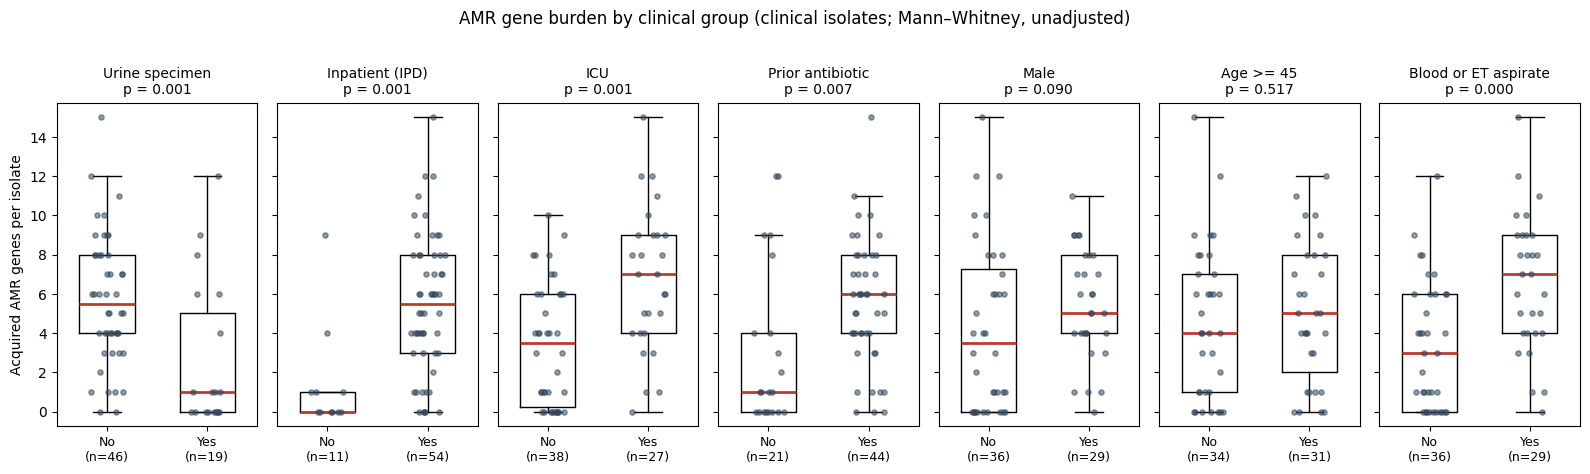

In [ ]:
# --- load gene presence/absence (rows = gene groups, columns = <isolate>_assembly)
g = pd.read_csv(BASE + GENE_MATRIX, low_memory=False)
gc = list(g.columns[5:])
ids = [x.replace("_assembly", "") for x in gc]
X = pd.DataFrame(g[gc].values.T.astype(np.int8), index=ids, columns=g["Gene"].values)
X = X.loc[:, ~X.columns.duplicated()]
amrmap = g.loc[g["Known AMR Gene"].notna()].drop_duplicates("Gene").set_index("Gene")["Known AMR Gene"]

# --- clinical table, keep isolates that have a genome
c = pd.read_excel(BASE + CLINICAL)
c = c.rename(columns={c.columns[0]: "iso"})
c["iso"] = c.iso.astype(str).str.strip()
c = c[c.iso.isin(X.index)].set_index("iso")
print(len(c), "clinical isolates with a genome")

# --- AMR gene burden per isolate (leave out genes carried by almost every isolate)
SKIP = {"oqxB", "Klebsiella_pneumoniae_OmpK37", "CrcB", "Mrx"}
amr_cols = [k for k in amrmap.index if k in X.columns and amrmap[k] not in SKIP]
nA = X.loc[c.index, amr_cols].sum(axis=1).values

# --- clinical yes/no groups
cl = pd.DataFrame(index=c.index)
cl["Urine specimen"]        = c["Specimen type"].eq("Urine")
cl["Inpatient (IPD)"]       = c["Treatment received from"].eq("IPD")
cl["ICU"]                   = c["Department"].eq("ICU")
cl["Prior antibiotic"]      = c["Treated with antibiotic"].eq(1)
cl["Male"]                  = c["Sex"].eq("Male")
cl["Age >= 45"]             = c["Age"].ge(45)
cl["Blood or ET aspirate"]  = c["Specimen type"].isin(["Blood", "Endotracheal aspirate"])

# --- plot
rng = np.random.default_rng(1)
fig, axs = plt.subplots(1, len(cl.columns), figsize=(16, 4.6), sharey=True)
for ax, v in zip(axs, cl.columns):
    y = cl[v].values
    d = [nA[~y], nA[y]]
    ax.boxplot(d, widths=.55, showfliers=False, medianprops=dict(color="#c0392b", lw=2))
    for i, a in enumerate(d, 1):
        ax.scatter(i + rng.uniform(-.17, .17, len(a)), a, s=14, color="#34495e", alpha=.55, zorder=3)
    p = stats.mannwhitneyu(d[0], d[1]).pvalue
    ax.set_xticks([1, 2]); ax.set_xticklabels([f"No\n(n={len(d[0])})", f"Yes\n(n={len(d[1])})"], fontsize=9)
    ax.set_title(f"{v}\np = {p:.3f}", fontsize=10)
axs[0].set_ylabel("Acquired AMR genes per isolate")
fig.suptitle("AMR gene burden by clinical group (clinical isolates; Mann–Whitney, unadjusted)", y=1.02)
fig.tight_layout()
fig.savefig(BASE + "fig_amr_burden_by_clinical_group.png", dpi=200, bbox_inches="tight")
plt.show()

# Cell 3: Figure 2, moderate and strong biofilm by source (307 isolates)

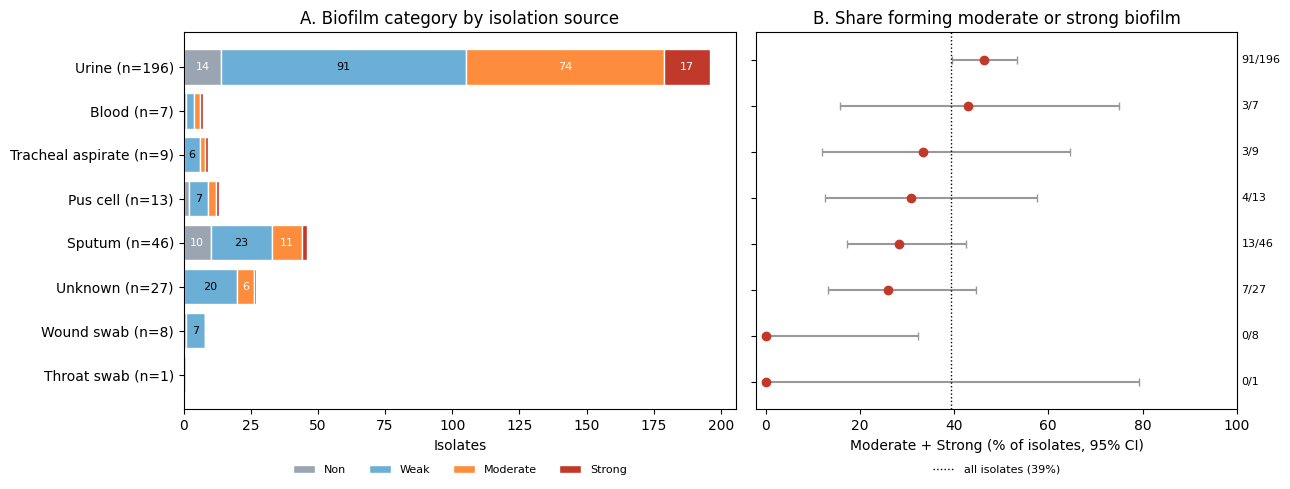

In [ ]:
d = pd.read_csv(BASE + ANALYSIS)
d["Source"] = d.Source.str.replace("Swab", "swab")

ct = pd.crosstab(d.Source, d.cat_final)[["Non", "Weak", "Moderate", "Strong"]]
ct["n"]   = ct.sum(axis=1)
ct["ms"]  = ct.Moderate + ct.Strong
ct["pct"] = ct.ms / ct.n

def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z*z/n
    c0 = (p + z*z/(2*n)) / den
    h = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n)) / den
    return c0 - h, c0 + h
ct[["lo", "hi"]] = [wilson(k, n) for k, n in zip(ct.ms, ct.n)]
ct = ct.sort_values("pct")

ms_all = d.cat_final.isin(["Moderate", "Strong"])
col = {"Non": "#9aa5b1", "Weak": "#6baed6", "Moderate": "#fd8d3c", "Strong": "#c0392b"}
y = np.arange(len(ct))

fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.15, 1]})

# A: counts by category
left = np.zeros(len(ct))
for k in ["Non", "Weak", "Moderate", "Strong"]:
    ax[0].barh(y, ct[k], left=left, color=col[k], label=k, edgecolor="white")
    for yi, (v, l) in enumerate(zip(ct[k], left)):
        if v >= 6:
            ax[0].text(l + v/2, yi, int(v), ha="center", va="center", fontsize=8,
                       color="white" if k != "Weak" else "black")
    left += ct[k].values
ax[0].set_yticks(y); ax[0].set_yticklabels([f"{s} (n={n})" for s, n in zip(ct.index, ct.n)])
ax[0].set_xlabel("Isolates")
ax[0].legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12), frameon=False)
ax[0].set_title("A. Biofilm category by isolation source")

# B: share moderate + strong with 95% CI
ax[1].errorbar(ct.pct*100, y, xerr=[(ct.pct-ct.lo)*100, (ct.hi-ct.pct)*100],
               fmt="o", color="#c0392b", ecolor="#999", capsize=3)
ax[1].axvline(ms_all.mean()*100, color="k", ls=":", lw=1,
              label=f"all isolates ({ms_all.mean()*100:.0f}%)")
ax[1].set_xlim(-2, 100); ax[1].set_ylim(-.6, len(ct) - .4)
for yi, (k, n) in enumerate(zip(ct.ms, ct.n)):          # k/n labels in the right margin
    ax[1].text(1.01, yi, f"{k}/{n}", transform=ax[1].get_yaxis_transform(), va="center", fontsize=8)
ax[1].set_yticks(y); ax[1].set_yticklabels([])
ax[1].set_xlabel("Moderate + Strong (% of isolates, 95% CI)")
ax[1].legend(loc="upper center", bbox_to_anchor=(.5, -.12), frameon=False, fontsize=8)
ax[1].set_title("B. Share forming moderate or strong biofilm")

fig.tight_layout()
fig.savefig(BASE + "fig_moderate_strong_by_source.png", dpi=200, bbox_inches="tight")
plt.show()

# Cell 4 (optional): is the urine difference just the plates?

In [ ]:
u  = (d.Source == "Urine").values
ms = ms_all.values

# unadjusted: urine vs all other sources
tab = [[(u & ms).sum(), (u & ~ms).sum()], [(~u & ms).sum(), (~u & ~ms).sum()]]
print("unadjusted OR, p:", stats.fisher_exact(tab))

def cmh(strata):
    S = V = 0; ORn = ORd = 0
    for s in np.unique(strata):
        i = strata == s; n = i.sum(); n1 = u[i].sum(); m = ms[i].sum()
        if n < 2 or n1 in (0, n) or m in (0, n): continue
        a  = (u[i] & ms[i]).sum();  b  = (u[i] & ~ms[i]).sum()
        c_ = (~u[i] & ms[i]).sum(); d_ = (~u[i] & ~ms[i]).sum()
        S += a - n1*m/n; V += n1*(n-n1)*m*(n-m)/(n**2*(n-1))
        ORn += a*d_/n; ORd += b*c_/n
    return stats.chi2.sf((abs(S) - .5)**2 / V, 1), ORn/ORd

for name in ["Trial", "TrialPlate"]:
    p, orr = cmh(d[name].values)
    print(f"adjusted for {name}: OR = {orr:.2f}, p = {p:.3f}")

unadjusted OR, p: SignificanceResult(statistic=np.float64(2.34), pvalue=np.float64(0.0009931122610898004))
adjusted for Trial: OR = 2.16, p = 0.005
adjusted for TrialPlate: OR = 1.57, p = 0.181


## Prophages with source

In [ ]:
import pandas as pd, numpy as np, sys, json
from scipy import stats
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import os

# Point directories to the local Colab content directory
D = "/content/"
OUT = "/content/results_prophages_source/"
os.makedirs(OUT, exist_ok=True)

rng = np.random.default_rng(7)

# Use files present in the local workspace
p = pd.read_excel(D + "Prophageanalysis.xlsx", sheet_name="intact_prophages"); p["Sample"] = p.Sample.astype(str)
# Since 'amr_in_prophage' or a separate sheet might not exist in this workbook, we fall back gracefully or read from intact_prophages
try:
    amrp = pd.read_excel(D + "Prophageanalysis.xlsx", sheet_name="amr_in_prophage")
    amrp["sample"] = amrp["sample"].astype(str)
except Exception:
    # Fallback if the sheet is missing: create empty DataFrame with the required column
    amrp = pd.DataFrame(columns=["sample"])

# Fallback to alternative metadata filename if MRC_metadata_526samples (1).xlsx is missing
metadata_file = "MRC_metadata_526samples (1).xlsx"
if not os.path.exists(D + metadata_file):
    metadata_file = "ClinicalKlebsiellaMetadata.xlsx"

m = pd.read_excel(D + metadata_file)
# Automatically resolve the correct isolate ID column name
isolate_col = "isolate" if "isolate" in m.columns else (m.columns[0] if len(m.columns) > 0 else "isolate")
m = m.rename(columns={isolate_col: "isolate"})
m["isolate"] = m["isolate"].astype(str).str.strip()
m = m.set_index("isolate")

p["ph"] = p.phage.str.replace("PHAGE_", "", regex=False)
iso = p.drop_duplicates("Sample").set_index("Sample")
mic = [c for c in iso.columns if c.startswith("MIC_")]
df = iso[["ST Type"] + mic].copy()
bad = df[mic].apply(pd.to_numeric, errors="coerce").isna().any(axis=1); dropped = list(df.index[bad]); df = df[~bad].copy()
df["ST"] = df["ST Type"].astype(str).str.replace(r"-\d*LV$", "", regex=True)

# Map source if the column exists in the metadata
source_col = "Source" if "Source" in m.columns else ("Specimen type" if "Specimen type" in m.columns else None)
if source_col:
    sr = m.loc[df.index.intersection(m.index), source_col].astype(str).str.strip().str.lower()
    df["Source"] = sr.map({"urine": "Urine", "sputum": "Respiratory", "tracheal aspirate": "Respiratory", "throat swab": "Respiratory", "wound swab": "Wound/pus", "pus cell": "Wound/pus", "blood": "Blood", "unknown": "Unknown"})
else:
    df["Source"] = "Unknown"

# resistance breakpoints (assumed CLSI-style; MIC >= value = resistant)
BP = {"CRO": 4, "FEP": 16, "TZP": 32, "AMC": 32, "ETP": 2, "MEM": 4, "IPM": 4, "GM": 16, "CIP": 1, "SXT": 80, "CS": 4, "TGC": 8, "AN": 64}
R = pd.DataFrame({k: (df["MIC_" + k].astype(float) >= v).astype(int) for k, v in BP.items()}, index=df.index)
cls = {"Cephalosporin": ["CRO", "FEP"], "Carbapenem": ["ETP", "MEM", "IPM"], "Aminoglycoside": ["GM", "AN"], "Fluoroquinolone": ["CIP"], "SXT": ["SXT"], "Penicillin/BLI": ["AMC", "TZP"]}
ncls = sum((R[v].sum(axis=1) > 0).astype(int) for v in cls.values()); R["MDR"] = (ncls >= 3).astype(int)
bp_tab = pd.DataFrame({"drug": list(BP), "R_if_MIC>=": list(BP.values()), "n_R": [int(R[k].sum()) for k in BP], "n_S": [int((1 - R[k]).sum()) for k in BP]})
bp_tab.to_csv(OUT + "/breakpoints_used.csv", index=False)

# prophage presence/absence (types), burden
pres = pd.crosstab(p.Sample, p.ph).clip(upper=1).reindex(df.index).fillna(0).astype(int)
df["n_prophages"] = p.groupby("Sample").size().reindex(df.index); df["n_types"] = pres.sum(axis=1)
df["amr_in_prophage"] = df.index.isin(set(amrp["sample"])).astype(int)

def bh(x):
    x = np.asarray(x, float); o = np.argsort(x); n = len(x); q = x[o] * n / np.arange(1, n + 1); q = np.minimum.accumulate(q[::-1])[::-1]; r = np.empty(n); r[o] = np.minimum(q, 1); return r

def cmh(a, b, strata):
    S = V = 0.0
    for s in np.unique(strata):
        i = strata == s; n = i.sum()
        if n < 2: continue
        n1 = a[i].sum(); m_ = b[i].sum()
        if n1 in (0, n) or m_ in (0, n): continue
        S += (a[i] & b[i]).sum() - n1 * m_ / n; V += n1 * (n - n1) * m_ * (n - m_) / (n**2 * (n - 1))
    return 1.0 if V == 0 else float(stats.chi2.sf((max(abs(S) - .5, 0))**2 / V, 1))

res = {"dropped_unreadable_MIC": dropped, "n_isolates": len(df), "n_with_source_known": int((df.Source != "Unknown").sum()), "n_ST_groups": int(df.ST.nunique()), "n_ST_groups_ge2": int((df.ST.value_counts() >= 2).sum()),
     "sources": df.Source.value_counts().to_dict(), "n_prophage_types": int(pres.shape[1])}

In [ ]:

# ---- A: source x AST
S4=df[df.Source.isin(["Urine","Respiratory","Wound/pus","Blood"])]
arows=[]
for k in list(BP)+["MDR"]:
    if R.loc[S4.index,k].sum()<10: continue
    t=pd.crosstab(S4.Source,R.loc[S4.index,k]); chi2,pv,_,_=stats.chi2_contingency(t)
    pct=R.loc[S4.index].groupby(S4.Source)[k].mean()
    arows.append(dict(drug=k,**{f"%R {s}":round(100*pct[s],1) for s in pct.index},chi2_p=pv))
A=pd.DataFrame(arows); A["q"]=bh(A.chi2_p); A.to_csv(OUT+"/source_vs_resistance.csv",index=False)

In [ ]:

# ---- B: source x prophage
idx=S4.index; src=S4.Source.values
bur=S4.groupby("Source")[["n_prophages","n_types"]].median(); res["burden_median_by_source"]=bur.to_dict()
res["KW_n_prophages_source_p"]=float(stats.kruskal(*[S4.n_prophages[S4.Source==s] for s in S4.Source.unique()]).pvalue)
Pm=pres.loc[idx]; fr=Pm.mean(); keep=Pm.columns[(fr>=.05)&(fr<=.95)]; Pm=Pm[keep].values.astype(float)
groups=np.unique(src); G=np.stack([(src==g) for g in groups],1).astype(float)
def chi_stats(lab_mat,M):
    n=M.shape[0]; f=M.mean(0); cnt=lab_mat.T@M; ng=lab_mat.sum(0)[:,None]
    return (((cnt-ng*f)**2)/np.maximum(ng*f*(1-f),1e-9)).sum(0)
obs=chi_stats(G,Pm); st=S4.ST.values
def perm_p(strat):
    nperm=4000; ge=np.zeros(len(obs));
    ix_by={s:np.where(st==s)[0] for s in np.unique(st)} if strat else {"all":np.arange(len(src))}
    for _ in range(nperm):
        s2=src.copy()
        for ii in ix_by.values():
            if len(ii)>1: s2[ii]=rng.permutation(src[ii])
        G2=np.stack([(s2==g) for g in groups],1).astype(float); ge+=(chi_stats(G2,Pm)>=obs-1e-9)
    return (ge+1)/(nperm+1)
pu=perm_p(False); pa=perm_p(True)
Bt=pd.DataFrame(dict(phage=keep,freq=Pm.mean(0)))
for gi,g in enumerate(groups): Bt[f"freq_{g}"]=Pm[src==g].mean(0)
Bt["perm_p"]=pu; Bt["perm_q"]=bh(pu); Bt["ST_strat_perm_p"]=pa; Bt["ST_strat_perm_q"]=bh(pa); Bt=Bt.sort_values("perm_p"); Bt.to_csv(OUT+"/source_vs_prophage_types.csv",index=False)
res["B_types_tested"]=len(keep); res["B_q05_unadj"]=int((Bt.perm_q<.05).sum()); res["B_q05_STstrat"]=int((Bt.ST_strat_perm_q<.05).sum())

In [ ]:

# ---- C: prophage x AST
Pa=pres.loc[df.index]; fa=Pa.mean(); keepa=Pa.columns[(fa>=.05)&(fa<=.95)]; stt=df.ST.values
crow=[]
drugs=[k for k in list(BP)+["MDR"] if 10<=R[k].sum()<=len(R)-10]
for dgr in drugs:
    y=R[dgr].values==1
    for ph in keepa:
        x=Pa[ph].values==1; t=[[(x&y).sum(),(x&~y).sum()],[(~x&y).sum(),(~x&~y).sum()]]
        o,pf=stats.fisher_exact(t); crow.append(dict(drug=dgr,phage=ph,freq=x.mean(),n_both=int((x&y).sum()),R_with=(x&y).sum()/max(x.sum(),1),R_without=(~x&y).sum()/max((~x).sum(),1),OR=o,fisher_p=pf,cmh_ST_p=cmh(x,y,stt)))
C=pd.DataFrame(crow); C["fisher_q"]=bh(C.fisher_p); C["cmh_q"]=bh(C.cmh_ST_p); C=C.sort_values("fisher_p"); C.to_csv(OUT+"/prophage_vs_resistance.csv",index=False)
res["C_tests"]=len(C); res["C_fisher_q05"]=int((C.fisher_q<.05).sum()); res["C_cmh_q05"]=int((C.cmh_q<.05).sum()); res["C_both_q05"]=int(((C.fisher_q<.05)&(C.cmh_q<.05)).sum())
# burden vs R
brow=[]
for dgr in drugs:
    y=R[dgr].values==1; a=df.n_prophages.values
    rho=stats.spearmanr(a,df["MIC_"+dgr].astype(float).values if dgr!="MDR" else R.MDR.values)
    brow.append(dict(drug=dgr,median_prophages_R=float(np.median(a[y])),median_prophages_S=float(np.median(a[~y])),MWU_p=stats.mannwhitneyu(a[y],a[~y]).pvalue))
Bb=pd.DataFrame(brow); Bb["q"]=bh(Bb.MWU_p); Bb.to_csv(OUT+"/prophage_burden_vs_resistance.csv",index=False)
# AMR gene inside prophage by source / MDR
t=pd.crosstab(S4.Source,S4.amr_in_prophage); res["amr_in_prophage_by_source"]={s:f"{t.loc[s,1]}/{t.loc[s].sum()}" for s in t.index}; res["amr_in_prophage_source_p"]=float(stats.chi2_contingency(t)[1])
res["amr_in_prophage_MDR"]=[float(df.amr_in_prophage[R.MDR==1].mean()),float(df.amr_in_prophage[R.MDR==0].mean()),float(stats.fisher_exact(pd.crosstab(df.amr_in_prophage,R.MDR).values)[1])]
res["MDR_rate"]=float(R.MDR.mean())


In [ ]:
# ---- Figures
order=["Urine","Respiratory","Wound/pus","Blood"]
fig=plt.figure(figsize=(16,5.6)); gs=fig.add_gridspec(1,3,width_ratios=[1,.8,1.35])
ax=fig.add_subplot(gs[0]); drA=[k for k in list(BP)+["MDR"] if R.loc[S4.index,k].sum()>=10]
H=np.array([[100*R.loc[S4.index][S4.Source==s][k].mean() for s in order] for k in drA])
im=ax.imshow(H,cmap="YlOrRd",vmin=0,vmax=100,aspect="auto"); ax.set_xticks(range(4)); ax.set_xticklabels([f"{s}\n(n={int((S4.Source==s).sum())})" for s in order],fontsize=8)
ax.set_yticks(range(len(drA))); ax.set_yticklabels(drA,fontsize=9)
for i in range(H.shape[0]):
    for j in range(4): ax.text(j,i,f"{H[i,j]:.0f}",ha="center",va="center",fontsize=7,color="white" if H[i,j]>60 else "black")
qd=dict(zip(A.drug,A.q));
for i,k in enumerate(drA):
    if k in qd and qd[k]<.05: ax.text(3.62,i,"*",va="center",fontsize=11,color="#c0392b",clip_on=False)
ax.set_title("A. Resistant isolates (%) by source\n(* = differs by source, q < 0.05)",fontsize=10)
ax=fig.add_subplot(gs[1]); d_=[S4.n_prophages[S4.Source==s].values for s in order]
ax.boxplot(d_,widths=.55,showfliers=False,medianprops=dict(color="#c0392b",lw=2))
for i,a in enumerate(d_,1): ax.scatter(i+rng.uniform(-.18,.18,len(a)),a,s=7,color="#34495e",alpha=.35)
ax.set_xticks(range(1,5)); ax.set_xticklabels(order,fontsize=8,rotation=20); ax.set_ylabel("Intact prophages per isolate")
ax.set_title(f"B. Prophage burden by source\n(Kruskal–Wallis p = {res['KW_n_prophages_source_p']:.2f})",fontsize=10)
ax=fig.add_subplot(gs[2]); top=Bt.assign(f=Bt.freq).sort_values("f",ascending=False).head(16).phage.tolist()
H2=np.array([[100*pres.loc[S4.index][S4.Source==s][ph].mean() for s in order] for ph in top])
im2=ax.imshow(H2,cmap="Blues",vmin=0,aspect="auto"); ax.set_xticks(range(4)); ax.set_xticklabels(order,fontsize=8); ax.set_yticks(range(len(top))); ax.set_yticklabels(top,fontsize=7)
for i in range(H2.shape[0]):
    for j in range(4): ax.text(j,i,f"{H2[i,j]:.0f}",ha="center",va="center",fontsize=7,color="white" if H2[i,j]>H2.max()*.6 else "black")
ax.set_title("C. Isolates carrying each prophage type (%) by source\n(16 most common types)",fontsize=10)
fig.tight_layout(); fig.savefig(OUT+"/fig_prophage_source_ast_1.png",dpi=200)
# fig 2: prophage x drug OR heatmap
types=C.groupby("phage").fisher_p.min().sort_values().index[:20]; dr=[d for d in drugs]
L=np.full((len(types),len(dr)),np.nan); Q=np.ones_like(L); Qc=np.ones_like(L)
for i,ph in enumerate(types):
    for j,d in enumerate(dr):
        r=C[(C.phage==ph)&(C.drug==d)].iloc[0]; L[i,j]=np.log2((r.R_with+.01)/(r.R_without+.01)) if False else np.log2(max(r.OR,1e-2)) if np.isfinite(r.OR) else 4; Q[i,j]=r.fisher_q; Qc[i,j]=r.cmh_q
fig,ax=plt.subplots(figsize=(10,7.2)); im=ax.imshow(np.clip(L,-3,3),cmap="RdBu_r",vmin=-3,vmax=3,aspect="auto")
ax.set_xticks(range(len(dr))); ax.set_xticklabels(dr,fontsize=9); ax.set_yticks(range(len(types))); ax.set_yticklabels(types,fontsize=8)
for i in range(len(types)):
    for j in range(len(dr)):
        if Q[i,j]<.05: ax.text(j,i,"**" if Qc[i,j]<.05 else "*",ha="center",va="center",fontsize=12)
cb=plt.colorbar(im,ax=ax,fraction=.035); cb.set_label("log2 odds ratio (prophage present vs absent)")
ax.set_title("Prophage type vs resistance (20 types with the lowest p)\n* q < 0.05 unadjusted;  ** also q < 0.05 within ST strata",fontsize=10)
fig.tight_layout(); fig.savefig(OUT+"/fig_prophage_source_ast_2.png",dpi=200)
json.dump(res,open(OUT+"/summary.json","w"),indent=1,default=str); print(json.dumps(res,indent=1,default=str))
print(bp_tab.to_string()); print(A.round(3).to_string()); print(Bt.head(8).round(4).to_string()); print(C.head(14).round(4).to_string()); print(Bb.round(4).to_string())

{
 "dropped_unreadable_MIC": [
  "7537v2"
 ],
 "n_isolates": 514,
 "n_with_source_known": 514,
 "n_ST_groups": 179,
 "n_ST_groups_ge2": 77,
 "sources": {
  "Urine": 19,
  "Wound/pus": 17,
  "Blood": 7
 },
 "n_prophage_types": 80,
 "burden_median_by_source": {
  "n_prophages": {
   "Blood": 4.0,
   "Urine": 4.0,
   "Wound/pus": 4.0
  },
  "n_types": {
   "Blood": 3.0,
   "Urine": 4.0,
   "Wound/pus": 4.0
  }
 },
 "KW_n_prophages_source_p": 0.6817992102360066,
 "B_types_tested": 20,
 "B_q05_unadj": 0,
 "B_q05_STstrat": 0,
 "C_tests": 273,
 "C_fisher_q05": 67,
 "C_cmh_q05": 5,
 "C_both_q05": 5,
 "amr_in_prophage_by_source": {
  "Blood": "1/7",
  "Urine": "2/19",
  "Wound/pus": "4/17"
 },
 "amr_in_prophage_source_p": 0.5662425515537337,
 "amr_in_prophage_MDR": [
  0.26262626262626265,
  0.08860759493670886,
  1.9751361043871383e-07
 ],
 "MDR_rate": 0.3852140077821012
}
   drug  R_if_MIC>=  n_R  n_S
0   CRO           4  275  239
1   FEP          16  240  274
2   TZP          32  139  375
3 